**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# StockEye v6 · `% vacío` desde una máscara, sin bordes manuales

**Objetivo:** medir el `% vacío` por góndola y por repisa en fotos desordenadas, sin que nadie dibuje bordes en producción.

**Idea central:** un modelo pinta cada píxel como **0 fondo, 1 ocupado o 2 vacío**.
- Góndola = ocupado ∪ vacío.
- `% vacío` = vacío / (ocupado + vacío).
- Las repisas se derivan después. Si el corte no es confiable, se informa solo la góndola.

**Cómo correrlo:** `Entorno de ejecución → T4 GPU`, y luego `Ejecutar todo`. Si Colab se desconecta, al volver a ejecutar todo el entrenamiento sigue desde el último checkpoint en Drive.

**Necesita en `MyDrive/stockeye_v5/`:** `dataset_gondolas_2026-10-13.zip`, `etiquetas_finales/F5_etiquetas.json` y, si existe, `etiquetas_finales/split_v3.json`. Si las etiquetas incluyen fotos externas (`ext_*`), también `externas_prep/` y `etiquetas_finales/externas.json`. Opcional: `modelos/vigente.pt`, para comparar con v5.

**Escribe en `MyDrive/stockeye_v6/`.** No modifica nada de v5.

## Principios (para pasarlo a `.py`)
- **Cada parte** tiene objetivo, entradas, salidas, decisiones y validación.
- **Las celdas de código** definen funciones con tipos y terminan con una llamada corta. La celda de validación falla si algo está mal.
- **Configuración y rutas** viven solo en la Parte 1.
- **Sin estado oculto:** corre de arriba abajo, y cada etapa lee y escribe archivos.
- **Strategy:** todo modelo cumple `Segmentador.mapa(img)`; la evaluación no sabe cuál es.

| Parte | Tema | Futuro `.py` |
|---|---|---|
| 1 | Entorno y configuración | `config.py` |
| 2 | Datos y splits | `datos.py` |
| 3 | Máscaras y auditoría | `mascaras.py` |
| 4 | Entrenamiento | `entrenar.py` |
| 5 | Predicción por modos | `inferir.py` |
| 6 | De máscara a `% vacío` | `metricas_stock.py` |
| 7 | Evaluación | `evaluar.py` |
| 8 | Comparación con v5 | `evaluar.py` |
| 9 | Compuerta de promoción | `reentrenar.py` |
| 10 | Analizar una foto nueva | `inferir.py` |
| 11 | Subir fotos y reentrenar | `reentrenar.py` |

## Experimentos con repisas muy vacías
En `[1.2]`, la línea `EXPERIMENTO` elige qué correr. Corre primero `e1_vacias` y, cuando termine, `e2_recall`. Cada uno usa su carpeta `entrenamiento/<experimento>/`, así que no pisa el modelo anterior.

| Experimento | Qué cambia |
|---|---|
| `base` | Modelo original; no usa las fotos nuevas para entrenar |
| `e1_vacias` | Agrega las fotos de `vacias_extremas/` y un zoom mínimo menor |
| `e2_recall` | Además, pérdida Tversky y umbral elegido por F2 |

Necesita en `MyDrive/stockeye_v6/vacias_extremas/`: `imagenes/`, `manifiesto.csv` y `etiquetas/*.json` (COCO). Las 6 fotos de examen nunca se usan para entrenar.


**Texto corregido — documentación vigente del código actual.**

# StockEye v6 corregido · YOLO26, SegFormer, evaluación e inferencia

Copia corregida del notebook v6. **No incorpora API ni listener.** El v6 original y las salidas antiguas se conservan.

La segmentación distingue `0 fondo`, `1 ocupado`, `2 vacío` y `255 ignorar`. El porcentaje mide área de imagen: no equivale a unidades de inventario. El conteo de vacíos informa **regiones conexas**, no productos faltantes ni huecos físicos individuales.

**Antes de ejecutar:** revisa rutas y experimentos en `[1.2]`. Por defecto `ENTRENAR` y el examen están activos; si solo quieres reevaluar pesos existentes, desactiva `ENTRENAR`. El `.pt` debe corresponder al tipo de modelo del experimento. Necesita el dataset, `F5_etiquetas.json`, los insumos externos si están habilitados y los archivos de `vacias_extremas/`. Los pesos y algunas etiquetas originales no se adjuntan a esta corrección.

**Salidas nuevas:** `MyDrive/stockeye_v6/corregido_v1/`. Los checkpoints viejos solo pueden importarse para reevaluar; no se reanudan bajo reglas nuevas. Colab debe permanecer conectado y ejecutándose para procesar o entrenar.

**Separación de datos:** train aprende; dev selecciona pesos/modo/umbral; val decide promociones repetidas; examen es una evaluación final explícita. Val ya no se presenta como examen independiente. Mantén un futuro conjunto independiente de tienda para comprobar la generalización.

Ejecuta de arriba abajo. Los interruptores para entrenar, examen final, comparación v5, probar fotos, ingresar fotos, reentrenar y exportar son explícitos. El perfil `prueba` es para verificar ejecución, no para reportar calidad.

| Parte | Resultado |
|---|---|
| 1–3 | Configuración, datos, particiones y máscaras verificadas |
| 4–6 | Entrenamiento reproducible y selección en dev con restricciones |
| 7–8 | Evaluación corregida, análisis del último modelo y comparación opcional |
| 9 | Promoción y carga del contexto vigente |
| 10–11 | Inferencia, artefactos y reentrenamiento controlado |
| 12 | Exportación de módulo Python sin servidor HTTP |

**Experimento vigente `y1` (YOLO26):** entrena YOLO26-seg con etiquetas corregidas y lo compara con `e1_vacias` en las mismas fotos. Necesita `stockeye_v6/revision_etiquetas.json` en Drive. SegFormer queda como referencia. `m1` está definido, pero no se ha entrenado y necesita además `stockeye_v6/void_kaggle/etiquetas/zonas_dudosas.json`.

**Limitaciones:** las repisas usan una heurística de bordes; su referencia de evaluación también es automática. Góndolas que se tocan pueden formar un solo componente semántico. Para identificar muebles físicos, configura ROI calibradas o entrena un modelo de instancias. Las pseudoetiquetas reflejan lo que el modelo cree; no proporcionan una evaluación independiente ni garantizan mejoras.

**Actualización de insumos (31-10-2026):** se conservan las 187 imágenes propias y las 70 externas. Si faltan sus archivos preparados o las etiquetas actualizadas, usa la restauración opcional `[2.0]` con `StockEye_insumos_recuperados.zip`. Este es un paquete de datos; el ZIP de código/documentación sigue siendo opcional.


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 1 · Entorno y configuración
- **Objetivo:** dejar GPU, Drive, dependencias, semillas y parámetros listos.
- **Salidas:** `CFG`, `RUTAS`, `DEVICE`.
- **Decisiones:** `PERFIL="completo"` es el normal. `PERFIL="prueba"` usa pocas fotos y una época: solo sirve para comprobar que el código corre, y sus métricas no significan nada.
- **Validación:** en Colab exige GPU.

**Texto corregido — documentación vigente del código actual.**

# Parte 1 · Entorno, configuración y utilidades

Instala dependencias faltantes y monta Drive en Colab. Puede verificarse en CPU; el tiempo y la VRAM deben medirse en el equipo real de despliegue. `max_ram_gb=None` significa que aún no se fijó un presupuesto de RAM.

Los mínimos de promoción, tolerancias, precisión y recursos son **valores técnicos iniciales configurables**, pendientes de validación con el cliente. Un modo que incumple las restricciones no se elige automáticamente.


In [ ]:
# [1.1] Entorno y dependencias; no inicia ningún servidor
import importlib.util, importlib.metadata, os, subprocess, sys

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

REQUISITOS = {
    "numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3",
    "cv2": "opencv-python-headless>=4.10,<6", "matplotlib": "matplotlib>=3.8,<4",
    "torch": "torch>=2.6,<3", "transformers": "transformers==4.57.6",
    "safetensors": "safetensors>=0.4,<1", "psutil": "psutil>=5.9,<8",
    "ultralytics": "ultralytics==8.4.197", "albumentations": "albumentations>=1.4.22,<3",
}
faltantes = [r for m, r in REQUISITOS.items() if importlib.util.find_spec(m) is None]
try:
    if importlib.metadata.version("transformers") != "4.57.6" and "transformers==4.57.6" not in faltantes:
        faltantes.append("transformers==4.57.6")
except importlib.metadata.PackageNotFoundError:
    pass
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    try: gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
    except FileNotFoundError: gpu = ""
    print("GPU:", gpu or "sin GPU; selecciona T4 para entrenar")


Mounted at /content/drive
GPU: Tesla T4, 15360 MiB


In [ ]:
# [1.2] Configuración; salidas corregidas separadas de las anteriores
import contextlib, hashlib, inspect, json, math, random, re, shutil, tempfile, time, uuid, zipfile
from collections import defaultdict
from dataclasses import asdict, dataclass, fields, replace
from datetime import datetime, timezone
from pathlib import Path
from typing import Protocol

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from transformers import SegformerConfig, SegformerForSemanticSegmentation

PIPELINE_VERSION = "stockeye-v6-corregido-1"
METRICAS_VERSION = "stockeye-metricas-2"
FONDO, OCUPADO, VACIO, IGNORAR = 0, 1, 2, 255
NO_VACIO = 254  # solo en train: se sabe que no es vacío, pero no si es producto o fondo

@dataclass(frozen=True)
class Config:
    semilla: int = 42
    limite_fotos: int | None = None
    frac_dev: float = 0.12
    exigir_series_separadas: bool = True
    exigir_manifest_escenas: bool = False
    usar_externas: bool = True
    modelo_base: str = "nvidia/mit-b1"
    epocas: int = 60
    muestras_por_foto: int = 4
    crop: int = 768
    escala: tuple = (0.7, 1.8)
    prob_centrar_vacio: float = 0.5
    batch: int = 6
    lr: float = 6e-5
    weight_decay: float = 0.01
    eval_cada: int = 5
    paciencia_evals: int = 6
    workers: int = 2
    lado_completa: int = 1280
    tile: int = 640
    solape: float = 0.25
    modos: tuple = ("completa", "tta", "mosaicos", "mosaicos+tta")
    umbrales_vacio: tuple = (0.3, 0.4, 0.5, 0.6)
    tiempo_max_s: float = 5.0
    max_vram_inferencia_gb: float | None = 2.0
    max_vram_entrenamiento_gb: float | None = 14.0
    max_ram_gb: float | None = None
    max_pixeles_imagen: int = 20_000_000
    cierre_frac: float = 0.015
    area_min_gondola: float = 0.01
    cobertura_min_roi: float = 0.80
    area_min_vacio_px: int = 16
    margen_borde_px: int = 3
    iou_emparejar: float = 0.30
    alto_rectificado: int = 800
    repisa_min: float = 0.10
    prominencia_min_bordes: float = 0.005
    stock_verde: float = 70.0
    stock_rojo: float = 30.0
    n_bootstrap: int = 1000
    rangos_vacio: tuple = (0, 10, 30, 70, 100)
    conf_pseudo: float = 0.85
    min_etiquetado: float = 0.60
    min_fotos_reentreno: int = 10
    repetir_nuevas: int = 3
    epocas_reentreno: int = 15
    lr_reentreno: float = 2e-5
    eval_cada_reentreno: int = 3
    repetir_vacias: int = 0
    perdida_recall: bool = False
    tversky_alfa: float = 0.3
    tversky_beta: float = 0.7
    criterio_umbral: str = "iou"
    min_precision: float = 0.40
    franja_min_ancho: float = 0.30
    min_fotos_validacion: int = 10
    min_iou_promocion: float = 0.15
    min_recall_promocion: float = 0.30
    min_recall_alertas_promocion: float = 0.30
    min_cobertura_promocion: float = 0.50
    tolerancia_proporcion: float = 0.01
    tolerancia_mae_pp: float = 0.5
    min_metricas_mejoran: int = 4
    exigir_revision_pseudo: bool = True
    pseudo_como_ignorar: bool = False
    lr_cabezal_mult: float = 1.0
    ema_decay: float = 0.0
    tolerancia_borde_px: int = 5
    cuota_void_kaggle: float = 0.0
    recortes_por_epoca: int = 0
    f4_como_vacio: bool = False
    kaggle_negativos: bool = False
    aumento_fuerte: bool = False
    revision_etiquetas: bool = False
    modelo_tipo: str = "segformer"
    modelo_yolo: str = "yolo26s-seg.pt"
    batch_yolo: int = -1  # -1: Ultralytics lo calcula según la memoria de la GPU
    paciencia_yolo: int = 20
    conf_gondola: float = 0.25
    corregir_etiquetas: bool = False

_CON_VACIAS = dict(repetir_vacias=4, escala=(0.35, 1.8))
_X0 = dict(_CON_VACIAS, pseudo_como_ignorar=True, lr_cabezal_mult=10.0, ema_decay=0.999)
_D1 = dict(_X0, cuota_void_kaggle=0.25, recortes_por_epoca=1040)
EXPERIMENTOS = {
    "base": {}, "e1_vacias": _CON_VACIAS,
    "e2_recall": dict(_CON_VACIAS, perdida_recall=True, criterio_umbral="f2", umbrales_vacio=(0.1,0.2,0.3,0.4,0.5,0.6)),
    "x0": _X0,
    "d1": _D1,
    "m1": dict(_D1, f4_como_vacio=True, kaggle_negativos=True, aumento_fuerte=True, revision_etiquetas=True,
               paciencia_evals=3, umbrales_vacio=(0.3, 0.4, 0.5, 0.6, 0.7, 0.8)),
    "y1": dict(modelo_tipo="yolo", repetir_vacias=4, f4_como_vacio=True, corregir_etiquetas=True, epocas=60, max_vram_inferencia_gb=None,
               umbrales_vacio=(0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6)),
}
EXPERIMENTO = os.environ.get("SV6_EXPERIMENTO", "y1")
PERFIL = os.environ.get("SV6_PERFIL", "completo")
CFG = replace(Config(), **EXPERIMENTOS[EXPERIMENTO])
if os.name == "nt":
    CFG = replace(CFG, workers=0)
if PERFIL == "prueba":
    CFG = replace(CFG, limite_fotos=24, epocas=1, muestras_por_foto=1, crop=256, batch=2, workers=0,
                  lado_completa=384, tile=256, eval_cada=1, n_bootstrap=50,
                  min_fotos_reentreno=2, epocas_reentreno=1, eval_cada_reentreno=1,
                  recortes_por_epoca=min(CFG.recortes_por_epoca,40),modelo_yolo="yolo26n-seg.pt",batch_yolo=2)

# False permite reevaluar los pesos previos sin reentrenar. Si no hay pesos, pon True.
ENTRENAR = os.environ.get("SV6_ENTRENAR", "1") == "1" #0: para no entrenar
REGENERAR_SPLIT = os.environ.get("SV6_REGENERAR_SPLIT", "0") == "1"
EJECUTAR_EXAMEN_FINAL = os.environ.get("SV6_EXAMEN_FINAL", "1") == "1"

BASE_DRIVE = Path("/content/drive/MyDrive") if EN_COLAB else Path(os.environ.get("SV6_BASE", "."))
V5 = Path(os.environ.get("SV5_DRIVE", BASE_DRIVE / "stockeye_v5"))
V6 = Path(os.environ.get("SV6_DRIVE", BASE_DRIVE / "stockeye_v6"))
SALIDA = V6 / "corregido_v1"
LOCAL = Path("/content/sv6_corregido") if EN_COLAB else Path(os.environ.get("SV6_LOCAL", "sv6_local_corregido"))
CARPETA_EXP = SALIDA / "entrenamiento" / EXPERIMENTO
RUTAS = dict(
    zip_dataset=V5/"dataset_gondolas_2026-10-13.zip", externas=V5/"externas_prep",
    etiquetas=V5/"etiquetas_finales/F5_etiquetas.json", etiquetas_externas=V5/"etiquetas_finales/externas.json",
    split_v3=V5/"etiquetas_finales/split_v3.json", pesos_v5=V5/"modelos/vigente.pt",
    split_v6=V6/"split_v6.json", escenas=V6/"escenas.csv",
    checkpoint=CARPETA_EXP/"last.pt", mejor=CARPETA_EXP/"run"/"weights"/"best_vacio.pt" if CFG.modelo_tipo=="yolo" else CARPETA_EXP/"best.pt", historial=CARPETA_EXP/"historial.csv",
    mejor_anterior=V6/"entrenamiento"/("" if EXPERIMENTO=="base" else EXPERIMENTO)/"best.pt",
    vacias=V6/"vacias_extremas", void_kaggle=V6/"void_kaggle", revision=V6/"revision_etiquetas.json", resultados=SALIDA/"resultados", modelos=SALIDA/"modelos",
    nuevas=SALIDA/"nuevas", reentrenos=SALIDA/"reentrenos", dataset=LOCAL/"dataset", mascaras=LOCAL/"mascaras", dataset_yolo=LOCAL/"ds_yolo",
)
for ruta in (V6, SALIDA, CARPETA_EXP, RUTAS["resultados"], RUTAS["modelos"], LOCAL):
    ruta.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
def fijar_semillas(semilla):
    random.seed(semilla); np.random.seed(semilla); torch.manual_seed(semilla)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(semilla)
fijar_semillas(CFG.semilla)
print(f"{PIPELINE_VERSION} | experimento={EXPERIMENTO} | perfil={PERFIL} | dispositivo={DEVICE}")
print("Entrenar:", ENTRENAR, "| examen final (no promueve):", EJECUTAR_EXAMEN_FINAL, "| salidas:", SALIDA)


stockeye-v6-corregido-1 | experimento=y1 | perfil=completo | dispositivo=cuda
Entrenar: True | examen final (no promueve): True | salidas: /content/drive/MyDrive/stockeye_v6/corregido_v1


In [ ]:
# [1.3] Validación, persistencia y recursos compartidos
def json_seguro(obj):
    if isinstance(obj, dict): return {str(k): json_seguro(v) for k,v in obj.items()}
    if isinstance(obj, (list, tuple)): return [json_seguro(v) for v in obj]
    if isinstance(obj, Path): return str(obj)
    if isinstance(obj, np.ndarray): return json_seguro(obj.tolist())
    if isinstance(obj, np.generic): return json_seguro(obj.item())
    if isinstance(obj, float) and not math.isfinite(obj): return None
    return obj

def json_canonico(obj):
    return json.dumps(json_seguro(obj), ensure_ascii=False, sort_keys=True, separators=(",",":"), allow_nan=False)

def huella_json(obj):
    return hashlib.sha256(json_canonico(obj).encode("utf-8")).hexdigest()

def sha_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta,"rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024*1024), b""): h.update(bloque)
    return h.hexdigest()

def guardar_json(obj, ruta):
    ruta = Path(ruta); ruta.parent.mkdir(parents=True, exist_ok=True)
    fd, temporal = tempfile.mkstemp(prefix=ruta.stem+"_", suffix=".tmp", dir=ruta.parent)
    try:
        with os.fdopen(fd,"w",encoding="utf-8") as f:
            json.dump(json_seguro(obj), f, ensure_ascii=False, indent=2, allow_nan=False)
            f.flush(); os.fsync(f.fileno())
        os.replace(temporal, ruta)
    finally:
        if os.path.exists(temporal): os.unlink(temporal)

def guardar_csv(df, ruta):
    ruta = Path(ruta); ruta.parent.mkdir(parents=True,exist_ok=True)
    fd, temporal = tempfile.mkstemp(suffix=".csv.tmp",dir=ruta.parent); os.close(fd)
    try:
        df.to_csv(temporal,index=False); os.replace(temporal,ruta)
    finally:
        if os.path.exists(temporal): os.unlink(temporal)

@contextlib.contextmanager
def bloqueo(ruta):
    ruta=Path(ruta); ruta.parent.mkdir(parents=True,exist_ok=True)
    try: fd=os.open(ruta,os.O_CREAT|os.O_EXCL|os.O_WRONLY)
    except FileExistsError:
        raise RuntimeError(f"Hay otra operación o un bloqueo pendiente: {ruta}. Verifica el proceso antes de retirar ese archivo.")
    try:
        with os.fdopen(fd,"w") as f: f.write(str(os.getpid()))
        yield
    finally:
        ruta.unlink(missing_ok=True)

def validar_config(cfg):
    for campo in fields(cfg):
        valor=getattr(cfg,campo.name)
        if isinstance(valor,float) and not math.isfinite(valor): raise ValueError("Parámetro no finito: "+campo.name)
    if not (0 <= cfg.stock_rojo < cfg.stock_verde <= 100): raise ValueError("Umbrales de stock inválidos")
    if not 0 <= cfg.solape < 1 or int(cfg.tile*(1-cfg.solape)) < 1: raise ValueError("Mosaicos sin paso válido")
    if cfg.batch < 1 or cfg.epocas < 1 or cfg.crop < 32 or cfg.muestras_por_foto < 1: raise ValueError("Configuración de entrenamiento inválida")
    if not 0 < cfg.area_min_gondola < 1 or not 0 < cfg.repisa_min < 1: raise ValueError("Geometría inválida")
    if not 0<cfg.cobertura_min_roi<=1: raise ValueError("Cobertura mínima de ROI inválida")
    if not 0 < cfg.conf_pseudo <= 1 or not 0 < cfg.min_etiquetado <= 1: raise ValueError("Selección de pseudoetiquetas inválida")
    if any(not 0 < u < 1 for u in cfg.umbrales_vacio): raise ValueError("Umbrales de vacío inválidos")
    if not cfg.modos or set(cfg.modos)-{"completa","tta","mosaicos","mosaicos+tta"}: raise ValueError("Modos de inferencia inválidos")
    if cfg.criterio_umbral not in ("iou","f2"): raise ValueError("Criterio de umbral desconocido")
    if cfg.tiempo_max_s<=0 or cfg.n_bootstrap<1 or cfg.eval_cada<1 or cfg.workers<0: raise ValueError("Límites de ejecución inválidos")
    if cfg.lr<=0 or cfg.lr_reentreno<=0 or len(cfg.escala)!=2 or not 0<cfg.escala[0]<=cfg.escala[1]: raise ValueError("Aprendizaje/escala inválidos")
    if not 0<cfg.frac_dev<1 or not 0<=cfg.min_precision<=1: raise ValueError("Proporción o precisión inválida")
    if cfg.min_fotos_validacion<1 or not 1<=cfg.min_metricas_mejoran<=8 or cfg.tolerancia_proporcion<0 or cfg.tolerancia_mae_pp<0:
        raise ValueError("Compuerta inválida")
    if not 0<=cfg.cuota_void_kaggle<1 or cfg.recortes_por_epoca<0 or (cfg.cuota_void_kaggle and not cfg.recortes_por_epoca): raise ValueError("Cuotas de entrenamiento inválidas")
    if cfg.kaggle_negativos and not cfg.cuota_void_kaggle: raise ValueError("kaggle_negativos requiere las fotos de Kaggle")
    if cfg.modelo_tipo not in ("segformer","yolo"): raise ValueError("Tipo de modelo desconocido")
    if cfg.modelo_tipo=="yolo" and (cfg.cuota_void_kaggle or cfg.revision_etiquetas or cfg.pseudo_como_ignorar): raise ValueError("YOLO no tiene IGNORAR: usa corregir_etiquetas y, por ahora, sin Kaggle")
    if cfg.batch_yolo==0 or cfg.batch_yolo<-1 or cfg.paciencia_yolo<1 or not 0<cfg.conf_gondola<1: raise ValueError("Ajustes de YOLO inválidos")
    if cfg.lr_cabezal_mult<=0 or not 0<=cfg.ema_decay<1 or cfg.tolerancia_borde_px<0: raise ValueError("Ajustes de x0 inválidos")
    for k in ("max_vram_inferencia_gb","max_vram_entrenamiento_gb","max_ram_gb"):
        if getattr(cfg,k) is not None and getattr(cfg,k)<=0: raise ValueError("Presupuesto de memoria inválido: "+k)
    return cfg

def config_desde_dict(datos):
    conocidos={f.name for f in fields(Config)}
    desconocidos=set(datos)-conocidos
    if desconocidos: raise ValueError(f"Parámetros de otra versión del pipeline: {sorted(desconocidos)}")
    valores=dict(datos)
    for k in ("escala","modos","umbrales_vacio","rangos_vacio"):
        if k in valores: valores[k]=tuple(valores[k])
    return validar_config(Config(**valores))

def leer_imagen(ruta, cfg=None):
    img=cv2.imread(str(ruta),cv2.IMREAD_COLOR)
    if img is None or img.ndim != 3: raise ValueError(f"Imagen ilegible: {ruta}")
    if cfg and img.shape[0]*img.shape[1] > cfg.max_pixeles_imagen:
        raise ValueError(f"Imagen demasiado grande ({img.shape[1]}×{img.shape[0]}). Ajusta explícitamente max_pixeles_imagen.")
    return img

def escribir_imagen(ruta, img):
    ruta=Path(ruta); ruta.parent.mkdir(parents=True,exist_ok=True)
    if not cv2.imwrite(str(ruta),img): raise OSError(f"No se pudo escribir {ruta}")

def huella_pixeles(ruta):
    img=leer_imagen(ruta)
    return hashlib.sha256(str(img.shape).encode()+img.tobytes()).hexdigest()

def snapshot_datos(fotos, pesos=None):
    filas=[]
    for f in fotos:
        mascara=ruta_mascara(f)
        filas.append(dict(nombre=f["nombre"], split=f["split"], repetir=f.get("repetir",1),
                          imagen=sha_archivo(f["ruta"]), mascara=sha_archivo(mascara)))
    info=dict(pipeline=PIPELINE_VERSION, fotos=sorted(filas,key=lambda f:(f["nombre"],f["split"])))
    if pesos is not None: info["pesos_clase"]=pesos.detach().cpu().tolist()
    return huella_json(info)

def dispositivo_de(modelo):
    return next(modelo.parameters()).device

def sincronizar_cuda(modelo=None):
    if torch.cuda.is_available() and (modelo is None or dispositivo_de(modelo).type=="cuda"):
        torch.cuda.synchronize()

def recursos_actuales():
    try: rss=psutil.Process().memory_info().rss
    except (psutil.Error,OSError):
        # Algunos contenedores exponen /proc con un espacio de PID distinto; self mantiene la referencia correcta.
        try: rss=int(Path("/proc/self/statm").read_text().split()[1])*os.sysconf("SC_PAGE_SIZE")
        except (OSError,ValueError,IndexError) as error: raise RuntimeError("No se pudo medir la memoria del proceso") from error
    return dict(ram_gb=rss/1024**3,
                vram_gb=torch.cuda.max_memory_allocated()/1024**3 if torch.cuda.is_available() else 0.0)

def comprobar_recursos(cfg, entrenamiento=False):
    r=recursos_actuales()
    limite=cfg.max_vram_entrenamiento_gb if entrenamiento else cfg.max_vram_inferencia_gb
    if limite is not None and r["vram_gb"] > limite:
        raise RuntimeError(f"VRAM {r['vram_gb']:.2f} GB > {limite} GB. Reduce batch/crop o cambia la configuración y crea otra ejecución.")
    if cfg.max_ram_gb is not None and r["ram_gb"] > cfg.max_ram_gb: raise RuntimeError("Se excedió el límite de RAM")
    return r

validar_config(CFG)


Config(semilla=42, limite_fotos=None, frac_dev=0.12, exigir_series_separadas=True, exigir_manifest_escenas=False, usar_externas=True, modelo_base='nvidia/mit-b1', epocas=60, muestras_por_foto=4, crop=768, escala=(0.7, 1.8), prob_centrar_vacio=0.5, batch=6, lr=6e-05, weight_decay=0.01, eval_cada=5, paciencia_evals=6, workers=2, lado_completa=1280, tile=640, solape=0.25, modos=('completa', 'tta', 'mosaicos', 'mosaicos+tta'), umbrales_vacio=(0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6), tiempo_max_s=5.0, max_vram_inferencia_gb=None, max_vram_entrenamiento_gb=14.0, max_ram_gb=None, max_pixeles_imagen=20000000, cierre_frac=0.015, area_min_gondola=0.01, cobertura_min_roi=0.8, area_min_vacio_px=16, margen_borde_px=3, iou_emparejar=0.3, alto_rectificado=800, repisa_min=0.1, prominencia_min_bordes=0.005, stock_verde=70.0, stock_rojo=30.0, n_bootstrap=1000, rangos_vacio=(0, 10, 30, 70, 100), conf_pseudo=0.85, min_etiquetado=0.6, min_fotos_reentreno=10, repetir_nuevas=3, epocas_reentreno=15, l

**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 2 · Datos y splits
- **Objetivo:** cargar fotos y etiquetas, y fijar tres grupos: `train` (aprende), `dev` (elige modelo, modo y umbral) y `val` (examen final).
- **Entradas:** zip del dataset, `F5_etiquetas.json`, `split_v3.json` si existe.
- **Salidas:** `FOTOS`, `split_v6.json`.
- **Decisiones:**
  - Las series van completas a un solo grupo. Fotos casi iguales en train y val inflarían las métricas.
  - **`dev` es nuevo:** v5 elegía umbrales en el mismo val, lo que hace sus cifras algo optimistas.
  - **Train usa solo vacíos humanos**, porque el dataset con pseudo-etiquetas de F4 rindió peor. Val usa los humanos y los de F4 revisados.
  - **Las fotos externas (`ext_*`) van siempre a train** (regla de la Fase 4b de v5): el examen y `dev` solo usan fotos propias. Sus etiquetas se leen de `externas.json` si `F5_etiquetas.json` las trae vacías. Sus vacíos se conservan: los dudosos los revisó una persona y los seguros los aceptó el modelo de v5. Con `usar_externas=False` se entrena sin ellas.
  - **Si no hay un `split_v3.json` limpio, se genera** con la regla y semilla de la celda 5.0 de v5. Un split guardado que reparta series se reemplaza.
  - **Las fotos de `vacias_extremas/` no pasan por el split automático:** `manifiesto.csv` fija cuáles son de train y cuáles de `examen`. Así `split_v6.json` no cambia y los experimentos siguen siendo comparables.
- **Validación:** detiene el notebook si una serie queda repartida entre grupos.

**Texto corregido — documentación vigente del código actual.**

# Parte 2 · Datos y particiones estables

Se conserva el split guardado si es válido. Un cambio en nombres o grupos detiene la ejecución. `REGENERAR_SPLIT=True` permite crear uno nuevo con copia de respaldo; no debe activarse para mejorar resultados de evaluación.

Opcional: `stockeye_v6/escenas.csv` con columnas `nombre,escena`, agrupando fotos de la misma cámara, góndola y sesión. Sin ese manifiesto, se usa una agrupación provisional por nombres/minutos, que **no demuestra independencia entre escenas**. `exigir_manifest_escenas=True` exige el manifiesto para una evaluación formal. Se detectan duplicados exactos por bytes y píxeles; las tomas parecidas requieren revisión.

**Retail Shelf Void Detection (experimento `d1`):** 192 escenas de Kaggle, licencia CC BY-NC-SA, solo en train. `convertir_void_kaggle.py` deja una foto por escena y convierte sus cajas en máscaras con SAM, sin etiquetado manual. Sube `void_kaggle/` a `MyDrive/stockeye_v6/`. En `d1`, todo lo que no es vacío queda en `IGNORAR`, así que esas fotos solo enseñan "esto es vacío": subieron el recall y bajaron la precisión. En 60 de esas fotos, `d1` marcó como vacío dos tercios del área fuera de cajas, incluidos piso y filas llenas. Con `kaggle_negativos` (experimento `m1`), lo que queda fuera de las cajas enseña "esto no es vacío", sin decir si es producto o fondo. Las cajas originales y las esquinas negras de la rotación siguen fuera, y necesitan `etiquetas/zonas_dudosas.json`. Se asume que las cajas marcan los vacíos de la foto; en una muestra de 12 fotos se ven bastante completas, pero no todas.

**Revisión de etiquetas:** `revision_etiquetas.json` lista zonas donde `e1` o `d1` discrepan de la etiqueta y una revisión a ciegas, sin saber quién decía qué, las encontró erróneas o dudosas. Cubre el 85 % del área en discrepancia en val y dev, y el 60 % en las fotos propias de train.
- **SegFormer (`m1`):** esas zonas pasan a `IGNORAR` en train y dev.
- **YOLO (`y1`):** no tiene `IGNORAR`, así que se corrigen solo las zonas claras en train y dev: se suma el vacío real y se quita el falso. Las dudosas no cambian.
- **Val:** no cambia aquí. Su versión revisada se mide aparte en `[7.7]`.

**Limitación:** la revisión no reemplaza a un anotador humano independiente, y las externas y extremas no se revisaron.

**Vacíos F4:** con `f4_como_vacio` (`m1` e `y1`), los F4 de train y dev cuentan como vacío, igual que en val. En `F4_vacios_nuevos.json`, una persona aprobó 139 de los 149 de train; los otros 10 son de confianza alta sin revisar. El campo `revisado` de `F5_etiquetas.json` no distingue estos casos, porque la limpieza de v5 lo deja siempre en verdadero.

Externas solo en train. El manifiesto de vacías extremas mantiene train y examen separados. Con `pseudo_como_ignorar` (experimento `x0`), los vacíos propuestos por F4 pasan a `IGNORAR` en train y dev en vez de contarse como `ocupado`; val no cambia.

**Recuperación de las 70 externas:** `[2.0]` instala las fotografías preparadas y los JSON actualizados en `V5`, conservando el split original y respaldando los archivos anteriores que sean diferentes. El paquete se reconstruyó desde `externas.zip` usando la normalización original de v5; las anotaciones revisadas no se vuelven a generar. El conjunto principal debe contener 257 nombres: 199 train, 18 dev y 40 val. Las vacías extremas se añaden por separado.

Para una primera restauración ejecuta `[1.1]`, `[1.2]` y `[1.3]`, cambia `RESTAURAR_INSUMOS=True` en `[2.0]`, ejecútala y selecciona únicamente el ZIP de insumos. Después vuelve a `False` y ejecuta `[2.1]`.


In [ ]:
# [2.0] Restauración opcional de insumos; conserva el split y respalda archivos previos
"""Restauración local de insumos verificados. No entrena ni modifica el split."""
def restaurar_insumos(paquete,destino,ruta_split):
    import contextlib,hashlib,json,os,shutil,tempfile,uuid,zipfile
    from datetime import datetime,timezone
    from pathlib import Path,PurePosixPath

    paquete,destino,ruta_split=map(Path,(paquete,destino,ruta_split))
    if not ruta_split.is_file(): raise FileNotFoundError("Falta el split original: "+str(ruta_split))
    contenido_split=ruta_split.read_bytes();split=json.loads(contenido_split)
    sha=lambda b:hashlib.sha256(b).hexdigest()
    with zipfile.ZipFile(paquete) as z:
        if len(z.namelist())!=len(set(z.namelist())): raise ValueError("ZIP con entradas repetidas")
        doc=json.loads(z.read("MANIFIESTO_RECUPERACION.json"))
        if doc.get("esquema")!="stockeye-insumos-1": raise ValueError("Paquete de insumos incompatible")
        archivos=doc.get("archivos",{})
        requeridos={"etiquetas_finales/externas.json","etiquetas_finales/F5_etiquetas.json"}
        if not requeridos<=set(archivos): raise ValueError("Paquete sin las etiquetas necesarias")
        datos={}
        for nombre,esperado in archivos.items():
            p=PurePosixPath(nombre)
            if p.is_absolute() or ".." in p.parts or "\\" in nombre or len(p.parts)!=2:
                raise ValueError("Ruta insegura en el paquete")
            permitido=(p.parts[0]=="externas_prep" and (p.suffix.lower()==".jpg" or p.name=="LICENCIA.txt")) or (nombre in requeridos or nombre=="etiquetas_finales/externas_decisiones.csv")
            if not permitido: raise ValueError("Archivo ajeno a los insumos de recuperación: "+nombre)
            if nombre not in z.namelist(): raise ValueError("Paquete incompleto: falta "+nombre)
            b=z.read(nombre)
            if sha(b)!=esperado: raise ValueError("Contenido alterado o incompleto: "+nombre)
            datos[nombre]=b
    f5=json.loads(datos["etiquetas_finales/F5_etiquetas.json"])
    ext=json.loads(datos["etiquetas_finales/externas.json"])
    esperadas={n for n in split if n.startswith("ext_")}
    if set(ext)!=esperadas: raise ValueError("Las externas del paquete no coinciden con las del split; no se instala")
    if any(split[n]!="train" for n in esperadas): raise ValueError("Una externa está fuera de train")
    if set(f5)|set(ext)!=set(split): raise ValueError("Las etiquetas no cubren exactamente los nombres del split")
    imagenes={"externas_prep/"+n for n in ext}
    if {n for n in datos if n.endswith(".jpg")}!=imagenes: raise ValueError("Faltan imágenes externas o hay imágenes adicionales")
    for n,e in ext.items():
        if e.get("W",0)<=0 or e.get("H",0)<=0 or not e.get("gondolas"):
            raise ValueError("Etiqueta externa inválida: "+n)
    destino.mkdir(parents=True,exist_ok=True)
    base=destino.resolve()
    for nombre in datos:
        if not (destino/nombre).resolve().is_relative_to(base): raise ValueError("Un enlace de destino sale de la carpeta del proyecto")
    lock=destino/".restauracion_insumos.lock"
    try: fd=os.open(lock,os.O_CREAT|os.O_EXCL|os.O_WRONLY)
    except FileExistsError: raise RuntimeError("Hay una restauración en curso o un bloqueo pendiente: "+str(lock))
    os.close(fd)
    sello=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+"_"+uuid.uuid4().hex[:6]
    respaldo=destino/"respaldos_insumos"/sello
    instalados=[];iguales=[];respaldados=[]
    try:
        # Fotografías primero; etiquetas al final. Un archivo previo diferente se respalda antes de reemplazarlo.
        orden=sorted(datos,key=lambda n:(n.startswith("etiquetas_finales/"),n=="etiquetas_finales/F5_etiquetas.json",n))
        for nombre in orden:
            ruta=destino/nombre;b=datos[nombre]
            if ruta.exists() and sha(ruta.read_bytes())==sha(b): iguales.append(nombre);continue
            if ruta.exists():
                copia=respaldo/nombre;copia.parent.mkdir(parents=True,exist_ok=True)
                shutil.copy2(ruta,copia);respaldados.append(nombre)
            ruta.parent.mkdir(parents=True,exist_ok=True)
            temporal=None
            try:
                fd,temporal=tempfile.mkstemp(prefix=ruta.stem+"_",suffix=".tmp",dir=ruta.parent)
                with os.fdopen(fd,"wb") as f: f.write(b);f.flush();os.fsync(f.fileno())
                os.replace(temporal,ruta);instalados.append(nombre)
            finally:
                if temporal and os.path.exists(temporal): os.unlink(temporal)
        if ruta_split.read_bytes()!=contenido_split: raise RuntimeError("El split cambió durante la restauración; revisa el proceso que lo modificó")
        for nombre,b in datos.items():
            if sha((destino/nombre).read_bytes())!=sha(b): raise OSError("Fallo de verificación de copia: "+nombre)
    finally:
        lock.unlink(missing_ok=True)
    return dict(estado="OK",externas=len(ext),nombres_totales=len(set(f5)|set(ext)),archivos_instalados=len(instalados),
                archivos_ya_identicos=len(iguales),archivos_respaldados=respaldados,
                carpeta_respaldo=str(respaldo) if respaldados else None,split_modificado=False,destino=str(destino))


RESTAURAR_INSUMOS = False
if RESTAURAR_INSUMOS:
    ruta_paquete = os.environ.get("SV6_PAQUETE_INSUMOS")
    if not ruta_paquete and EN_COLAB:
        from google.colab import files
        subidos = files.upload()
        if len(subidos) != 1: raise ValueError("Selecciona únicamente StockEye_insumos_recuperados.zip")
        ruta_paquete = next(iter(subidos))
    if not ruta_paquete:
        raise ValueError("Indica SV6_PAQUETE_INSUMOS con la ruta al ZIP de insumos recuperados")
    INFORME_RESTAURACION = restaurar_insumos(ruta_paquete, V5, RUTAS["split_v6"])
    print(json.dumps(INFORME_RESTAURACION, ensure_ascii=False, indent=2))
else:
    print("Restauración desactivada. Actívala una vez si faltan externas_prep o las etiquetas actualizadas.")


Restauración desactivada. Actívala una vez si faltan externas_prep o las etiquetas actualizadas.


In [ ]:
# [2.1] Datos y splits explícitos; no se reemplaza un split sin autorización del interruptor
NATIVA_RE = re.compile(r"IMG_(\d{8})_(\d{4})", re.I)
WHATSAPP_RE = re.compile(r"IMG-(\d{8})-WA(\d{4})", re.I)
GRUPOS_ESCENA = {}
if RUTAS["escenas"].exists():
    _escenas=pd.read_csv(RUTAS["escenas"],dtype=str)
    if not {"nombre","escena"} <= set(_escenas): raise ValueError("escenas.csv necesita nombre y escena")
    if _escenas["nombre"].duplicated().any() or _escenas[["nombre","escena"]].isna().any().any(): raise ValueError("Manifiesto de escenas ambiguo")
    GRUPOS_ESCENA=dict(zip(_escenas["nombre"],_escenas["escena"]))

def serie_de(nombre):
    if nombre in GRUPOS_ESCENA: return "escena_"+GRUPOS_ESCENA[nombre]
    if nombre.startswith("ext_"): return "externa_"+nombre
    if m:=NATIVA_RE.search(nombre): return f"nat_{m[1]}_{m[2]}"
    if m:=WHATSAPP_RE.search(nombre): return f"wa_{m[1]}_{int(m[2])//5}"
    return "otra_"+nombre

def es_externa(nombre): return nombre.startswith("ext_")

def series_compartidas(splits):
    grupos=defaultdict(set)
    for nombre,split in splits.items(): grupos[serie_de(nombre)].add(split)
    return sorted(g for g,s in grupos.items() if len(s)>1)

def preparar_imagenes(ruta_zip,destino):
    destino=Path(destino); destino.mkdir(parents=True,exist_ok=True)
    huella=sha_archivo(ruta_zip)
    final=destino/huella[:16]
    if not (final/".completo").exists():
        if final.exists(): raise RuntimeError(f"Extracción incompleta: {final}; revísala antes de repetir")
        temporal=Path(tempfile.mkdtemp(prefix="extraer_",dir=destino))
        try:
            with zipfile.ZipFile(ruta_zip) as z:
                for n in z.namelist():
                    if not (temporal/n).resolve().is_relative_to(temporal.resolve()): raise ValueError("Ruta inválida dentro del ZIP")
                z.extractall(temporal)
            clases=list(temporal.glob("**/classes.txt"))
            if len(clases)!=1 or not (clases[0].parent/"images").is_dir(): raise ValueError("El ZIP no contiene una carpeta images y classes.txt inequívocos")
            (temporal/".completo").write_text(huella)
            temporal.rename(final)
        finally:
            if temporal.exists(): shutil.rmtree(temporal)
    return next(final.glob("**/classes.txt")).parent/"images"

def split_por_series(nombres,semilla,frac_val=0.20,min_val=30,min_grupos_train=1):
    grupos=defaultdict(list)
    for n in nombres: grupos[serie_de(n)].append(n)
    pares=sorted(grupos.items())
    if len(pares)<=min_grupos_train: raise ValueError("No hay escenas suficientes para separar las particiones")
    np.random.default_rng(semilla).shuffle(pares)
    objetivo=min(len(nombres)-1,max(min_val,round(frac_val*len(nombres))))
    val=set();cantidad=0
    for grupo,ns in pares[:-min_grupos_train]:
        if cantidad>=objetivo: break
        val.add(grupo);cantidad+=len(ns)
    return {n:"val" if serie_de(n) in val else "train" for n in nombres}

def completar_externas(etiquetas,ruta):
    if not Path(ruta).exists(): return 0
    cantidad=0
    for nombre,e in json.loads(Path(ruta).read_text()).items():
        actual=etiquetas.get(nombre)
        if actual is None or not (actual["gondolas"] or actual["vacios"]):
            etiquetas[nombre]=dict(split="train",W=e["W"],H=e["H"],gondolas=e["gondolas"],vacios=[dict(puntos=v["puntos"],origen="externa",revisado=True) for v in e["vacios"]])
            cantidad+=1
    return cantidad

def validar_split(split,etiquetas):
    if set(split)!=set(etiquetas): raise ValueError("El split no corresponde a los nombres del dataset")
    if set(split.values())!={"train","dev","val"}: raise ValueError("Se necesitan train, dev y val no vacíos")
    if series_compartidas(split): raise ValueError("Hay escenas compartidas entre splits")
    if any(split[n]!="train" for n in split if es_externa(n)): raise ValueError("Una foto externa quedó fuera de train")
    return split

def asignar_splits(etiquetas,ruta_v3,ruta_v6,cfg):
    propias=sorted(n for n in etiquetas if not es_externa(n))
    sin_manifest=set(propias)-set(GRUPOS_ESCENA)
    if sin_manifest:
        mensaje=f"Faltan IDs de escena/cámara/sesión para {len(sin_manifest)} fotos propias; se usan grupos temporales provisionales. No demuestra independencia de escenas."
        if cfg.exigir_manifest_escenas: raise ValueError(mensaje)
        print("AVISO:",mensaje)
    ruta_v6=Path(ruta_v6)
    if ruta_v6.exists():
        guardado=json.loads(ruta_v6.read_text())
        try: return validar_split(guardado,etiquetas)
        except ValueError as error:
            if not REGENERAR_SPLIT: raise ValueError(f"{error}. No se cambia {ruta_v6}. Corrige escenas o activa REGENERAR_SPLIT explícitamente.") from error
            respaldo=ruta_v6.with_name(ruta_v6.stem+"_respaldo_"+uuid.uuid4().hex[:8]+".json")
            shutil.copy2(ruta_v6,respaldo)
    v3=json.loads(Path(ruta_v3).read_text()) if Path(ruta_v3).exists() else {}
    base={n:v3[n] for n in propias} if all(n in v3 for n in propias) else {}
    if not base or series_compartidas(base) or set(base.values())!={"train","val"}:
        base=split_por_series(propias,cfg.semilla,min_grupos_train=2)
    grupos=defaultdict(list)
    for n in propias:
        if base[n]=="train": grupos[serie_de(n)].append(n)
    orden=sorted(grupos)
    if len(orden)<2: raise ValueError("No hay escenas suficientes para reservar dev y conservar train")
    np.random.default_rng(cfg.semilla).shuffle(orden)
    objetivo=max(1,round(cfg.frac_dev*sum(map(len,grupos.values()))))
    dev=set()
    for grupo in orden[:-1]:
        dev.update(grupos[grupo])
        if len(dev)>=objetivo: break
    split={n:"train" if es_externa(n) else "dev" if n in dev else base[n] for n in etiquetas}
    validar_split(split,etiquetas);guardar_json(split,ruta_v6)
    return split

def cargar_fotos(etiquetas,splits,carpeta,carpeta_ext,cfg):
    fotos=[]
    for nombre,e in sorted(etiquetas.items()):
        split,ext=splits[nombre],es_externa(nombre)
        if ext and not cfg.usar_externas: continue
        # Casi todos los F4 de train los aprobó una persona (139 de 149 en F4_vacios_nuevos.json); val ya los cuenta.
        conservar=lambda v: ext or v.get("origen")=="humano" or (split=="val" and v.get("revisado")) or (cfg.f4_como_vacio and v.get("origen")=="f4" and split in ("train","dev"))
        vacios=[v["puntos"] for v in e["vacios"] if conservar(v)]
        # Un vacío propuesto sin confirmar no debe enseñar que ahí hay producto; val no cambia.
        dudosos=[v["puntos"] for v in e["vacios"] if not conservar(v)] if cfg.pseudo_como_ignorar and split in ("train","dev") else []
        fotos.append(dict(nombre=nombre,ruta=(carpeta_ext if ext else carpeta)/nombre,split=split,W=e["W"],H=e["H"],
                          gondolas=e["gondolas"],vacios=vacios,ocupados=e.get("ocupados",[]),ignorar=e.get("ignorar",[])+dudosos,
                          externa=ext,grupo_escena=serie_de(nombre)))
    if cfg.limite_fotos:
        fotos=sum(([f for f in fotos if f["split"]==s][:n] for s,n in [("train",cfg.limite_fotos//2),("dev",cfg.limite_fotos//4),("val",cfg.limite_fotos//4)]),[])
    return fotos

CLASES_VACIAS={"gondola":"gondolas","góndola":"gondolas","vacio":"vacios","vacío":"vacios","ocupado":"ocupados","ignorar":"ignorar","zona_dudosa":"dudosas"}

def leer_coco(carpeta):
    etiquetas={}
    for ruta in sorted(Path(carpeta).glob("*.json")):
        coco=json.loads(ruta.read_text());categorias={c["id"]:c["name"].strip().lower() for c in coco["categories"]}
        if set(categorias.values())-set(CLASES_VACIAS): raise ValueError(f"Clases desconocidas en {ruta}")
        imgs={i["id"]:i for i in coco["images"]}
        for a in coco["annotations"]:
            i=imgs[a["image_id"]];nombre=i["file_name"]
            if Path(nombre).name!=nombre: raise ValueError("El manifiesto debe contener nombres simples de imagen")
            e=etiquetas.setdefault(nombre,dict(W=i["width"],H=i["height"],gondolas=[],vacios=[],ocupados=[],ignorar=[],dudosas=[]))
            if (e["W"],e["H"])!=(i["width"],i["height"]): raise ValueError("Tamaños inconsistentes en COCO")
            if not isinstance(a["segmentation"],list): raise ValueError("Esta carga requiere polígonos COCO, no RLE")
            for s in a["segmentation"]:
                p=np.asarray(s,float)
                if len(p)<6 or len(p)%2 or not np.isfinite(p).all(): raise ValueError("Polígono COCO inválido")
                e[CLASES_VACIAS[categorias[a["category_id"]]]].append(p.reshape(-1,2).tolist())
    return etiquetas

def cargar_vacias(carpeta,cfg):
    carpeta=Path(carpeta)
    if not (carpeta/"manifiesto.csv").exists():
        if cfg.repetir_vacias: raise FileNotFoundError(f"Falta {carpeta}/manifiesto.csv")
        return []
    manifiesto=pd.read_csv(carpeta/"manifiesto.csv");etiquetas=leer_coco(carpeta/"etiquetas")
    if manifiesto["nombre"].duplicated().any(): raise ValueError("Nombres repetidos en manifiesto extremo")
    fotos=[]
    for _,m in manifiesto.iterrows():
        if m["grupo"] not in ("train","examen"): raise ValueError("Grupo extremo inválido")
        if m["grupo"]=="train" and cfg.repetir_vacias==0: continue
        if m["nombre"] not in etiquetas: raise ValueError(f"Faltan etiquetas para {m['nombre']}")
        e=etiquetas[m["nombre"]]
        if (e["W"],e["H"])!=(m["ancho"],m["alto"]) or not e["gondolas"] or not e["vacios"]: raise ValueError(f"Etiqueta extrema inconsistente: {m['nombre']}")
        fotos.append(dict(nombre=m["nombre"],ruta=carpeta/"imagenes"/m["nombre"],split=m["grupo"],W=e["W"],H=e["H"],
                          gondolas=e["gondolas"],vacios=e["vacios"],ocupados=e["ocupados"],ignorar=e["ignorar"],externa=False,
                          escena=m["escena"],grupo_escena="extrema_"+m["escena"],md5_origen=m["md5_origen"],es_extrema=True,repetir=max(1,cfg.repetir_vacias)))
    return fotos

def cargar_void_kaggle(carpeta,cfg):
    """Fotos con vacíos conocidos, solo en train. `parcial` deja el resto en IGNORAR; con `kaggle_negativos`, fuera de las cajas enseña que no es vacío."""
    if not cfg.cuota_void_kaggle: return []
    carpeta=Path(carpeta)
    if not (carpeta/"manifiesto.csv").exists(): raise FileNotFoundError(f"Falta {carpeta}/manifiesto.csv; sube void_kaggle a Drive")
    manifiesto=pd.read_csv(carpeta/"manifiesto.csv");etiquetas=leer_coco(carpeta/"etiquetas");fotos=[]
    if cfg.limite_fotos: manifiesto=manifiesto.head(cfg.limite_fotos//2)
    if cfg.kaggle_negativos and not any(e["dudosas"] for e in etiquetas.values()): raise FileNotFoundError(f"Falta {carpeta}/etiquetas/zonas_dudosas.json; súbelo a Drive")
    for _,m in manifiesto.iterrows():
        e=etiquetas[m["nombre"]]
        fotos.append(dict(nombre=m["nombre"],ruta=carpeta/"imagenes"/m["nombre"],split="train",W=e["W"],H=e["H"],gondolas=[],vacios=e["vacios"],ocupados=[],
                          ignorar=e["ignorar"],externa=True,parcial=True,escena=m["escena"],grupo_escena="kaggle_"+m["escena"],md5_origen=m["md5_origen"],
                          negativos=cfg.kaggle_negativos,dudosas=e["dudosas"] if cfg.kaggle_negativos else []))
    return fotos

def leer_revision(ruta,dudosas=True):
    """Zonas revisadas a ciegas donde la etiqueta no coincide con lo que se ve. Sin `dudosas`, solo los errores claros."""
    doc=json.loads(Path(ruta).read_text())
    if doc.get("esquema")!="stockeye-revision-1": raise ValueError("Revisión de etiquetas incompatible")
    return {foto:[z for z in zonas if dudosas or z["clase"]=="error"] for foto,zonas in doc["zonas"].items()}

def aplicar_revision(fotos,cfg):
    """Solo train y dev. SegFormer excluye las zonas; YOLO, sin IGNORAR, corrige las claras. Val conserva sus etiquetas: la versión revisada se mide aparte en [7.7]."""
    if not (cfg.revision_etiquetas or cfg.corregir_etiquetas): return fotos
    if not RUTAS["revision"].exists(): raise FileNotFoundError(f"Falta {RUTAS['revision']}; sube revision_etiquetas.json a Drive")
    zonas=leer_revision(RUTAS["revision"],dudosas=cfg.revision_etiquetas);clave="excluir" if cfg.revision_etiquetas else "corregir"
    salida=[dict(f,**{clave:zonas.get(f["nombre"],[])}) if f["split"] in ("train","dev") else f for f in fotos]
    print("Zonas de etiqueta aplicadas en train y dev:",sum(len(f.get(clave,[])) for f in salida),f"({clave})")
    return salida

CARPETA_IMG=preparar_imagenes(RUTAS["zip_dataset"],RUTAS["dataset"])
ETIQUETAS=json.loads(RUTAS["etiquetas"].read_text())
print("Externas completadas:",completar_externas(ETIQUETAS,RUTAS["etiquetas_externas"]))
SPLITS=asignar_splits(ETIQUETAS,RUTAS["split_v3"],RUTAS["split_v6"],CFG)
FOTOS=aplicar_revision(cargar_fotos(ETIQUETAS,SPLITS,CARPETA_IMG,RUTAS["externas"],CFG)+cargar_vacias(RUTAS["vacias"],CFG)+cargar_void_kaggle(RUTAS["void_kaggle"],CFG),CFG)
print(pd.crosstab([f["split"] for f in FOTOS],["externa" if f["externa"] else "propia" for f in FOTOS]))


Externas completadas: 70
AVISO: Faltan IDs de escena/cámara/sesión para 187 fotos propias; se usan grupos temporales provisionales. No demuestra independencia de escenas.
Zonas de etiqueta aplicadas en train y dev: 200 (corregir)
col_0   externa  propia
row_0                  
dev           0      18
examen        0       6
train        70     144
val           0      40


In [ ]:
# [2.2] Validación de escenas, archivos y copias exactas
if series_compartidas(SPLITS): raise ValueError("Escenas compartidas entre train/dev/val")
if len({f["nombre"] for f in FOTOS})!=len(FOTOS): raise ValueError("Nombres de imagen repetidos entre datasets")
_grupos=defaultdict(set);_sha=defaultdict(set);_pix=defaultdict(set);_origen=defaultdict(set)
for f in FOTOS:
    img=leer_imagen(f["ruta"],CFG)
    if (img.shape[1],img.shape[0])!=(f["W"],f["H"]): raise ValueError(f"Dimensiones incorrectas: {f['nombre']}")
    f["sha256"]=sha_archivo(f["ruta"])
    _sha[f["sha256"]].add(f["split"])
    _pix[hashlib.sha256(str(img.shape).encode()+img.tobytes()).hexdigest()].add(f["split"])
    _origen[hashlib.md5(Path(f["ruta"]).read_bytes()).hexdigest()].add(f["split"])
    _grupos[f.get("grupo_escena",serie_de(f["nombre"]))].add(f["split"])
    if f.get("md5_origen"): _origen[f["md5_origen"]].add(f["split"])
for nombre,mapa in [("escenas",_grupos),("bytes",_sha),("píxeles",_pix),("origen extremo",_origen)]:
    if any(len(s)>1 for s in mapa.values()): raise ValueError(f"Cruce entre particiones por {nombre}")
if not {"train","dev","val"}<={f["split"] for f in FOTOS}: raise ValueError("Algún split está vacío")
if any(f["externa"] and f["split"]!="train" for f in FOTOS): raise ValueError("Externa fuera de train")
guardar_json(dict(pipeline=PIPELINE_VERSION,split_sha256=sha_archivo(RUTAS["split_v6"]),
                  escenas_provisionales=bool(set(n for n in ETIQUETAS if not es_externa(n))-set(GRUPOS_ESCENA)),
                  fotos=[dict(nombre=f["nombre"],split=f["split"],sha256=f["sha256"],grupo=f.get("grupo_escena")) for f in FOTOS]),
             RUTAS["resultados"]/"manifiesto_datos.json")
print("Datos y splits comprobados; no se han mezclado las fotos de examen con train.")


Datos y splits comprobados; no se han mezclado las fotos de examen con train.


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 3 · Máscaras y auditoría
- **Objetivo:** convertir polígonos en máscaras por píxel y revisar que representen bien la góndola.
- **Entradas:** `FOTOS`.
- **Salidas:** un PNG por foto, `PESOS_CLASE` y `auditoria_mascaras.png`.
- **Decisiones:** las góndolas dibujadas se usan **una sola vez, aquí**, para enseñar al modelo. En producción no se dibuja nada. Las fotos sin vacíos se conservan: enseñan qué es "lleno = 0 %". **Las fotos sin góndola ni vacíos se apartan**, porque están sin etiquetar y enseñarían que una repisa es fondo; si son más del 10 % de las fotos propias, el notebook se detiene.
- **Zonas `ocupado`:** productos sueltos dibujados sobre un vacío. Enseñan justo el caso difícil: un producto solo en una repisa vacía no es vacío.
- **Zonas `ignorar`:** logos, textos sobreimpresos y góndolas demasiado lejanas para dibujarlas. No cuentan como fondo ni como góndola, ni al entrenar ni al medir.
- **Validación:** mira la figura. Si la zona azul no cubre la góndola o el vacío está mal pintado, corrige las etiquetas antes de entrenar, porque todo lo siguiente depende de esto.

**Texto corregido — documentación vigente del código actual.**

# Parte 3 · Máscaras y revisión de etiquetas

Convierte polígonos en máscaras, valida dimensiones y clases y excluye `255` de los conteos. Las fotos con góndola llena se conservan. Las fotos sin etiquetas de góndola se apartan; si son demasiadas, se detiene el proceso.

Revisa las superposiciones antes de entrenar. Un error de anotación se propaga a todas las métricas. El valor `254` (`NO_VACIO`) solo aparece en fotos parciales de train, cuando se sabe que un píxel no es vacío pero no qué es. Las zonas de `revision_etiquetas.json` pasan a `255` en train y dev con SegFormer (`m1`); con YOLO (`y1`), las claras se corrigen en la máscara.


In [ ]:
# [3.1] Máscaras y píxeles válidos
def rellenar(puntos,H,W):
    puntos=np.asarray(puntos,float)
    if H<1 or W<1 or puntos.ndim!=2 or puntos.shape[1]!=2 or len(puntos)<3 or not np.isfinite(puntos).all():
        raise ValueError("Polígono o dimensiones inválidos")
    m=np.zeros((H,W),np.uint8)
    cv2.fillPoly(m,[np.round(puntos).astype(np.int32)],1)
    return m.astype(bool)

def excluir_zona(m,z):
    """FP: deja de contar lo que la etiqueta daba por no vacío. FN: deja de contar lo que daba por vacío. Nunca agrega aciertos."""
    c=cv2.dilate(rellenar(z["contorno"],*m.shape).astype(np.uint8),cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9)))>0
    m[c&(m!=VACIO if z["tipo"]=="FP" else m==VACIO)]=IGNORAR

def corregir_zonas(m,foto):
    """Solo para YOLO. FP suma el vacío real que nadie etiquetó; FN quita el vacío falso. Primero suma para que quitar tenga la última palabra."""
    gondola=np.zeros(m.shape,bool);k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9))
    for g in foto["gondolas"]: gondola|=rellenar(g,*m.shape)
    for z in sorted(foto["corregir"],key=lambda z:z["tipo"]!="FP"):
        c=rellenar(z["contorno"],*m.shape)
        if z["tipo"]=="FP": m[c]=VACIO
        else:
            d=(cv2.dilate(c.astype(np.uint8),k)>0)&(m==VACIO)
            m[d&gondola]=OCUPADO;m[d&~gondola]=FONDO

def mascara_semantica(foto):
    base=(NO_VACIO if foto.get("negativos") else IGNORAR) if foto.get("parcial") else FONDO
    m=np.full((foto["H"],foto["W"]),base,np.uint8)
    for d in foto.get("dudosas",[]): m[rellenar(d,*m.shape)]=IGNORAR
    for g in foto["gondolas"]: m[rellenar(g,*m.shape)]=OCUPADO
    for v in foto["vacios"]: m[rellenar(v,*m.shape)]=VACIO
    for o in foto.get("ocupados",[]): m[rellenar(o,*m.shape)]=OCUPADO
    for z in foto.get("ignorar",[]): m[rellenar(z,*m.shape)]=IGNORAR
    for z in foto.get("excluir",[]): excluir_zona(m,z)
    if foto.get("corregir"): corregir_zonas(m,foto)
    return m

def ruta_mascara(foto): return Path(foto["mascara"]) if foto.get("mascara") else RUTAS["mascaras"]/f"{Path(foto['nombre']).stem}.png"

def crear_mascaras(fotos):
    conteo=np.zeros(3,np.int64);RUTAS["mascaras"].mkdir(parents=True,exist_ok=True)
    for f in fotos:
        m=mascara_semantica(f);escribir_imagen(ruta_mascara(f),m)
        # Las fotos parciales no entran en los pesos: solo afirman vacío y sesgarían la proporción de clases.
        if f["split"]=="train" and not f.get("parcial"): conteo+=np.bincount(m[m!=IGNORAR].ravel(),minlength=3)[:3]
    return conteo

def quitar_sin_gondola(fotos,max_frac=0.10):
    sin=[f for f in fotos if not np.isin(mascara_semantica(f),[OCUPADO,VACIO]).any()]
    nombres={f["nombre"] for f in sin}
    guardar_csv(pd.DataFrame([dict(foto=f["nombre"],split=f["split"],externa=f["externa"]) for f in sin],columns=["foto","split","externa"]),RUTAS["resultados"]/"fotos_sin_gondola.csv")
    propias=[f for f in fotos if not f["externa"]]
    if sum(not f["externa"] for f in sin)>max_frac*max(1,len(propias)): raise ValueError("Demasiadas fotos propias sin etiquetas de góndola/vacío; revisa antes de entrenar")
    filtradas=[f for f in fotos if f["nombre"] not in nombres]
    if not {"train","dev","val"}<={f["split"] for f in filtradas}: raise ValueError("Un split quedó vacío tras apartar fotos sin etiquetas")
    return filtradas,sin

def pesos_de_clase(conteo):
    if conteo.sum()==0: raise ValueError("No hay píxeles de entrenamiento etiquetados")
    p=1/np.sqrt(np.maximum(conteo/conteo.sum(),1e-6))
    return torch.tensor(p/p.mean(),dtype=torch.float32)

FOTOS,SIN_GONDOLA=quitar_sin_gondola(FOTOS)
CONTEO=crear_mascaras(FOTOS);PESOS_CLASE=pesos_de_clase(CONTEO)
SNAPSHOT_DATOS=snapshot_datos(FOTOS,PESOS_CLASE)
print("Píxeles train %:",np.round(100*CONTEO/CONTEO.sum(),2),"| pesos:",PESOS_CLASE.tolist())
print("Snapshot:",SNAPSHOT_DATOS)


Píxeles train %: [25.35 70.02  4.63] | pesos: [0.761279284954071, 0.45804715156555176, 1.780673623085022]
Snapshot: 2751d36a8212b6ae13ce3995f5b2fa00a4b1253aeb8e80b0974a7a6dda7252c6


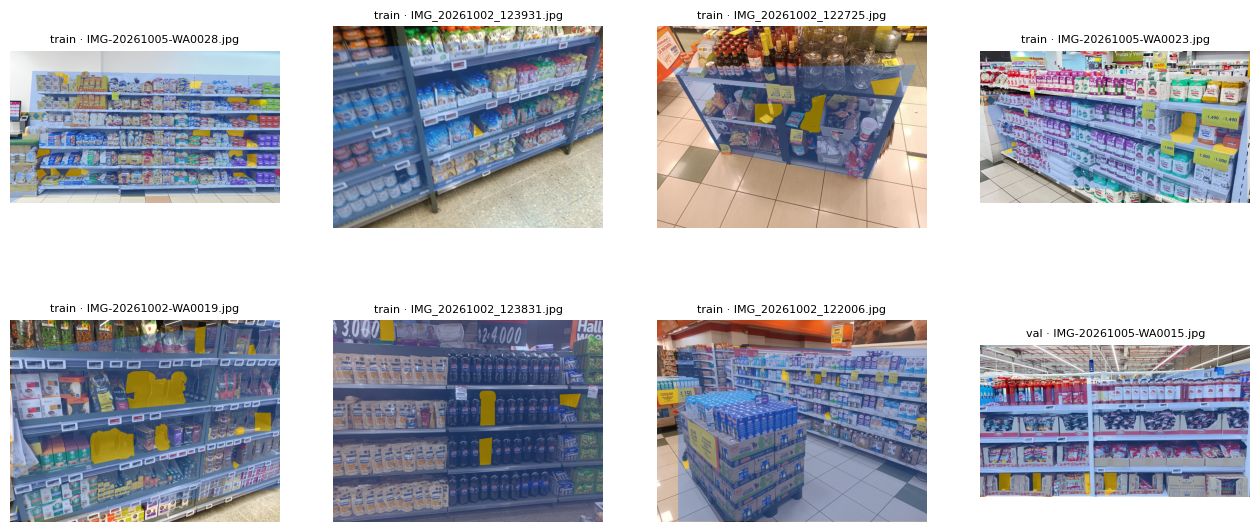

        count   mean    std    min    25%    50%    75%    max
split                                                         
dev      18.0   4.47   3.33   0.23   1.43   3.33   7.24  10.70
examen    6.0  52.63  18.18  23.72  42.47  58.75  64.80  70.69
train   214.0   6.55  11.73   0.00   1.23   3.01   5.86  66.50
val      40.0   4.52   3.15   0.00   2.67   4.09   5.73  13.92

Góndolas por % vacío real (¿hay casos de alerta roja para aprender y medir?):
split      dev examen   train           val
externa propia propia externa propia propia
rango                                      
0–10        25      0      77    180     60
10–30        2      1       1     15      5
30–70        0      4       0     15      0
70–100       0      1       0      0      0
Área de vacío fuera de la góndola dibujada, promedio por foto: 5.8 %


In [ ]:
# [3.2] Auditoría: distribución de % vacío y muestra visual
def pct_vacio(m: np.ndarray) -> float | None:
    """% vacío de una región. None si no hay góndola: sin denominador no se puede medir."""
    total = np.count_nonzero((m != FONDO) & (m != IGNORAR))
    return 100 * np.count_nonzero(m == VACIO) / total if total else None

def pintar(img: np.ndarray, m: np.ndarray) -> np.ndarray:
    salida = img.copy()
    salida[m == OCUPADO] = 0.65 * salida[m == OCUPADO] + 0.35 * np.array([246, 130, 59])
    salida[m == VACIO] = 0.45 * salida[m == VACIO] + 0.55 * np.array([0, 204, 250])
    return salida

def auditar(fotos: list, n: int = 8) -> pd.DataFrame:
    filas = []
    for f in fotos:
        m = cv2.imread(str(ruta_mascara(f)), 0)
        en_gondola = np.zeros(m.shape, bool)
        for g in f["gondolas"]:
            en_gondola |= rellenar(g, f["H"], f["W"])
        vac = m == VACIO
        filas.append(dict(foto=f["nombre"], split=f["split"], externa=f["externa"], pct=pct_vacio(m),
                          pct_gondolas=[100 * np.count_nonzero(vac & r) / max(1, np.count_nonzero(r)) for r in ((rellenar(g, f["H"], f["W"]) & (m != IGNORAR)) for g in f["gondolas"])],
                          vacio_fuera=100 * np.count_nonzero(vac & ~en_gondola) / max(1, np.count_nonzero(vac))))
    muestra = random.Random(CFG.semilla).sample(fotos, min(n, len(fotos)))
    fig, ejes = plt.subplots(2, max(1, (len(muestra) + 1) // 2), figsize=(16, 7), squeeze=False)
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, f in zip(ejes.T.ravel(), muestra):
        img = cv2.imread(str(f["ruta"]))
        ax.imshow(pintar(img, cv2.imread(str(ruta_mascara(f)), 0))[..., ::-1])
        ax.set_title(f"{f['split']} · {f['nombre'][:24]}", fontsize=8)
    fig.savefig(RUTAS["resultados"] / "auditoria_mascaras.png", dpi=110, bbox_inches="tight")
    plt.show(); plt.close(fig)
    return pd.DataFrame(filas)

AUDITORIA = auditar([f for f in FOTOS if (f["split"] != "examen" or EJECUTAR_EXAMEN_FINAL) and not f.get("parcial")])
print(AUDITORIA.groupby("split")["pct"].describe().round(2))
_g = AUDITORIA.explode("pct_gondolas").dropna(subset=["pct_gondolas"])
_g["rango"] = pd.cut(_g["pct_gondolas"].astype(float), [-0.01, 10, 30, 70, 100], labels=["0–10", "10–30", "30–70", "70–100"])
print("\nGóndolas por % vacío real (¿hay casos de alerta roja para aprender y medir?):")
print(pd.crosstab(_g["rango"], [_g["split"], _g["externa"].map({True: "externa", False: "propia"})]).to_string())
print(f"Área de vacío fuera de la góndola dibujada, promedio por foto: {AUDITORIA['vacio_fuera'].mean():.1f} %")
assert (AUDITORIA["pct"].notna()).all(), "Hay fotos sin góndola en su máscara"

In [ ]:
# [3.3] Galería de las fotos de repisas vacías: revisa cada máscara antes de entrenar
def galeria_vacias(fotos: list) -> None:
    vacias = [f for f in fotos if f.get("es_extrema") and (f["split"] != "examen" or EJECUTAR_EXAMEN_FINAL)]
    if not vacias:
        return
    filas = (len(vacias) + 2) // 3
    fig, ejes = plt.subplots(filas, 3, figsize=(15, 3.6 * filas), squeeze=False)
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, f in zip(ejes.ravel(), vacias):
        m = cv2.imread(str(ruta_mascara(f)), 0)
        ax.imshow(pintar(cv2.imread(str(f["ruta"])), m)[..., ::-1])
        ax.set_title(f"{f['split']} · {f['nombre']} · {pct_vacio(m):.0f} % vacío", fontsize=9)
    fig.savefig(RUTAS["resultados"] / "galeria_vacias.png", dpi=110, bbox_inches="tight")
    plt.show(); plt.close(fig)

galeria_vacias(FOTOS)

def galeria_void_kaggle(fotos: list, n: int = 12) -> None:
    """Revisión visual de la conversión con SAM. Lo amarillo enseña vacío y lo oscuro no se usa. Con `kaggle_negativos`, el resto enseña que no es vacío."""
    parciales = [f for f in fotos if f.get("parcial")]
    if not parciales:
        return
    muestra = random.Random(CFG.semilla).sample(parciales, min(n, len(parciales)))
    fig, ejes = plt.subplots(2, 6, figsize=(18, 6.4), squeeze=False)
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, f in zip(ejes.ravel(), muestra):
        m = cv2.imread(str(ruta_mascara(f)), 0)
        vista = pintar(cv2.imread(str(f["ruta"])), m)
        vista[m == IGNORAR] = 0.3 * vista[m == IGNORAR]
        ax.imshow(vista[..., ::-1])
        ax.set_title(f["escena"][:22], fontsize=8)
    fig.savefig(RUTAS["resultados"] / "galeria_void_kaggle.png", dpi=90, bbox_inches="tight")
    plt.show(); plt.close(fig)
    print("Fotos de Kaggle en train:", len(parciales))

galeria_void_kaggle(FOTOS)


Output hidden; open in https://colab.research.google.com to view.

**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 4 · Entrenamiento
- **Objetivo:** entrenar SegFormer-B1 a tres clases. v5 lo tenía previsto, pero nunca lo entrenó.
- **Entradas:** imágenes, máscaras y `PESOS_CLASE`.
- **Salidas:** `entrenamiento/last.pt`, `best.pt`, `historial.csv` en Drive.
- **Decisiones:**
  - **Recortes con zoom** en vez de foto completa: dan más píxeles a los vacíos chicos y funcionan igual que los mosaicos usados al inferir.
  - **La mitad de los recortes se centra en un vacío**, porque es la clase minoritaria.
  - **Pérdida:** entropía cruzada con pesos + Dice. En `e2_recall`, la clase vacío usa Tversky, que castiga más un vacío perdido que una falsa alarma.
  - **Curva train–dev:** cada evaluación mide también una muestra fija de train. Si la brecha crece mientras dev se estanca, es sobreajuste: no agregues capacidad ni épocas.
  - **Checkpoint en cada época:** Colab gratis se desconecta. Si `last.pt` existe, se reanuda solo.
  - **`best.pt` se elige en `dev`**, por el promedio de IoU de vacío y de góndola.
- **Tiempo estimado:** alrededor de 1–1,5 h en T4 con los valores actuales. Es una estimación, porque no se ha corrido en T4.
- **Validación:** la pérdida debe bajar. Si sale "CUDA out of memory", baja `batch` en `Config`.

**Texto corregido — documentación vigente del código actual.**

# Parte 4 · Entrenamiento y reanudación

Recortes reproducibles con variación entre épocas. Pérdida ponderada CE + Dice; e2 usa Tversky para vacío. `best.pt` se elige en dev excluyendo `255`. `d1` usa 1040 recortes por época, y `cuota_void_kaggle=0.25` fija la parte de Kaggle para que no desplace a las fotos propias ni alargue el entrenamiento. El experimento `x0` usa `lr_cabezal_mult=10` y EMA de pesos: dev evalúa y `best.pt` guarda los pesos promediados.

`m1` suma a `d1` tres cambios en los datos y uno en la aumentación:
- **Datos:** F4 como vacío, negativos de Kaggle y revisión de etiquetas (ver Parte 2).
- **`aumento_fuerte`:** perspectiva, balance de blancos, color, foto quemada, movimiento, ruido y JPEG.
- **`NO_VACIO`:** la pérdida premia fondo u ocupado por igual en esos píxeles y los cuenta como falso positivo de vacío en Dice.
- **Paciencia:** baja a 3 evaluaciones, porque `e1` y `d1` no mejoraron en dev durante las últimas 30 y 25 épocas.
- **Umbrales:** la grilla llega a 0,8, aunque en `d1` el IoU de val ya estaba plano entre 0,55 y 0,70. Permite elegir más precisión, no se espera más IoU.

Cada checkpoint identifica configuración, datos, máscaras, pesos de clase, pipeline y pesos iniciales; guarda optimizador, planificador y estado aleatorio. Solo se reanuda la misma ejecución. Una ejecución terminada no vuelve a entrenarse. Los batches sin etiquetas válidas se omiten; una época sin datos o una pérdida no finita detiene el proceso.

**YOLO26 (`y1`):** `[4.2b]` escribe el dataset y `entrenar_yolo` entrena con la receta de v5: `yolo26s-seg`, 1280 px, AdamW, mosaico y copy-paste, más aumentación de luz, sombra, movimiento, ruido y JPEG.
- **Etiquetas:** YOLO no tiene `IGNORAR`, y lo no etiquetado le enseña "no es vacío". Por eso `y1` corrige las etiquetas antes de entrenar.
- **Mejor modelo:** `best_vacio.pt` guarda la época con mejor F1 de vacío en dev, porque `best.pt` promedia góndola y vacío.
- **Si Colab se corta:** al repetir `Ejecutar todas`, retoma desde `last.pt`. Una corrida terminada no se repite y otra configuración no pisa esos pesos.
- **Validación:** `[4.2b]` se detiene si una foto de val o examen entra al dataset o si los polígonos no reproducen las máscaras. La galería muestra las fotos con más correcciones.

`y1` aún no se entrena en T4. Su flujo se probó solo en CPU con el perfil de prueba.


In [ ]:
# [4.1] Recortes diferentes por época e índice, reproducibles sin depender del worker
MEDIA=np.array([0.485,0.456,0.406],np.float32)
DESV=np.array([0.229,0.224,0.225],np.float32)

def a_tensor(img_bgr):
    rgb=img_bgr[...,::-1].astype(np.float32)/255
    return torch.from_numpy(((rgb-MEDIA)/DESV).transpose(2,0,1).copy())

def aumentar_luz(img,rng):
    x=img.astype(np.float32)/255
    x=np.clip(x**rng.uniform(0.7,1.5),0,1)
    x=np.clip((x-0.5)*rng.uniform(0.75,1.25)+0.5+rng.uniform(-0.08,0.08),0,1)
    if rng.random()<0.3:
        h,w=x.shape[:2]
        if rng.random()<0.5: x*=np.linspace(rng.uniform(.55,1),rng.uniform(.55,1),w,dtype=np.float32)[None,:,None]
        else: x*=np.linspace(rng.uniform(.55,1),rng.uniform(.55,1),h,dtype=np.float32)[:,None,None]
    return (x*255).astype(np.uint8)

def perspectiva(lado,rng,frac=0.06):
    """Mueve cada esquina hasta `frac` del lado: las fotos de pasillo traen perspectiva fuerte."""
    origen=np.float32([[0,0],[lado,0],[lado,lado],[0,lado]])
    return cv2.getPerspectiveTransform(origen,origen+rng.uniform(-frac*lado,frac*lado,(4,2)).astype(np.float32))

def aumentar_calidad(img,rng):
    """Balance de blancos, color, foto quemada, movimiento, ruido y JPEG de WhatsApp. Solo cambia la imagen."""
    x=img
    if rng.random()<.5: x=np.clip(x*rng.uniform(.85,1.15,3).astype(np.float32),0,255).astype(np.uint8)
    if rng.random()<.5:
        h=cv2.cvtColor(x,cv2.COLOR_BGR2HSV).astype(np.float32)
        h[...,0]=(h[...,0]+rng.uniform(-6,6))%180;h[...,1]=np.clip(h[...,1]*rng.uniform(.7,1.3),0,255)
        x=cv2.cvtColor(h.astype(np.uint8),cv2.COLOR_HSV2BGR)
    if rng.random()<.15: x=np.clip(x*float(rng.uniform(1.3,2.2)),0,255).astype(np.uint8)
    if rng.random()<.15:
        n=int(rng.integers(2,7))*2+1;k=np.zeros((n,n),np.float32);k[n//2]=1
        k=cv2.warpAffine(k,cv2.getRotationMatrix2D((n/2-.5,n/2-.5),float(rng.uniform(0,180)),1),(n,n))
        x=cv2.filter2D(x,-1,k/max(float(k.sum()),1e-6))
    elif rng.random()<.15: x=cv2.GaussianBlur(x,(0,0),float(rng.uniform(.6,1.6)))
    if rng.random()<.2: x=np.clip(x+rng.normal(0,rng.uniform(2,9),x.shape),0,255).astype(np.uint8)
    if rng.random()<.35:
        ok,b=cv2.imencode(".jpg",x,[cv2.IMWRITE_JPEG_QUALITY,int(rng.integers(35,86))])
        if ok: x=cv2.imdecode(b,cv2.IMREAD_COLOR)
    return x

class DatasetRecortes(Dataset):
    def __init__(self,fotos,cfg):
        if not fotos: raise ValueError("Train está vacío")
        self.fotos=list(fotos);self.cfg=cfg;self.epoca=0;self.cache={}
    def set_epoch(self,epoca): self.epoca=int(epoca)
    def __len__(self): return len(self.fotos)*self.cfg.muestras_por_foto
    def _leer(self,indice):
        if indice not in self.cache:
            f=self.fotos[indice];img=leer_imagen(f["ruta"],self.cfg);m=cv2.imread(str(ruta_mascara(f)),0)
            if m is None or m.shape!=img.shape[:2] or not set(np.unique(m))<={FONDO,OCUPADO,VACIO,NO_VACIO,IGNORAR}: raise ValueError(f"Máscara inválida: {f['nombre']}")
            ys,xs=np.nonzero(m==VACIO);paso=max(1,len(xs)//2000)
            if len(self.cache)>=8: self.cache.pop(next(iter(self.cache)))
            self.cache[indice]=(img,m,np.column_stack([xs,ys])[::paso])
        return self.cache[indice]
    def __getitem__(self,i):
        cfg=self.cfg
        rng=np.random.default_rng(np.random.SeedSequence([cfg.semilla,self.epoca,int(i)]))
        img,m,pix=self._leer(i%len(self.fotos));H,W=m.shape
        s=rng.uniform(*cfg.escala)
        cx,cy=pix[rng.integers(len(pix))] if len(pix) and rng.random()<cfg.prob_centrar_vacio else (rng.uniform(0,W),rng.uniform(0,H))
        A=cv2.getRotationMatrix2D((float(cx),float(cy)),rng.uniform(-3,3),s)
        A[:,2]+=cfg.crop/2-np.array([cx,cy])
        if cfg.aumento_fuerte:
            M=perspectiva(cfg.crop,rng)@np.vstack([A,[0,0,1]])
            x=cv2.warpPerspective(img,M,(cfg.crop,cfg.crop),flags=cv2.INTER_LINEAR,borderMode=cv2.BORDER_REPLICATE)
            y=cv2.warpPerspective(m,M,(cfg.crop,cfg.crop),flags=cv2.INTER_NEAREST,borderMode=cv2.BORDER_CONSTANT,borderValue=IGNORAR)
        else:
            x=cv2.warpAffine(img,A,(cfg.crop,cfg.crop),flags=cv2.INTER_LINEAR,borderMode=cv2.BORDER_REPLICATE)
            y=cv2.warpAffine(m,A,(cfg.crop,cfg.crop),flags=cv2.INTER_NEAREST,borderMode=cv2.BORDER_CONSTANT,borderValue=IGNORAR)
        if rng.random()<0.5: x,y=x[:,::-1],y[:,::-1]
        x=aumentar_luz(x,rng)
        if cfg.aumento_fuerte: x=aumentar_calidad(x,rng)
        return a_tensor(x),torch.from_numpy(y.astype(np.int64))


In [ ]:
# [4.2] Modelo, pérdida y métricas; IGNORAR se excluye en todas las selecciones
def crear_modelo(cfg):
    return SegformerForSemanticSegmentation.from_pretrained(cfg.modelo_base,num_labels=3,ignore_mismatched_sizes=True,
        id2label={0:"fondo",1:"ocupado",2:"vacio"},label2id={"fondo":0,"ocupado":1,"vacio":2})

def perdida(logits,y,pesos,cfg):
    if not (y!=IGNORAR).any(): raise ValueError("Lote sin píxeles válidos")
    logits=F.interpolate(logits,size=y.shape[-2:],mode="bilinear",align_corners=False)
    neg=y==NO_VACIO;y_ce=y.masked_fill(neg,IGNORAR)
    if neg.any():
        # Solo se sabe que no es vacío: fondo y ocupado valen lo mismo. Pesa como ocupado, su caso habitual.
        log_no_vacio=torch.logsumexp(F.log_softmax(logits,1)[:,[FONDO,OCUPADO]],1)[neg]
        suma=F.cross_entropy(logits,y_ce,weight=pesos,ignore_index=IGNORAR,reduction="sum")-pesos[OCUPADO]*log_no_vacio.sum()
        ce=suma/(pesos[y_ce[y_ce!=IGNORAR]].sum()+pesos[OCUPADO]*neg.sum())
    else:
        ce=F.cross_entropy(logits,y,weight=pesos,ignore_index=IGNORAR)
    valido=(y_ce!=IGNORAR).unsqueeze(1)
    # En Dice, lo negativo solo cuenta como falso positivo de vacío.
    mascara=valido.repeat(1,3,1,1);mascara[:,VACIO]|=neg
    prob=logits.softmax(1)*mascara
    y1=F.one_hot(y_ce.clamp(max=2),3).permute(0,3,1,2)*valido
    inter=(prob*y1).sum((2,3))
    dice=1-(2*inter+1)/(prob.sum((2,3))+y1.sum((2,3))+1)
    if cfg.perdida_recall:
        fp,fn=prob.sum((2,3))-inter,y1.sum((2,3))-inter
        tv=1-(inter+1)/(inter+cfg.tversky_alfa*fp+cfg.tversky_beta*fn+1)
        return ce+(dice[:,OCUPADO].mean()+tv[:,VACIO].mean())/2
    return ce+dice[:,1:].mean()

@torch.inference_mode()
def probabilidad(modelo,img,lado):
    h,w=img.shape[:2];escala=lado/max(h,w)
    nh,nw=max(32,round(h*escala/32)*32),max(32,round(w*escala/32)*32)
    device=dispositivo_de(modelo)
    x=a_tensor(cv2.resize(img,(nw,nh),interpolation=cv2.INTER_LINEAR)).unsqueeze(0).to(device)
    with torch.autocast(device_type=device.type,enabled=device.type=="cuda"):
        logits=modelo(pixel_values=x).logits
    return F.interpolate(logits.float(),size=(h,w),mode="bilinear",align_corners=False).softmax(1)[0].cpu().numpy()

_y=torch.tensor([[[VACIO,NO_VACIO,OCUPADO,IGNORAR]]]);_uno=torch.ones(3)
_bien=torch.tensor([[[[0.,0,0,0]],[[0.,4,4,0]],[[4.,0,0,0]]]]);_mal=_bien.clone();_mal[0,1,0,1]=0.;_mal[0,2,0,1]=8.;_fondo=_bien.clone();_fondo[0,0,0,1]=4.;_fondo[0,1,0,1]=0.
assert perdida(_mal,_y,_uno,CFG)>perdida(_bien,_y,_uno,CFG) and abs(float(perdida(_fondo,_y,_uno,CFG)-perdida(_bien,_y,_uno,CFG)))<1e-5,"NO_VACIO debe castigar vacío y tratar igual a fondo y ocupado"

def iou(a,b):
    u=np.count_nonzero(a|b)
    return np.count_nonzero(a&b)/u if u else 1.0

def pares_validos(mapa,gt):
    validos=gt!=IGNORAR
    return ((mapa==VACIO)&validos,(gt==VACIO)&validos,(mapa!=FONDO)&validos,(gt!=FONDO)&validos)

def puntaje_dev(modelo,fotos,cfg):
    if not fotos: raise ValueError("Dev está vacío")
    modelo.eval();v=[];g=[]
    for f in fotos:
        img=leer_imagen(f["ruta"],cfg);m=cv2.imread(str(ruta_mascara(f)),0)
        if m is None or not (m!=IGNORAR).any(): continue
        p=probabilidad(modelo,img,cfg.lado_completa).argmax(0)
        pv,gv,pg,gg=pares_validos(p,m);v.append(iou(pv,gv));g.append(iou(pg,gg))
    if not v: raise ValueError("Dev no contiene píxeles etiquetados")
    return dict(iou_vacio=float(np.mean(v)),iou_gondola=float(np.mean(g)),puntaje=float(np.mean(v)+np.mean(g))/2)


In [ ]:
# [4.2b] Dataset de YOLO26: polígonos de train y dev; val y examen nunca se escriben
CLASES_YOLO={0:"gondola",1:"vacio"};ID_GONDOLA,ID_VACIO=0,1
AREA_MIN_VACIO_YOLO=0.0003  # 0,03 % de la foto, el mismo mínimo de las etiquetas de v5

def poligonos_vacio(m):
    """Una instancia por región. Une trozos a menos de 4 px y corta cada hueco hacia el exterior, porque YOLO usa un solo polígono por instancia."""
    H,W=m.shape;r=cv2.morphologyEx(m.astype(np.uint8),cv2.MORPH_CLOSE,np.ones((9,9),np.uint8));area_min=AREA_MIN_VACIO_YOLO*H*W
    contornos,jerarquia=cv2.findContours(r,cv2.RETR_CCOMP,cv2.CHAIN_APPROX_SIMPLE)
    for c,h in zip(contornos,jerarquia[0] if jerarquia is not None else []):
        if h[3]>=0 and cv2.contourArea(c)>=area_min:
            x,y=c[c[:,:,1].argmin()][0];r[:y+1,x]=0
    n,lab,stats,_=cv2.connectedComponentsWithStats(r,connectivity=4);salida=[]
    for i in range(1,n):
        if stats[i,cv2.CC_STAT_AREA]<area_min: continue
        c=max(cv2.findContours((lab==i).astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_NONE)[0],key=cv2.contourArea)
        c=cv2.approxPolyDP(c,min(2.0,0.004*cv2.arcLength(c,True)),True).reshape(-1,2)
        if len(c)>=3: salida.append(c.astype(np.float64))
    return salida

def linea_yolo(clase,poligono,W,H):
    p=np.clip(np.asarray(poligono,float)/[W,H],0,1)
    return f"{clase} "+" ".join(f"{v:.6f}" for v in p.ravel())

def galeria_correcciones(cambios,ruta,n=6):
    """Etiqueta original y corregida de las fotos con más cambios. Lo que no se ve bien aquí tampoco se aprende bien."""
    elegidas=sorted(cambios,key=lambda x:-x[1])[:n]
    if not elegidas: return
    fig,ejes=plt.subplots(len(elegidas),2,figsize=(10,3.6*len(elegidas)),squeeze=False)
    for fila,(f,frac) in zip(ejes,elegidas):
        img=cv2.imread(str(f["ruta"]))
        for ax,titulo,m in zip(fila,(f"Original · {f['nombre']}",f"Corregida · cambia {100*frac:.2f} % de la foto"),(mascara_semantica(dict(f,corregir=[])),mascara_semantica(f))):
            ax.imshow(pintar(img,m)[...,::-1]);ax.set_title(titulo,loc="left",fontsize=9);ax.axis("off")
    fig.tight_layout();fig.savefig(ruta,dpi=75,bbox_inches="tight");plt.show();plt.close(fig)

def crear_dataset_yolo(fotos,cfg):
    """Enlaza imágenes y escribe polígonos. Se regenera en cada sesión de Colab con el mismo resultado, para poder retomar."""
    raiz=RUTAS["dataset_yolo"];conteo=defaultdict(int);acuerdo=[];cambios=[]
    if raiz.exists(): shutil.rmtree(raiz)
    for s in ("train","dev"): (raiz/"images"/s).mkdir(parents=True);(raiz/"labels"/s).mkdir(parents=True)
    for f in fotos:
        s=f["split"]
        if s not in ("train","dev"): continue
        if f.get("parcial"): raise ValueError("YOLO todavía no usa fotos parciales")
        m=mascara_semantica(f)==VACIO;H,W=m.shape;polis=poligonos_vacio(m)
        lineas=[linea_yolo(ID_GONDOLA,g,W,H) for g in f["gondolas"] if len(g)>=3]+[linea_yolo(ID_VACIO,p,W,H) for p in polis]
        if m.any():
            r=np.zeros((H,W),np.uint8)
            for p in polis: cv2.fillPoly(r,[np.round(p).astype(np.int32)],1)
            acuerdo.append(iou(r>0,m))
        if f.get("corregir"): cambios.append((f,float(np.mean(m!=(mascara_semantica(dict(f,corregir=[]))==VACIO)))))
        conteo[s+"_vacios"]+=len(polis)
        for k in range(f.get("repetir",1) if s=="train" else 1):
            ruta=Path(f["ruta"]);nombre=f"{ruta.stem}__r{k}" if k else ruta.stem
            (raiz/"images"/s/(nombre+ruta.suffix)).symlink_to(ruta.resolve())
            (raiz/"labels"/s/(nombre+".txt")).write_text("\n".join(lineas));conteo[s+"_imagenes"]+=1
    reservadas={Path(f["ruta"]).stem for f in fotos if f["split"] in ("val","examen")}
    escritas={p.stem.split("__r")[0] for p in (raiz/"images").glob("*/*")}
    if reservadas&escritas: raise ValueError(f"Fotos de val o examen en el dataset: {sorted(reservadas&escritas)[:5]}")
    if acuerdo and np.mean(acuerdo)<0.90: raise ValueError(f"Los polígonos no reproducen las máscaras: IoU {np.mean(acuerdo):.3f}")
    import yaml
    ruta_data=raiz/"data.yaml";ruta_data.write_text(yaml.safe_dump(dict(path=str(raiz),train="images/train",val="images/dev",names=CLASES_YOLO),sort_keys=False))
    print("Dataset YOLO:",dict(conteo),f"| acuerdo polígono-máscara {np.mean(acuerdo):.3f} | fotos corregidas {len(cambios)}")
    galeria_correcciones(cambios,RUTAS["resultados"]/f"etiquetas_corregidas_{EXPERIMENTO}.png")
    return ruta_data


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset YOLO: {'train_vacios': 1240, 'train_imagenes': 259, 'dev_vacios': 151, 'dev_imagenes': 18} | acuerdo polígono-máscara 0.993 | fotos corregidas 81


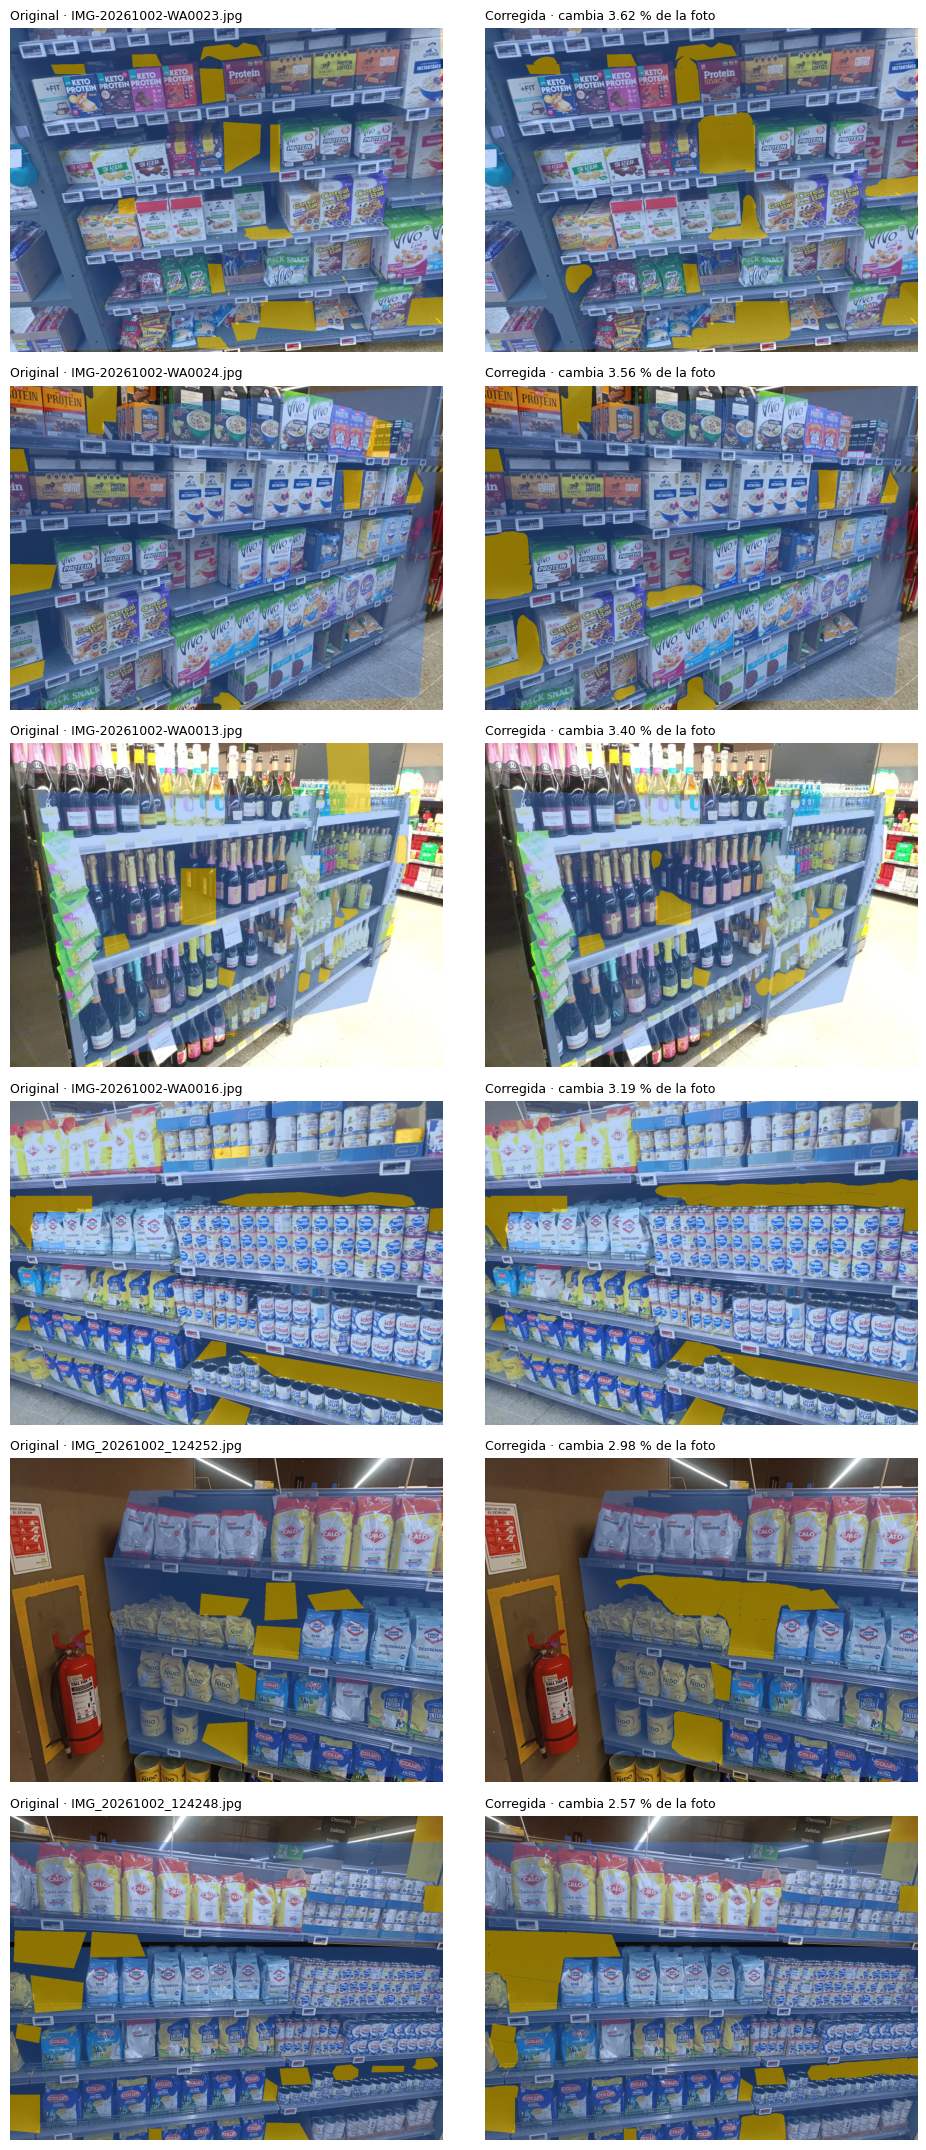

New https://pypi.org/project/ultralytics/8.4.198 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.5, 'brightness_by_max': True, 'brightness_limit': (-0.35, 0.25), 'contrast_limit': (-0.3, 0.3), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomGamma', 'p': 0.3, 'gamma_limit': (70.0, 180.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomShadow', 'p': 0.3, 'num_shadows_limit': (1, 3), 'shadow_dimension': 5, 'shadow_intensity_range': (0.5, 0.5), 'shadow_roi': (0.0, 0.0, 1.0, 1.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'CLAHE', 'p': 0.2, 'clip_limit': (1.0, 4.0), 'tile_grid_size': (8, 8)}}, {'__version__': '2.0.8', 'transform': 

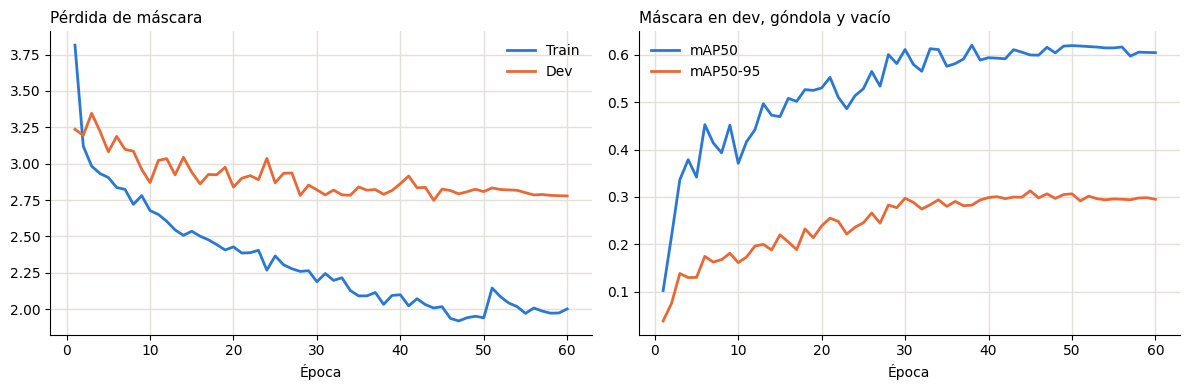

Candidato a reevaluar: /content/drive/MyDrive/stockeye_v6/corregido_v1/entrenamiento/y1/run/weights/best_vacio.pt


In [ ]:
# [4.3] Entrenamiento con identidad de ejecución y reanudación controlada
def guardar_atomico(estado,ruta):
    ruta=Path(ruta);ruta.parent.mkdir(parents=True,exist_ok=True)
    fd,tmp=tempfile.mkstemp(dir=ruta.parent,suffix=".pt.tmp");os.close(fd)
    try: torch.save(estado,tmp);os.replace(tmp,ruta)
    finally:
        if os.path.exists(tmp): os.unlink(tmp)

def estado_azar(generador):
    n=np.random.get_state()
    return dict(python=random.getstate(),numpy=[n[0],n[1].tolist(),n[2],n[3],n[4]],
                torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
                cargador=generador.get_state())

def restaurar_azar(r,generador):
    random.setstate(r["python"]);n=r["numpy"]
    np.random.set_state((n[0],np.array(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    torch.set_rng_state(r["torch"]);generador.set_state(r["cargador"])
    if torch.cuda.is_available() and r["cuda"]: torch.cuda.set_rng_state_all(r["cuda"])

def grupos_lr(modelo,cfg):
    cabezal=[p for n,p in modelo.named_parameters() if n.startswith("decode_head.")]
    resto=[p for n,p in modelo.named_parameters() if not n.startswith("decode_head.")]
    if not cabezal or not resto: raise ValueError("El modelo no separa encoder y cabezal")
    return [dict(params=resto,lr=cfg.lr),dict(params=cabezal,lr=cfg.lr*cfg.lr_cabezal_mult)]

def actualizar_ema(ema,modelo,decay,paso):
    # El promedio arranca rápido para que las primeras evaluaciones no dependan de los pesos iniciales.
    d=min(decay,(1+paso)/(10+paso))
    with torch.no_grad():
        for k,v in modelo.state_dict().items():
            if v.is_floating_point(): ema[k].lerp_(v,1-d)
            else: ema[k].copy_(v)

@contextlib.contextmanager
def pesos_evaluacion(modelo,ema):
    if ema is None:
        yield;return
    respaldo={k:v.detach().clone() for k,v in modelo.state_dict().items()}
    modelo.load_state_dict(ema)
    try: yield
    finally: modelo.load_state_dict(respaldo)

def muestreador_cuotas(train,cfg,generador):
    """Fija los recortes por época y la parte de cada fuente, para que sumar fotos no alargue el entrenamiento."""
    if not cfg.recortes_por_epoca: return None
    parcial=np.array([bool(f.get("parcial")) for f in train]);cuota=cfg.cuota_void_kaggle if parcial.any() else 0.
    p=np.where(parcial,cuota/max(1,parcial.sum()),(1-cuota)/max(1,(~parcial).sum()))
    return WeightedRandomSampler(torch.as_tensor(np.tile(p,cfg.muestras_por_foto),dtype=torch.double),cfg.recortes_por_epoca,replacement=True,generator=generador)

def entrenar(fotos,pesos,cfg,carpeta=None,pesos_iniciales=None):
    validar_config(cfg)
    carpeta=Path(carpeta or RUTAS["checkpoint"].parent);carpeta.mkdir(parents=True,exist_ok=True)
    r_ckpt,r_mejor,r_hist=carpeta/"last.pt",carpeta/"best.pt",carpeta/"historial.csv"
    train=[f for f in fotos if f["split"]=="train" for _ in range(f.get("repetir",1))]
    dev=[f for f in fotos if f["split"]=="dev"]
    if not train or not dev: raise ValueError("Train y dev deben contener fotos")
    identidad=huella_json(dict(pipeline=PIPELINE_VERSION,config=asdict(cfg),snapshot=snapshot_datos(fotos,pesos)))
    firma_inicial=sha_archivo(pesos_iniciales) if pesos_iniciales else None
    previo=torch.load(r_ckpt,map_location="cpu",weights_only=True) if r_ckpt.exists() else None
    if previo:
        if previo.get("identidad")!=identidad or previo.get("pesos_iniciales_sha256")!=firma_inicial:
            raise ValueError("El checkpoint pertenece a otra configuración/dataset/base. Usa una carpeta nueva; no se sobrescribe.")
        if previo.get("estado")=="terminado":
            print("La ejecución ya terminó:",carpeta);return pd.DataFrame(previo["historial"])
    else:
        fijar_semillas(cfg.semilla)
    # La curva train-dev solo usa fotos con todas sus clases etiquetadas.
    completas=list({f["nombre"]:f for f in train if not f.get("parcial")}.values())
    muestra=random.Random(cfg.semilla).sample(completas,min(18,len(completas)))
    dataset=DatasetRecortes(train,cfg);generador=torch.Generator().manual_seed(cfg.semilla)
    muestreador=muestreador_cuotas(train,cfg,generador)
    cargador=DataLoader(dataset,batch_size=cfg.batch,shuffle=muestreador is None,sampler=muestreador,drop_last=False,num_workers=cfg.workers,
                        pin_memory=AMP,persistent_workers=False,generator=generador)
    if not len(cargador): raise ValueError("No existe ningún batch de entrenamiento")
    inicial=torch.load(pesos_iniciales,map_location="cpu",weights_only=True) if pesos_iniciales else None
    arquitectura=previo.get("model_config") if previo else inicial.get("model_config") if inicial else None
    if arquitectura is None and pesos_iniciales and (Path(pesos_iniciales).parent/"model_config.json").exists():
        arquitectura=json.loads((Path(pesos_iniciales).parent/"model_config.json").read_text())
    modelo=(SegformerForSemanticSegmentation(SegformerConfig.from_dict(arquitectura)) if arquitectura else crear_modelo(cfg)).to(DEVICE)
    if inicial: modelo.load_state_dict(inicial["modelo"])
    opt=torch.optim.AdamW(grupos_lr(modelo,cfg),weight_decay=cfg.weight_decay)
    sched=torch.optim.lr_scheduler.OneCycleLR(opt,max_lr=[g["lr"] for g in opt.param_groups],total_steps=max(2,cfg.epocas*len(cargador)),pct_start=0.3)
    ema={k:v.detach().clone() for k,v in modelo.state_dict().items()} if cfg.ema_decay else None
    scaler=torch.amp.GradScaler("cuda",enabled=AMP)
    inicio,mejor,sin_mejora,historial=0,-1.0,0,[]
    if previo:
        c=previo
        modelo.load_state_dict(c["modelo"]);opt.load_state_dict(c["opt"]);sched.load_state_dict(c["sched"]);scaler.load_state_dict(c["scaler"])
        inicio,mejor,sin_mejora,historial=c["epoca"]+1,c["mejor"],c["sin_mejora"],c["historial"]
        if ema is not None: ema={k:v.to(DEVICE) for k,v in c["ema"].items()}
        restaurar_azar(c["azar"],generador)
        print("Reanudando época",inicio,"con datos y configuración comprobados")
    pesos=pesos.to(DEVICE)
    ultimo=inicio-1
    for epoca in range(inicio,cfg.epocas):
        if sin_mejora>=cfg.paciencia_evals: break
        dataset.set_epoch(epoca);modelo.train();t0=time.perf_counter();suma=0.;pasos=0;omitidos=0
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        for x,y in cargador:
            if not (y!=IGNORAR).any(): omitidos+=1;continue
            x,y=x.to(DEVICE),y.to(DEVICE);opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE,enabled=AMP): l=perdida(modelo(pixel_values=x).logits,y,pesos,cfg)
            if not torch.isfinite(l): raise FloatingPointError("Pérdida no finita; se conserva el checkpoint anterior")
            scaler.scale(l).backward();scaler.step(opt);scaler.update();sched.step()
            if ema is not None: actualizar_ema(ema,modelo,cfg.ema_decay,sched.last_epoch)
            comprobar_recursos(cfg,entrenamiento=True)
            suma+=float(l.item());pasos+=1
        if not pasos: raise ValueError("Todos los batches carecen de píxeles válidos")
        fila=dict(epoca=epoca,perdida=suma/pasos,segundos=time.perf_counter()-t0,batches_omitidos=omitidos,**recursos_actuales())
        if (epoca+1)%cfg.eval_cada==0 or epoca+1==cfg.epocas:
            with pesos_evaluacion(modelo,ema):
                fila.update(puntaje_dev(modelo,dev,cfg));fila["train_iou_vacio"]=puntaje_dev(modelo,muestra,cfg)["iou_vacio"]
                if fila["puntaje"]>mejor:
                    mejor,sin_mejora=fila["puntaje"],0
                    guardar_atomico(dict(modelo=modelo.state_dict(),epoca=epoca,config=asdict(cfg),model_config=modelo.config.to_dict(),
                                         pipeline=PIPELINE_VERSION,identidad=identidad,metricas=fila),r_mejor)
                else: sin_mejora+=1
        historial.append(fila);ultimo=epoca;print({k:round(v,4) if isinstance(v,float) else v for k,v in fila.items()})
        c=dict(modelo=modelo.state_dict(),opt=opt.state_dict(),sched=sched.state_dict(),scaler=scaler.state_dict(),
               epoca=epoca,mejor=mejor,sin_mejora=sin_mejora,historial=historial,identidad=identidad,
               config=asdict(cfg),model_config=modelo.config.to_dict(),pipeline=PIPELINE_VERSION,
               pesos_iniciales_sha256=firma_inicial,azar=estado_azar(generador),estado="en_curso",ema=ema)
        guardar_atomico(c,r_ckpt);guardar_csv(pd.DataFrame(historial),r_hist)
    if not r_mejor.exists(): raise RuntimeError("No se generó best.pt")
    if r_ckpt.exists():
        c=torch.load(r_ckpt,map_location="cpu",weights_only=True);c["estado"]="terminado";guardar_atomico(c,r_ckpt)
    return pd.DataFrame(historial)

def cb_mejor_vacio(trainer):
    """best.pt promedia góndola y vacío. Aquí queda la época con mejor F1 de vacío en dev, también si Colab se corta y se retoma."""
    seg=getattr(getattr(trainer.validator,"metrics",None),"seg",None)
    if seg is None or ID_VACIO not in list(seg.ap_class_index) or not trainer.last.exists(): return
    i=list(seg.ap_class_index).index(ID_VACIO);p,r=float(seg.p[i]),float(seg.r[i]);f1=2*p*r/max(p+r,1e-9)
    registro=trainer.wdir/"mejor_vacio.json"
    if f1>(json.loads(registro.read_text())["f1"] if registro.exists() else -1):
        shutil.copy(trainer.last,trainer.wdir/"best_vacio.pt")
        registro.write_text(json.dumps(dict(epoca=trainer.epoch+1,p=p,r=r,f1=f1)))

def aumentos_yolo():
    """Solo cambian píxeles: luz, sombra, movimiento, ruido y JPEG, como las fotos de WhatsApp. Base: AUG_LUZ de v5."""
    import albumentations as A
    jpeg=A.ImageCompression(quality_range=(35,90),p=0.3) if int(A.__version__.split(".")[0])>=2 else A.ImageCompression(quality_lower=35,quality_upper=90,p=0.3)
    return [A.RandomBrightnessContrast(brightness_limit=(-0.35,0.25),contrast_limit=(-0.3,0.3),p=0.5),A.RandomGamma(gamma_limit=(70,180),p=0.3),
            A.RandomShadow(shadow_roi=(0,0,1,1),num_shadows_limit=(1,3),p=0.3),A.CLAHE(p=0.2),A.ISONoise(p=0.2),
            A.MotionBlur(blur_limit=7,p=0.15),A.GaussianBlur(blur_limit=(3,7),p=0.1),jpeg]

def entrenar_yolo(fotos,cfg):
    """Entrena o retoma desde last.pt en Drive. Una corrida terminada no se repite y otra configuración no pisa estos pesos."""
    from ultralytics import YOLO
    carpeta=CARPETA_EXP/"run";pesos=carpeta/"weights";last=pesos/"last.pt";ruta_id=CARPETA_EXP/"identidad_yolo.json";terminado=CARPETA_EXP/"terminado.json"
    identidad=huella_json(dict(pipeline=PIPELINE_VERSION,config=asdict(cfg),snapshot=snapshot_datos(fotos)))
    if ruta_id.exists() and json.loads(ruta_id.read_text())["identidad"]!=identidad:
        raise ValueError("Este entrenamiento pertenece a otra configuración o a otros datos. Usa otro experimento; no se sobrescribe.")
    if terminado.exists() and RUTAS["mejor"].exists():
        print("La ejecución ya terminó:",carpeta)
    else:
        data=crear_dataset_yolo(fotos,cfg);guardar_json(dict(identidad=identidad),ruta_id)
        modelo=YOLO(str(last) if last.exists() else cfg.modelo_yolo);modelo.add_callback("on_fit_epoch_end",cb_mejor_vacio)
        if last.exists():
            print("Reanudando desde",last)
            try: modelo.train(resume=True)
            except AssertionError as error:
                if "nothing to resume" not in str(error): raise
        else:
            modelo.train(data=str(data),project=str(CARPETA_EXP),name="run",exist_ok=True,device=0 if DEVICE=="cuda" else "cpu",imgsz=cfg.lado_completa,epochs=cfg.epocas,
                         patience=cfg.paciencia_yolo,batch=cfg.batch_yolo,workers=cfg.workers,cache="disk",amp=AMP,seed=cfg.semilla,deterministic=False,save_period=-1,plots=True,
                         optimizer="AdamW",lr0=0.001,lrf=0.01,cos_lr=True,momentum=0.9,weight_decay=0.0005,warmup_epochs=3,warmup_momentum=0.8,warmup_bias_lr=0.0,
                         mosaic=1.0,close_mosaic=10,copy_paste=0.5,copy_paste_mode="flip",mixup=0.0,hsv_h=0.015,hsv_s=0.6,hsv_v=0.5,degrees=5.0,perspective=0.0005,
                         translate=0.1,scale=0.5,fliplr=0.5,flipud=0.0,overlap_mask=True,mask_ratio=4,augmentations=aumentos_yolo())
        if not RUTAS["mejor"].exists(): shutil.copy(pesos/"best.pt",RUTAS["mejor"])
        guardar_json(dict(fecha=datetime.now(timezone.utc).isoformat()),terminado)
    historial=pd.read_csv(carpeta/"results.csv");historial.columns=[c.strip() for c in historial.columns]
    if (pesos/"mejor_vacio.json").exists(): print("Mejor vacío en dev:",json.loads((pesos/"mejor_vacio.json").read_text()))
    return historial

def curvas_yolo(df,ruta):
    """Pérdida de máscara en train y dev, y calidad en dev. Si train baja y dev sube, hay sobreajuste."""
    fig,(izq,der)=plt.subplots(1,2,figsize=(12,4))
    for ax,series,titulo in ((izq,(("train/seg_loss","Train"),("val/seg_loss","Dev")),"Pérdida de máscara"),(der,(("metrics/mAP50(M)","mAP50"),("metrics/mAP50-95(M)","mAP50-95")),"Máscara en dev, góndola y vacío")):
        for (col,nombre),color in zip(series,("#2a78d6","#eb6834")): ax.plot(df["epoch"],df[col],color=color,linewidth=2,label=nombre)
        ax.set_title(titulo,loc="left",fontsize=11);ax.set_xlabel("Época");ax.grid(color="#e1e0d9",linewidth=1);ax.set_axisbelow(True);ax.legend(frameon=False)
        ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout();fig.savefig(ruta,dpi=110,bbox_inches="tight");plt.show();plt.close(fig)

if ENTRENAR and CFG.modelo_tipo=="yolo":
    HISTORIAL=entrenar_yolo(FOTOS,CFG)
    curvas_yolo(HISTORIAL,RUTAS["resultados"]/f"curvas_{EXPERIMENTO}.png")
elif ENTRENAR:
    HISTORIAL=entrenar(FOTOS,PESOS_CLASE,CFG)
    if not HISTORIAL.empty:
        HISTORIAL.plot(x="epoca",y="perdida",title="Entrenamiento corregido");plt.show()
RUTA_CANDIDATO=Path(os.environ.get("SV6_PESOS_CANDIDATO",str(RUTAS["mejor"] if RUTAS["mejor"].exists() else RUTAS["mejor_anterior"])))
if not RUTA_CANDIDATO.exists():
    raise FileNotFoundError("No hay pesos para evaluar. Activa ENTRENAR=True en [1.2] o indica SV6_PESOS_CANDIDATO. Los checkpoints antiguos no se reanudan a ciegas.")
print("Candidato a reevaluar:",RUTA_CANDIDATO)


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 5 · Predicción por modos
- **Objetivo:** convertir una foto en un mapa de clases.
- **Salidas:** `SEGMENTADOR`, con el modo y umbral elegidos.
- **Decisiones:**
  - **Mismos cuatro modos de v5** (`completa`, `tta`, `mosaicos`, `mosaicos+tta`), que ya demostraron servir.
  - **Modo y umbral se eligen en `dev`**, nunca en `val`, por IoU de vacío, respetando el tiempo máximo por foto. En `e2_recall` se usa F2 con un piso de precisión, porque perder un vacío cuesta más que una falsa alarma.
  - **`Segmentador` es la interfaz (Strategy):** v5 y v6 pasan por la misma evaluación.
- **Validación:** la tabla muestra todas las combinaciones probadas.

**Texto corregido — documentación vigente del código actual.**

# Parte 5 · Predictor y selección en dev

Define el predictor; la elección se ejecuta en `[6.3]` después de definir la geometría. Se prueban foto completa, TTA, mosaicos y combinación. El piso de precisión, tiempo p95 y límites de memoria se aplican a todos los experimentos. Si ninguna opción cumple, se guarda la tabla y se detiene la selección.

`SegmentadorYOLO26` tiene la misma interfaz que SegFormer: cada instancia pinta su confianza por píxel, así que `[7.1]`–`[7.7]` miden igual a los dos modelos. Predice siempre a `lado_completa`, de modo que un mosaico de 640 px queda ampliado ×2, como en v5. Su TTA es un espejo horizontal, porque YOLO26-seg no trae una propia. El límite de VRAM de inferencia no se aplica en `y1`: se informa el valor medido.

El objeto resultante es `SEGMENTADOR_CANDIDATO`; no se considera modelo operativo hasta superar la compuerta.


In [ ]:
# [5.1] Predictor independiente del experimento; el checkpoint no se carga con YOLO
class Segmentador(Protocol):
    def mapa(self,img: np.ndarray) -> np.ndarray: ...

def mapa_desde_prob(p,umbral):
    if p.ndim!=3 or p.shape[0]!=3 or not np.isfinite(p).all(): raise ValueError("Probabilidades inválidas")
    if not 0<umbral<1: raise ValueError("Umbral fuera de rango")
    m=(p[OCUPADO]>p[FONDO]).astype(np.uint8)
    m[p[VACIO]>=umbral]=VACIO
    return m

def ventanas(lado,tile,solape):
    paso=int(tile*(1-solape))
    if lado<1 or tile<1 or paso<1: raise ValueError("Ventanas inválidas")
    return [0] if lado<=tile else sorted(set(list(range(0,lado-tile,paso))+[lado-tile]))

class SegmentadorSegFormer:
    def __init__(self,modelo,cfg,modo="completa",umbral=0.5):
        validar_config(cfg)
        if modo not in cfg.modos: raise ValueError("Modo desconocido")
        self.modelo,self.cfg,self.modo,self.umbral=modelo.eval(),cfg,modo,float(umbral)
    def _prob_base(self,img,lado): return probabilidad(self.modelo,img,lado)
    def _sin_tta(self,img):
        p=self._prob_base(img,self.cfg.lado_completa)
        if "mosaicos" not in self.modo: return p
        h,w=img.shape[:2];suma=p.copy();peso=np.ones((h,w),np.float32)
        for y in ventanas(h,self.cfg.tile,self.cfg.solape):
            for x in ventanas(w,self.cfg.tile,self.cfg.solape):
                r=img[y:y+self.cfg.tile,x:x+self.cfg.tile]
                suma[:,y:y+r.shape[0],x:x+r.shape[1]]+=self._prob_base(r,self.cfg.crop)
                peso[y:y+r.shape[0],x:x+r.shape[1]]+=1
        return suma/peso
    def prob(self,img):
        p=self._sin_tta(img)
        if "tta" in self.modo: p=(p+self._sin_tta(img[:,::-1])[:,:,::-1])/2
        return p
    def mapa(self,img): return mapa_desde_prob(self.prob(img),self.umbral)

class SegmentadorYOLO26(SegmentadorSegFormer):
    """Misma interfaz que SegFormer: cada instancia pinta su confianza por píxel, así [7.1]-[7.7] miden igual a los dos modelos."""
    def __init__(self,modelo,cfg,modo="completa",umbral=0.25):
        validar_config(cfg)
        if modo not in cfg.modos: raise ValueError("Modo desconocido")
        if {int(k):str(v).lower().strip() for k,v in modelo.names.items()}!=CLASES_YOLO: raise ValueError(f"Clases de YOLO inesperadas: {modelo.names}")
        self.modelo,self.cfg,self.modo,self.umbral=modelo,cfg,modo,float(umbral)
    def _prob_base(self,img,lado):
        # Siempre a lado_completa: un mosaico de 640 px queda ampliado ×2, como en v5, y el vacío chico gana píxeles.
        h,w=img.shape[:2];p=np.zeros((3,h,w),np.float32)
        r=self.modelo.predict(np.ascontiguousarray(img),imgsz=self.cfg.lado_completa,conf=0.05,max_det=300,retina_masks=True,verbose=False)[0]
        if r.masks is not None:
            confianzas=r.boxes.conf.cpu().numpy();clases=r.boxes.cls.cpu().numpy().astype(int);mascaras=r.masks.data.cpu().numpy()
            for i in np.argsort(confianzas):  # de menor a mayor: en un cruce queda la confianza más alta
                m=mascaras[i]
                if m.shape!=(h,w): m=cv2.resize(m.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)
                if clases[i]==ID_VACIO: p[VACIO][m>0.5]=confianzas[i]
                elif confianzas[i]>=self.cfg.conf_gondola: p[OCUPADO][m>0.5]=1
        p[FONDO]=1-p[OCUPADO]
        return p

def crear_segmentador(modelo,cfg,modo="completa",umbral=0.5):
    return (SegmentadorYOLO26 if cfg.modelo_tipo=="yolo" else SegmentadorSegFormer)(modelo,cfg,modo,umbral)

def cargar_modelo(ruta,cfg):
    if cfg.modelo_tipo!="yolo": return cargar_segformer(ruta,cfg)
    from ultralytics import YOLO
    modelo=YOLO(str(ruta));modelo.stockeye_sha256=sha_archivo(ruta)
    return modelo

def cargar_segformer(ruta,cfg,device=None,model_config=None):
    c=torch.load(ruta,map_location="cpu",weights_only=True)
    if "modelo" not in c: raise ValueError("No es un checkpoint SegFormer de StockEye")
    arquitectura=model_config or c.get("model_config")
    if arquitectura is None:
        base=c.get("config",{}).get("modelo_base")
        if base!=cfg.modelo_base: raise ValueError("El modelo base del checkpoint antiguo no coincide con la configuración")
        # Importación explícita de pesos antiguos para reevaluar. Solo aquí puede necesitarse la configuración de HF.
        hfcfg=SegformerConfig.from_pretrained(base)
        hfcfg.num_labels=3;hfcfg.id2label={0:"fondo",1:"ocupado",2:"vacio"};hfcfg.label2id={v:k for k,v in hfcfg.id2label.items()}
    else:
        hfcfg=SegformerConfig.from_dict(arquitectura)
    if hfcfg.num_labels!=3: raise ValueError("El checkpoint no tiene las tres clases esperadas")
    modelo=SegformerForSemanticSegmentation(hfcfg)
    modelo.load_state_dict(c["modelo"],strict=True)
    modelo.stockeye_sha256=sha_archivo(ruta)
    return modelo.to(device or ("cuda" if torch.cuda.is_available() else "cpu")).eval()


In [ ]:
# [5.2] Definición de selección en dev; se ejecuta en [6.3], tras definir geometría
def elegir_operacion(modelo,fotos,cfg):
    dev=[f for f in fotos if f["split"]=="dev"]
    if not dev: raise ValueError("Dev está vacío")
    filas=[]
    for modo in cfg.modos:
        seg=crear_segmentador(modelo,cfg,modo)
        acumulados={float(u):dict(tp=0,fp=0,fn=0,ious=[],tiempos=[],vram=[],ram=[]) for u in cfg.umbrales_vacio}
        for f in dev:
            t_lectura=time.perf_counter();img=leer_imagen(f["ruta"],cfg);lectura=time.perf_counter()-t_lectura
            gt=cv2.imread(str(ruta_mascara(f)),0)
            if gt is None or not (gt!=IGNORAR).any(): raise ValueError("Dev sin máscara válida")
            if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
            sincronizar_cuda(modelo);t0=time.perf_counter();p=seg.prob(img);sincronizar_cuda(modelo)
            duracion=time.perf_counter()-t0
            for u,a in acumulados.items():
                t1=time.perf_counter();m=mapa_desde_prob(p,u)
                postprocesar_mapa(img,m,cfg)
                a["tiempos"].append(lectura+duracion+time.perf_counter()-t1)
                pv,gv,_,_=pares_validos(m,gt)
                a["tp"]+=int(np.count_nonzero(pv&gv));a["fp"]+=int(np.count_nonzero(pv&~gv));a["fn"]+=int(np.count_nonzero(~pv&gv));a["ious"].append(iou(pv,gv))
                r=recursos_actuales();a["vram"].append(r["vram_gb"]);a["ram"].append(r["ram_gb"])
        for u,a in acumulados.items():
            pr=a["tp"]/max(1,a["tp"]+a["fp"]);rc=a["tp"]/max(1,a["tp"]+a["fn"])
            filas.append(dict(modo=modo,umbral=u,iou_vacio=float(np.mean(a["ious"])),p=pr,r=rc,f2=5*pr*rc/max(1e-9,4*pr+rc),
                              segundos_foto=float(np.mean(a["tiempos"])),p95_s=float(np.percentile(a["tiempos"],95)),
                              vram_gb=max(a["vram"]),ram_gb=max(a["ram"])))
    tabla=pd.DataFrame(filas).sort_values("f2" if cfg.criterio_umbral=="f2" else "iou_vacio",ascending=False)
    validas=tabla[(tabla.p95_s<=cfg.tiempo_max_s)&(tabla.p>=cfg.min_precision)]
    if cfg.max_vram_inferencia_gb is not None: validas=validas[validas.vram_gb<=cfg.max_vram_inferencia_gb]
    if cfg.max_ram_gb is not None: validas=validas[validas.ram_gb<=cfg.max_ram_gb]
    if validas.empty:
        guardar_csv(tabla,RUTAS["resultados"]/f"modos_rechazados_{EXPERIMENTO}.csv")
        raise RuntimeError("Ningún modo cumple tiempo, precisión y recursos. No se selecciona un incumplidor. Revisa la tabla o ajusta explícitamente los requisitos.")
    mejor=validas.iloc[0]
    return str(mejor["modo"]),float(mejor["umbral"]),tabla


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 6 · De máscara a `% vacío`
- **Objetivo:** obtener `% vacío` por góndola y por repisa **solo desde el mapa de clases**.
- **Decisiones:**
  - **Góndolas:** componentes conexas de ocupado ∪ vacío, tras un cierre morfológico que une lo que parte una persona.
  - **Parcial:** una góndola que toca el borde de la foto se marca `parcial`, porque su `%` no representa el mueble completo.
  - **Perspectiva:** se calcula el `%` en píxeles y en vista rectificada. La Parte 7 mide cuál conviene.
  - **Repisas:** `cortar_repisas` (mismo algoritmo de v5) sobre el cuadrilátero de la máscara. El corte se marca no confiable si da menos de 2 bandas o bandas muy disparejas.
  - **Semáforo:** stock = 100 − `% vacío`. Verde ≥ 70, rojo < 30 con alerta (criterio Walmart del README).
- **Alerta prudente:** una repisa confiable en rojo activa la alerta aunque el promedio de la góndola sea verde. Una góndola `parcial` con un bloque continuo de vacío ancho sale como `revisar`, no verde, porque el promedio de un mueble incompleto puede esconder una repisa vacía.
- **Validación:** un caso sintético con resultado conocido.

**Texto corregido — documentación vigente del código actual.**

# Parte 6 · Góndolas, vacíos y repisas

Se conservan los componentes de ocupado ∪ vacío; el cierre morfológico se aplica por separado para obtener formas y evita unir góndolas separadas. Las góndolas contiguas aún pueden unirse por la propia segmentación. Las ROI calibradas opcionales permiten asignar identidad física.

Una imagen sin bordes de repisa produce una banda sin confianza. No se informan repisas individuales en ese caso. Una región parcial se marca `revisar`, salvo que lo observado ya sea rojo: lo visto basta para alertar, pero nunca para afirmar que el mueble completo está bien. Su porcentaje corresponde solo al área observada y `pct_vacio_gondola_completa` queda nulo. Los colores usan stock = 100 − área vacía: verde ≥ 70 %, rojo < 30 %, amarillo intermedio.


In [ ]:
# [6.1] Geometría, mediciones y estados con abstención ante falta de evidencia
def cuadrilatero(m):
    cnts,_=cv2.findContours(m.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: raise ValueError("Región vacía")
    p=cv2.convexHull(np.vstack(cnts)).reshape(-1,2).astype(np.float32)
    s,d=p.sum(1),p[:,0]-p[:,1]
    q=np.array([p[s.argmin()],p[d.argmax()],p[s.argmax()],p[d.argmin()]],np.float32)
    triangulos=[cv2.contourArea(q[[i,(i+1)%4,(i+2)%4]]) for i in range(4)]
    if min(triangulos)>=.05*max(cv2.contourArea(p),1): return q
    c,(w,h),angulo=cv2.minAreaRect(p)
    r=cv2.boxPoints((c,(max(w,2.),max(h,2.)),angulo)).astype(np.float32)
    r=r[np.argsort(np.arctan2(r[:,1]-c[1],r[:,0]-c[0]))]
    return np.roll(r,-int(r.sum(1).argmin()),axis=0)

def homografia(q,alto):
    q=np.asarray(q,np.float32)
    if q.shape!=(4,2) or not np.isfinite(q).all(): raise ValueError("Cuadrilátero inválido")
    ancho=(np.linalg.norm(q[1]-q[0])+np.linalg.norm(q[2]-q[3]))/2
    alto_q=(np.linalg.norm(q[3]-q[0])+np.linalg.norm(q[2]-q[1]))/2
    w=int(np.clip(round(alto*ancho/max(alto_q,1)),32,2400))
    M=cv2.getPerspectiveTransform(q,np.array([[0,0],[w,0],[w,alto],[0,alto]],np.float32))
    if not np.isfinite(M).all() or abs(np.linalg.det(M))<1e-12: raise ValueError("Perspectiva degenerada")
    return M,w

def pct_rectificado(region,vacio,q,alto):
    M,w=homografia(q,alto)
    r=cv2.warpPerspective(region.astype(np.uint8),M,(w,alto),flags=cv2.INTER_NEAREST)>0
    v=cv2.warpPerspective((vacio&region).astype(np.uint8),M,(w,alto),flags=cv2.INTER_NEAREST)>0
    return 100*np.count_nonzero(v)/np.count_nonzero(r) if r.any() else None

def cortar_repisas(img,q,alto,repisa_min,prominencia_min=0.005):
    M,w=homografia(q,alto)
    g=cv2.cvtColor(cv2.warpPerspective(img,M,(w,alto)),cv2.COLOR_BGR2GRAY).astype(np.float32)
    gy,gx=np.abs(cv2.Sobel(g,cv2.CV_32F,0,1,ksize=3)),np.abs(cv2.Sobel(g,cv2.CV_32F,1,0,ksize=3))
    perfil=((gy>2*gx)&(gy>np.percentile(gy,75)))[:,int(.1*w):max(int(.1*w)+1,int(.9*w))].mean(1)
    s=max(1.,.006*alto);xx=np.arange(-int(3*s),int(3*s)+1)
    k=np.exp(-.5*(xx/s)**2);perfil=np.convolve(perfil,k/k.sum(),mode="same")
    amplitud=float(np.ptp(perfil));cortes=[]
    if amplitud>=prominencia_min:
        umbral=float(np.median(perfil))+max(.25*amplitud,prominencia_min)
        activos=np.nonzero((perfil>umbral)&(np.arange(alto)>.03*alto)&(np.arange(alto)<.97*alto))[0]
        grupos=np.split(activos,np.where(np.diff(activos)>1)[0]+1) if len(activos) else []
        candidatos=[]
        for grupo in grupos:
            if not len(grupo): continue
            maximo=perfil[grupo].max();meseta=grupo[np.isclose(perfil[grupo],maximo,rtol=1e-4,atol=1e-8)]
            candidatos.append(int(meseta[len(meseta)//2]))
        for i in sorted(candidatos,key=lambda i:-perfil[i]):
            if all(abs(i-j)>=repisa_min*alto for j in cortes): cortes.append(i)
    ys=[0]+sorted(cortes)+[alto];Minv=np.linalg.inv(M)
    return [cv2.perspectiveTransform(np.array([[[0,a],[w,a],[w,b],[0,b]]],np.float32),Minv)[0] for a,b in zip(ys,ys[1:])]

def semaforo(pct,cfg):
    if pct is None or not math.isfinite(float(pct)) or not 0<=pct<=100: return "indeterminado"
    stock=100-float(pct)
    return "verde" if stock>=cfg.stock_verde else "rojo" if stock<cfg.stock_rojo else "amarillo"

def franja_continua(vacio,region):
    n,_,stats,_=cv2.connectedComponentsWithStats((vacio&region).astype(np.uint8))
    if n<2 or not region.any(): return 0.
    xs=np.nonzero(region)[1]
    return float(stats[1:,cv2.CC_STAT_WIDTH].max()/max(1,xs.max()-xs.min()+1))

def semaforo_prudente(g,rep,vacio,cfg):
    color=semaforo(g["pct"],cfg)
    # Lo observado basta para alertar; una vista parcial solo impide afirmar que el mueble completo está bien.
    if color=="rojo" or (rep["confiable"] and any(semaforo(r["pct"],cfg)=="rojo" for r in rep["repisas"])): return "rojo"
    if g["parcial"]: return "revisar"
    if color=="verde" and not rep["confiable"] and franja_continua(vacio,g["region"])>=cfg.franja_min_ancho: return "revisar"
    return color

def gondolas_desde_mapa(mapa,cfg,rois=None):
    if mapa.ndim!=2 or not set(np.unique(mapa))<={FONDO,OCUPADO,VACIO}: raise ValueError("Mapa de clases inválido")
    H,W=mapa.shape;salida=[];base=(mapa==OCUPADO)|(mapa==VACIO);vacio=mapa==VACIO
    regiones=[]
    if rois:
        ids=[r.get("gondola_id") for r in rois]
        if any(not isinstance(gid,str) or not gid for gid in ids) or len(ids)!=len(set(ids)):
            raise ValueError("Cada ROI calibrada requiere un gondola_id único")
        ocupada=np.zeros_like(base)
        for roi in rois:
            q=np.asarray(roi["poligono"],float)
            if roi.get("normalizada",True) and (not np.isfinite(q).all() or q.min()<0 or q.max()>1):
                raise ValueError("ROI normalizada fuera de [0,1]")
            if roi.get("normalizada",True): q=q*np.array([W-1,H-1])
            region=rellenar(q,H,W)
            if (region&ocupada).any(): raise ValueError("Las ROI de góndolas se superponen")
            ocupada|=region
            regiones.append((region,roi.get("gondola_id"),True))
    else:
        n,labels=cv2.connectedComponents(base.astype(np.uint8))
        regiones=[(labels==i,None,False) for i in range(1,n)]
    k=max(3,int(cfg.cierre_frac*max(H,W)))|1
    for region,gid,calibrada in regiones:
        if np.count_nonzero(region)<cfg.area_min_gondola*H*W: continue
        # El cierre se usa para forma, por componente; no fusiona góndolas ni inventa píxeles ocupados en el denominador.
        forma=cv2.morphologyEx(region.astype(np.uint8),cv2.MORPH_CLOSE,np.ones((k,k),np.uint8))>0
        q=cuadrilatero(forma);ys,xs=np.nonzero(region);b=cfg.margen_borde_px
        parcial=not calibrada and (xs.min()<=b or ys.min()<=b or xs.max()>=W-1-b or ys.max()>=H-1-b)
        evidencia=region&base
        if not evidencia.any(): continue
        cobertura=float(np.count_nonzero(evidencia)/np.count_nonzero(region))
        if calibrada and cobertura<cfg.cobertura_min_roi: parcial=True
        pct=100*np.count_nonzero(vacio&evidencia)/np.count_nonzero(evidencia)
        n,_,stats,_=cv2.connectedComponentsWithStats((vacio&region).astype(np.uint8))
        cantidad=int(sum(area>=cfg.area_min_vacio_px for area in stats[1:,cv2.CC_STAT_AREA])) if n>1 else 0
        salida.append(dict(region=evidencia,q=q,parcial=bool(parcial),pct=pct,
                           pct_rect=pct_rectificado(evidencia,vacio,q,cfg.alto_rectificado),gondola_id=gid,
                           cantidad_regiones_vacias=cantidad,roi_calibrada=calibrada,cobertura_roi=cobertura if calibrada else None))
    return salida

def repisas_de(img,g,vacio,cfg):
    bandas=cortar_repisas(img,g["q"],cfg.alto_rectificado,cfg.repisa_min,cfg.prominencia_min_bordes)
    H,W=vacio.shape;filas=[]
    for b in bandas:
        r=rellenar(b,H,W)&g["region"]
        if r.any():
            filas.append(dict(cuadrilatero=b.round(2).tolist(),pct=100*np.count_nonzero(vacio&r)/np.count_nonzero(r),area=int(np.count_nonzero(r))))
    areas=[r["area"] for r in filas]
    confiable=len(filas)>=2 and min(areas)/max(areas)>=.25
    motivo="bordes_y_areas_validos" if confiable else "sin_cortes_con_evidencia" if len(filas)<2 else "areas_desiguales"
    return dict(confiable=bool(confiable),motivo=motivo,repisas=filas)

def postprocesar_mapa(img,mapa,cfg,rois=None):
    vacio=mapa==VACIO;salida=[]
    for i,g in enumerate(gondolas_desde_mapa(mapa,cfg,rois),1):
        rep=repisas_de(img,g,vacio,cfg);color=semaforo_prudente(g,rep,vacio,cfg)
        salida.append(dict(id_local=i,gondola_id=g["gondola_id"],estado="parcial" if g["parcial"] else "medida",
                           pct_vacio_observado=round(g["pct"],2),pct_vacio_gondola_completa=None if g["parcial"] else round(g["pct"],2),
                           pct_vacio_rectificado=None if g["pct_rect"] is None else round(g["pct_rect"],2),semaforo=color,alerta=color=="rojo",
                           cantidad_regiones_vacias=g["cantidad_regiones_vacias"],unidad_conteo="regiones_conexas_no_instancias",
                           cobertura_roi=g["cobertura_roi"],
                           cuadrilatero=g["q"].round(2).tolist(),repisas_confiables=rep["confiable"],motivo_repisas=rep["motivo"],
                           repisas=[dict(numero=j,pct=round(r["pct"],2),area=r["area"],cuadrilatero=r["cuadrilatero"],semaforo="revisar" if g["parcial"] and semaforo(r["pct"],cfg)!="rojo" else semaforo(r["pct"],cfg)) for j,r in enumerate(rep["repisas"],1)] if rep["confiable"] else []))
    return salida


In [ ]:
# [6.2] Regresiones: evidencia geométrica y límites del semáforo
_m=np.zeros((400,600),np.uint8);_m[100:300,100:500]=OCUPADO;_m[100:300,100:200]=VACIO
_g=gondolas_desde_mapa(_m,CFG)
assert len(_g)==1 and abs(_g[0]["pct"]-25)<1 and not _g[0]["parcial"]
assert abs(_g[0]["pct_rect"]-25)<2
_plana=np.zeros((400,600,3),np.uint8)
_rep=repisas_de(_plana,_g[0],_m==VACIO,CFG)
assert not _rep["confiable"] and len(_rep["repisas"])==1,"Una foto plana no prueba que haya repisas"
_dos=np.zeros((400,600),np.uint8);_dos[100:300,100:250]=1;_dos[100:300,256:406]=1
assert len(gondolas_desde_mapa(_dos,CFG))==2,"El cierre no debe fusionar componentes diferentes"
assert semaforo(None,CFG)=="indeterminado" and semaforo(float("nan"),CFG)=="indeterminado"
assert semaforo(30,CFG)=="verde" and semaforo(70,CFG)=="amarillo" and semaforo(70.01,CFG)=="rojo"
assert semaforo_prudente(dict(_g[0],parcial=True),_rep,_m==VACIO,CFG)=="revisar"
assert semaforo_prudente(dict(_g[0],parcial=True,pct=90.),_rep,_m==VACIO,CFG)=="rojo","Una vista parcial muy vacía debe alertar"
assert semaforo_prudente(dict(_g[0],parcial=True),dict(confiable=True,repisas=[dict(pct=90.)]),_m==VACIO,CFG)=="rojo","Una repisa roja confiable debe alertar en vista parcial"
print("Regresiones de geometría y semáforo correctas")


Regresiones de geometría y semáforo correctas


In [ ]:
# [6.3] Seleccionar candidato; todavía no es el modelo de producción
MODELO_CANDIDATO=cargar_modelo(RUTA_CANDIDATO,CFG)
MODO,UMBRAL,TABLA_MODOS=elegir_operacion(MODELO_CANDIDATO,FOTOS,CFG)
guardar_csv(TABLA_MODOS,RUTAS["resultados"]/f"modos_dev_{EXPERIMENTO}.csv")
print(TABLA_MODOS.round(4).to_string(index=False))
print("Candidato:",MODO,UMBRAL,"| todavía sujeto a validación y promoción")
SEGMENTADOR_CANDIDATO=crear_segmentador(MODELO_CANDIDATO,CFG,MODO,UMBRAL)
if CFG.modelo_tipo=="yolo":
    # YOLO no mide train con el mismo criterio. Esta muestra permite ver la brecha con dev.
    _propias=[f for f in FOTOS if f["split"]=="train" and not f["externa"] and not f.get("es_extrema")]
    _ious=[]
    for f in random.Random(CFG.semilla).sample(_propias,min(18,len(_propias))):
        _pv,_gv,_,_=pares_validos(SEGMENTADOR_CANDIDATO.mapa(leer_imagen(f["ruta"],CFG)),cv2.imread(str(ruta_mascara(f)),0));_ious.append(iou(_pv,_gv))
    _dev=TABLA_MODOS[(TABLA_MODOS.modo==MODO)&(TABLA_MODOS.umbral==UMBRAL)].iou_vacio.iloc[0]
    print(f"IoU de vacío por foto · train {np.mean(_ious):.3f} | dev {_dev:.3f}. Si train queda muy arriba, hay sobreajuste.")


        modo  umbral  iou_vacio      p      r     f2  segundos_foto  p95_s  vram_gb  ram_gb
    mosaicos    0.15     0.4948 0.6521 0.8095 0.7722         0.7921 1.0163   0.3140  4.6702
    mosaicos    0.20     0.4854 0.6861 0.7796 0.7589         0.7965 1.0140   0.3140  4.6702
         tta    0.25     0.4829 0.6911 0.7877 0.7663         0.3250 0.4181   0.2602  4.6695
mosaicos+tta    0.15     0.4823 0.6347 0.8186 0.7738         1.4083 1.5465   0.3151  4.6702
         tta    0.20     0.4817 0.6697 0.8015 0.7711         0.3230 0.4268   0.2602  4.6695
         tta    0.35     0.4750 0.7564 0.7300 0.7351         0.3245 0.4184   0.2602  4.6695
    completa    0.35     0.4715 0.7435 0.7417 0.7420         0.2458 0.3347   0.2591  4.6398
         tta    0.30     0.4694 0.7137 0.7593 0.7497         0.3274 0.4263   0.2602  4.6695
mosaicos+tta    0.20     0.4684 0.6819 0.7531 0.7377         1.4058 1.5179   0.3151  4.6702
    completa    0.25     0.4680 0.6803 0.7683 0.7489         0.2465 0.3297   0.2

**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 7 · Evaluación
- **Objetivo:** medir de punta a punta en `val` **sin usar góndolas etiquetadas en la predicción**.
- **Salidas:** `metricas_<nombre>.json`, tabla por rango de `% vacío`, galería de peores casos.
- **Decisiones:**
  - **Las góndolas etiquetadas solo sirven como respuesta correcta** para comparar.
  - **`MAE góndola`** empareja cada góndola real con la predicha (IoU ≥ 0,30). Las que no se encuentran se cuentan aparte: no hay que confundir acierto con no respuesta.
  - **`MAE repisa`** usa las repisas cortadas sobre la góndola real, igual para todos los modelos.
  - **Desglose por rango:** las repisas muy vacías son las que disparan la alerta roja, y un promedio global las esconde.
  - **Bootstrap por foto:** val es chico, así que cada métrica lleva intervalo de 95 %.
  - **`examen_vacias`:** 6 fotos con repisas muy vacías, nunca usadas para entrenar ni para elegir umbrales. Indican la dirección, no una cifra firme. Míralas pocas veces: cada decisión tomada con ellas las contamina.
  - **Línea base automática:** la primera vez, el modelo original también se mide en estas fotos, para comparar con lo mismo.
- **Validación:** los intervalos permiten saber si una diferencia es real o ruido.

**Texto corregido — documentación vigente del código actual.**

# Parte 7 · Evaluación sin ocultar omisiones

Las regiones reales solo se usan para medir. Todas las góndolas reales permanecen en el denominador de cobertura y alertas, incluidas las no detectadas. Se reportan errores porcentuales junto a cobertura y falsos positivos.

`mae_repisa_condicionada` usa geometría GT y es diagnóstica. `mae_repisa_produccion` y su cobertura usan cortes de la predicción; la referencia de repisas sigue siendo automática, no una anotación humana independiente.

`iou_vacio` por píxel sigue siendo la métrica principal. `iou_vacio_tolerante` admite un margen de `tolerancia_borde_px` en los bordes, y `p_region`/`r_region` cuentan una región como acierto si al menos la mitad de su área coincide. `[7.4]` compara experimentos con bootstrap pareado por foto; una evaluación anterior sin `regs_*.json` debe repetirse para entrar en esa comparación.

`[7.7]` repite la medición con las zonas de etiqueta errónea excluidas y dibuja las curvas de precisión-recall. Es la lectura que distingue un modelo mejor de uno que solo cambió de punto en la misma curva.

Bootstrap por foto con intervalos descriptivos; muestras correlacionadas y pocas fotos limitan su interpretación. El examen final solo se ejecuta si activas `EJECUTAR_EXAMEN_FINAL`; **ninguna métrica de examen participa en la compuerta**. Si ya se usaron esas seis fotos para decidir versiones en el pasado, necesitan reemplazarse para recuperar un examen independiente.


In [ ]:
# [7.1] Evaluación: omisiones reales y resultados operativos separados del diagnóstico
def regiones_cubiertas(m,otra,cfg,frac=0.5):
    # Cuenta por región: tolera que una predicción una varios vacíos reales, cosa que un emparejamiento 1 a 1 castigaría.
    n,lab,stats,_=cv2.connectedComponentsWithStats(m.astype(np.uint8))
    areas=stats[1:,cv2.CC_STAT_AREA];validas=areas>=cfg.area_min_vacio_px
    solape=np.bincount(lab[m&otra].ravel(),minlength=n)[1:]
    return int((validas&(solape>=frac*areas)).sum()),int(validas.sum())

def conteo_tolerante(pv,gv,px):
    k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*px+1,2*px+1))
    dil=lambda m:cv2.dilate(m.astype(np.uint8),k)>0
    dp,dg=dil(pv),dil(gv)
    return int(np.count_nonzero(pv&dg)),int(np.count_nonzero(pv&~dg)),int(np.count_nonzero(gv&~dp))

def medir_foto(foto,mapa,img,cfg,cfg_pred=None):
    cfg_pred=cfg_pred or cfg
    gt=cv2.imread(str(ruta_mascara(foto)),0)
    if gt is None or gt.shape!=mapa.shape: raise ValueError("Dimensiones de predicción/etiqueta diferentes")
    validos=gt!=IGNORAR;pv,gv,pg,gg=pares_validos(mapa,gt);H,W=gt.shape
    total_gt=pct_vacio(gt)
    pct_pred=pct_vacio(np.where(validos,mapa,FONDO))
    res=dict(foto=foto["nombre"],tp=int(np.count_nonzero(pv&gv)),fp=int(np.count_nonzero(pv&~gv)),fn=int(np.count_nonzero(~pv&gv)),
             tp_g=int(np.count_nonzero(pg&gg)),fp_g=int(np.count_nonzero(pg&~gg)),fn_g=int(np.count_nonzero(~pg&gg)),
             err_foto=abs((pct_pred if pct_pred is not None else 0)-total_gt) if total_gt is not None else None)
    res["tp_t"],res["fp_t"],res["fn_t"]=conteo_tolerante(pv,gv,cfg.tolerancia_borde_px)
    res["pred_ok"],res["pred_total"]=regiones_cubiertas(pv,gv,cfg)
    res["real_ok"],res["real_total"]=regiones_cubiertas(gv,pv,cfg)
    pred=gondolas_desde_mapa(mapa,cfg_pred)
    detalles=[repisas_de(img,p,mapa==VACIO,cfg_pred) for p in pred]
    colores=[semaforo_prudente(p,rep,mapa==VACIO,cfg_pred) for p,rep in zip(pred,detalles)]
    usadas=set();gon=[];cond=[];oper=[]
    for poli in foto["gondolas"]:
        region=rellenar(poli,H,W)&validos
        if not region.any(): continue
        pct_gt=100*np.count_nonzero(gv&region)/np.count_nonzero(region)
        q_gt=cuadrilatero(region)
        pares=[(-1 if i in usadas else iou(p["region"]&validos,region),i) for i,p in enumerate(pred)]
        mejor,idx=max(pares,default=(-1,-1));encontrada=mejor>=cfg.iou_emparejar
        fila=dict(pct_gt=pct_gt,roja_real=pct_gt>100-cfg.stock_rojo,encontrada=encontrada,pct=None,pct_rect=None,
                  alerta_pred=False,semaforo_pred="sin_gondola",parcial_pred=None)
        if encontrada:
            usadas.add(idx);p=pred[idx]
            fila.update(pct=p["pct"],pct_rect=p["pct_rect"],alerta_pred=colores[idx]=="rojo",semaforo_pred=colores[idx],parcial_pred=p["parcial"])
        fila["pct_gt_rect"]=pct_rectificado(region,gv,q_gt,cfg.alto_rectificado)
        gon.append(fila)
        referencia=dict(region=region,q=q_gt)
        ref=repisas_de(img,referencia,gv,cfg)
        usadas_rep=set()
        for banda in ref["repisas"]:
            r=rellenar(banda["cuadrilatero"],H,W)&region
            if not r.any(): continue
            real=100*np.count_nonzero(gv&r)/np.count_nonzero(r)
            # Diagnóstico condicionado a la geometría de referencia; no equivale a cobertura de producción.
            cond.append(dict(pct_gt=real,pct=100*np.count_nonzero(pv&r)/np.count_nonzero(r)))
            if not ref["confiable"]: continue
            rp=detalles[idx]["repisas"] if encontrada and detalles[idx]["confiable"] else []
            matches=[(-1 if j in usadas_rep else iou(rellenar(b["cuadrilatero"],H,W)&pred[idx]["region"]&validos,r),j) for j,b in enumerate(rp)]
            score,j=max(matches,default=(-1,-1));hallada=score>=cfg.iou_emparejar
            if hallada: usadas_rep.add(j)
            oper.append(dict(pct_gt=real,encontrada=hallada,pct=rp[j]["pct"] if hallada else None,
                             roja_real=real>100-cfg.stock_rojo,alerta_pred=bool(hallada and semaforo(rp[j]["pct"],cfg_pred)=="rojo")))
    res.update(gondolas=gon,repisas_condicionadas=cond,repisas_produccion=oper,
               falsas=len(pred)-len(usadas),falsas_alertas_no_emparejadas=sum(colores[i]=="rojo" for i in range(len(pred)) if i not in usadas),
               confiables=[r["confiable"] for r in detalles],revisar=[c=="revisar" for c in colores])
    return res

def medir_todo(seg,fotos,cfg):
    if not fotos: raise ValueError("No hay fotos para evaluar")
    regs=[];tiempos=[];vram=[];ram=[]
    for f in fotos:
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        sincronizar_cuda();t0=time.perf_counter();img=leer_imagen(f["ruta"],cfg)
        mapa=seg.mapa(img);postprocesar_mapa(img,mapa,getattr(seg,"cfg",cfg));sincronizar_cuda()
        tiempos.append(time.perf_counter()-t0)
        r=recursos_actuales();vram.append(r["vram_gb"]);ram.append(r["ram_gb"])
        regs.append(medir_foto(f,mapa,img,cfg,getattr(seg,"cfg",cfg)))
    return regs,dict(segundos_foto=float(np.mean(tiempos)),p95_s=float(np.percentile(tiempos,95)),vram_gb=max(vram),ram_gb=max(ram))


In [ ]:
# [7.2] Métricas finitas cuando hay datos; ausencia explícita en caso contrario
def media_finita(valores):
    v=[float(x) for x in valores if x is not None and math.isfinite(float(x))]
    return float(np.mean(v)) if v else None

def resumir(regs,cfg):
    suma=lambda k:sum(r[k] for r in regs)
    gon=[g for r in regs for g in r["gondolas"]];enc=[g for g in gon if g["encontrada"]]
    rep=[x for r in regs for x in r["repisas_condicionadas"]]
    op=[x for r in regs for x in r["repisas_produccion"]];op_enc=[x for x in op if x["encontrada"]]
    p=suma("tp")/max(1,suma("tp")+suma("fp"));rc=suma("tp")/max(1,suma("tp")+suma("fn"))
    rojas=sum(g["roja_real"] for g in gon)
    escapadas=sum(g["roja_real"] and not g["alerta_pred"] for g in gon)
    falsas=sum(g["alerta_pred"] and not g["roja_real"] for g in gon)+sum(r["falsas_alertas_no_emparejadas"] for r in regs)
    return dict(iou_vacio=suma("tp")/max(1,suma("tp")+suma("fp")+suma("fn")),p_pixel=p,r_pixel=rc,f1_pixel=2*p*rc/max(1e-9,p+rc),f2_pixel=5*p*rc/max(1e-9,4*p+rc),
                iou_vacio_tolerante=suma("tp_t")/max(1,suma("tp_t")+suma("fp_t")+suma("fn_t")),
                p_region=suma("pred_ok")/suma("pred_total") if suma("pred_total") else None,
                r_region=suma("real_ok")/suma("real_total") if suma("real_total") else None,
                iou_gondola=suma("tp_g")/max(1,suma("tp_g")+suma("fp_g")+suma("fn_g")),
                gondolas_encontradas=len(enc)/len(gon) if gon else None,falsas_por_foto=media_finita([r["falsas"] for r in regs]),
                mae_foto=media_finita([r["err_foto"] for r in regs]),mae_gondola=media_finita([abs(g["pct"]-g["pct_gt"]) for g in enc]),
                mae_gondola_rect=media_finita([abs(g["pct_rect"]-g["pct_gt_rect"]) for g in enc if g["pct_rect"] is not None and g["pct_gt_rect"] is not None]),
                mae_repisa_condicionada=media_finita([abs(x["pct"]-x["pct_gt"]) for x in rep]),
                mae_repisa_produccion=media_finita([abs(x["pct"]-x["pct_gt"]) for x in op_enc]),
                cobertura_repisas_produccion=len(op_enc)/len(op) if op else None,
                repisas_confiables=media_finita([float(c) for r in regs for c in r["confiables"]]),
                gondolas_revisar=media_finita([float(c) for r in regs for c in r["revisar"]]),
                rojas_reales_gondola=float(rojas),escapadas_gondola=float(escapadas),alertas_falsas_gondola=float(falsas),
                recall_alertas_gondola=(rojas-escapadas)/rojas if rojas else None,
                rojas_reales_repisa=float(sum(x["roja_real"] for x in op)),
                escapadas_repisa=float(sum(x["roja_real"] and not x["alerta_pred"] for x in op)))

def con_intervalos(regs,cfg):
    if not regs: raise ValueError("Evaluación vacía")
    base=resumir(regs,cfg);rng=np.random.default_rng(cfg.semilla)
    muestras=[resumir([regs[i] for i in rng.integers(0,len(regs),len(regs))],cfg) for _ in range(cfg.n_bootstrap)]
    salida={}
    for k,v in base.items():
        datos=[m[k] for m in muestras if m[k] is not None and math.isfinite(float(m[k]))]
        salida[k]=dict(valor=v,ic95=[float(np.percentile(datos,q)) for q in (2.5,97.5)] if datos else [None,None],n_bootstrap_validos=len(datos))
    return salida

def por_rango(regs,cfg):
    filas=[]
    for tipo,items in [("góndola",[g for r in regs for g in r["gondolas"]]),("repisa_produccion_ref_automatica",[g for r in regs for g in r["repisas_produccion"]])]:
        for lo,hi in zip(cfg.rangos_vacio,cfg.rangos_vacio[1:]):
            grupo=[g for g in items if (lo==0 or g["pct_gt"]>lo) and g["pct_gt"]<=hi]
            enc=[g for g in grupo if g["encontrada"]]
            filas.append(dict(tipo=tipo,rango=f"{lo}–{hi}",n=len(grupo),mae=media_finita([abs(g["pct"]-g["pct_gt"]) for g in enc]),
                              cobertura=len(enc)/len(grupo) if grupo else None))
    return pd.DataFrame(filas)

def alertas(regs,cfg):
    filas=[]
    for tipo,items in [("góndola",[g for r in regs for g in r["gondolas"]]),("repisa_produccion_ref_automatica",[g for r in regs for g in r["repisas_produccion"]])]:
        tp=sum(g["roja_real"] and g["alerta_pred"] for g in items)
        fn=sum(g["roja_real"] and not g["alerta_pred"] for g in items)
        fp=sum(not g["roja_real"] and g["alerta_pred"] for g in items)
        if tipo=="góndola": fp+=sum(r["falsas_alertas_no_emparejadas"] for r in regs)
        filas.append(dict(tipo=tipo,rojas_reales=tp+fn,avisadas=tp+fp,aciertos=tp,falsas=fp,escapadas=fn))
    return pd.DataFrame(filas)

def referencia_evaluacion(cfg):
    return huella_json({k:getattr(cfg,k) for k in ("stock_rojo","stock_verde","iou_emparejar","alto_rectificado","repisa_min","prominencia_min_bordes")})

def evaluar(seg,fotos,nombre,cfg,final=False):
    if final and any(f["split"]!="examen" for f in fotos): raise ValueError("El examen final solo admite el split examen")
    regs,recursos=medir_todo(seg,fotos,cfg);metricas=con_intervalos(regs,cfg)
    for k,v in recursos.items(): metricas[k]=dict(valor=v,ic95=[v,v],tipo_intervalo="no_estimado_medicion_puntual")
    meta=dict(id=uuid.uuid4().hex,fecha=datetime.now(timezone.utc).isoformat(),pipeline=PIPELINE_VERSION,esquema=METRICAS_VERSION,
              nombre=nombre,examen_final=bool(final),n_fotos=len(fotos),snapshot_validacion=snapshot_datos(fotos),
              referencia_hash=referencia_evaluacion(cfg),config_evaluacion=asdict(cfg),
              pesos_sha256=getattr(getattr(seg,"modelo",None),"stockeye_sha256",None),
              operacion=dict(modo=getattr(seg,"modo",None),umbral=getattr(seg,"umbral",None)),
              alcance_tiempo="lectura_prediccion_geometria_sin_red_ni_guardado",
              referencia_repisas="geometria_automatica_sobre_gondola_gt_no_etiquetas_humanas_de_repisas")
    rango,al=por_rango(regs,cfg),alertas(regs,cfg)
    if not metricas["rojas_reales_gondola"]["valor"]:
        print("Sin góndolas rojas reales en esta validación: no permite estimar recall de alertas rojas.")
    archivo=RUTAS["resultados"]/f"metricas_{nombre}_{meta['id'][:8]}.json"
    guardar_json(dict(meta=meta,metricas=metricas,por_rango=rango.to_dict("records"),alertas=al.to_dict("records")),archivo)
    guardar_json(regs,RUTAS["resultados"]/f"regs_{nombre}_{meta['id'][:8]}.json")
    print("Evaluación",nombre,"| fotos",len(fotos),"| archivo",archivo.name)
    print(pd.DataFrame({k:v["valor"] for k,v in metricas.items()},index=[nombre]).T.to_string())
    print(al.to_string(index=False))
    return dict(meta=meta,metricas=metricas,regs=regs)


In [ ]:
# [7.3] Validación para promoción; examen final reservado y explícito
VAL=[f for f in FOTOS if f["split"]=="val"]
EXAMEN=[f for f in FOTOS if f["split"]=="examen"]
EVAL_CANDIDATO=evaluar(SEGMENTADOR_CANDIDATO,VAL,EXPERIMENTO,CFG)
EVAL_EXAMEN=None
if EJECUTAR_EXAMEN_FINAL:
    if not EXAMEN: raise ValueError("No hay fotos reservadas de examen")
    EVAL_EXAMEN=evaluar(SEGMENTADOR_CANDIDATO,EXAMEN,EXPERIMENTO+"_examen_final",CFG,final=True)
    print("Examen final descriptivo: no se utiliza para elegir umbral ni para promover.")
else:
    print("Examen final reservado. Las métricas anteriores corresponden a validación de promoción.")


Sin góndolas rojas reales en esta validación: no permite estimar recall de alertas rojas.
Evaluación y1 | fotos 40 | archivo metricas_y1_adaaf88c.json
                                    y1
iou_vacio                     0.428354
p_pixel                       0.552791
r_pixel                       0.655516
f1_pixel                      0.599787
f2_pixel                      0.632026
iou_vacio_tolerante            0.49879
p_region                      0.494983
r_region                      0.594684
iou_gondola                   0.764074
gondolas_encontradas          0.661538
falsas_por_foto                  0.125
mae_foto                      2.538839
mae_gondola                   2.448048
mae_gondola_rect              2.685639
mae_repisa_condicionada         2.2542
mae_repisa_produccion         1.923095
cobertura_repisas_produccion  0.342466
repisas_confiables            0.333333
gondolas_revisar              0.916667
rojas_reales_gondola               0.0
escapadas_gondola             

In [ ]:
# [7.4] Comparar únicamente evaluaciones del mismo protocolo y las mismas fotos
def comparar_experimentos(referencia):
    claves=["iou_vacio","iou_vacio_tolerante","p_pixel","r_pixel","p_region","r_region","f1_pixel","f2_pixel","iou_gondola","gondolas_encontradas","mae_gondola",
            "mae_repisa_condicionada","mae_repisa_produccion","cobertura_repisas_produccion","escapadas_gondola","p95_s"]
    filas=[]
    for ruta in sorted(RUTAS["resultados"].glob("metricas_*.json")):
        d=json.loads(ruta.read_text());m=d.get("meta",{})
        if m.get("examen_final") or any(m.get(k)!=referencia.get(k) for k in ("esquema","pipeline","snapshot_validacion","referencia_hash")): continue
        filas.append(dict(id=m["id"],nombre=m["nombre"],fecha=m["fecha"],pesos=m.get("pesos_sha256"),**{k:d["metricas"].get(k,{}).get("valor") for k in claves}))
    # Reevaluar los mismos pesos no agrega información: queda la evaluación más reciente.
    return pd.DataFrame(filas).sort_values("fecha").drop_duplicates(["nombre","pesos"],keep="last").drop(columns=["fecha","pesos"])
TABLA_EXPERIMENTOS=comparar_experimentos(EVAL_CANDIDATO["meta"])
guardar_csv(TABLA_EXPERIMENTOS,RUTAS["resultados"]/"comparacion_experimentos.csv")
print(TABLA_EXPERIMENTOS.to_string(index=False))

CLAVES_PAREADAS={"iou_vacio":1,"iou_vacio_tolerante":1,"p_pixel":1,"r_pixel":1,"p_region":1,"r_region":1,"mae_gondola":-1}

def comparar_pareado(regs_ref,regs_nuevo,cfg):
    """Diferencia nuevo - referencia con las MISMAS fotos remuestreadas en ambos; `gana` exige un IC que no cruce cero."""
    nuevo={r["foto"]:r for r in regs_nuevo}
    if set(nuevo)!={r["foto"] for r in regs_ref}: raise ValueError("Las evaluaciones no contienen las mismas fotos")
    otro=[nuevo[r["foto"]] for r in regs_ref];n=len(regs_ref);rng=np.random.default_rng(cfg.semilla)
    base_a,base_b=resumir(regs_ref,cfg),resumir(otro,cfg);difs={k:[] for k in CLAVES_PAREADAS}
    for _ in range(cfg.n_bootstrap):
        i=rng.integers(0,n,n);a=resumir([regs_ref[j] for j in i],cfg);b=resumir([otro[j] for j in i],cfg)
        for k in difs:
            if a[k] is not None and b[k] is not None: difs[k].append(b[k]-a[k])
    filas=[]
    for k,signo in CLAVES_PAREADAS.items():
        bajo,alto=(np.percentile(difs[k],[2.5,97.5]) if difs[k] else (None,None))
        filas.append(dict(metrica=k,referencia=base_a[k],nuevo=base_b[k],ic95_bajo=bajo,ic95_alto=alto,
                          gana=bool(difs[k]) and (bajo>0 if signo>0 else alto<0),pierde=bool(difs[k]) and (alto<0 if signo>0 else bajo>0)))
    return pd.DataFrame(filas)

_r=[dict(tp=9,fp=1,fn=1,tp_g=1,fp_g=0,fn_g=0,tp_t=9,fp_t=1,fn_t=1,pred_ok=1,pred_total=1,real_ok=1,real_total=1,err_foto=1.,gondolas=[],
         repisas_condicionadas=[],repisas_produccion=[],falsas=0,falsas_alertas_no_emparejadas=0,confiables=[],revisar=[],foto=str(i)) for i in range(4)]
_t=comparar_pareado(_r,[dict(x,tp=10,fp=0,fn=0,foto=x["foto"]) for x in reversed(_r)],replace(CFG,n_bootstrap=20)).set_index("metrica")
assert _t.loc["iou_vacio","nuevo"]==1 and _t.loc["iou_vacio","gana"] and not _t.loc["p_region","gana"],"La comparación pareada debe alinear por foto"

for _,_fila in TABLA_EXPERIMENTOS.iterrows():
    _ruta=RUTAS["resultados"]/f"regs_{_fila['nombre']}_{_fila['id'][:8]}.json"
    if _fila["nombre"]==EVAL_CANDIDATO["meta"]["nombre"]: continue
    if not _ruta.exists():
        print("Sin datos por foto de",_fila["nombre"],"; reevalúalo para compararlo de forma pareada");continue
    print("\nPareado:",EVAL_CANDIDATO["meta"]["nombre"],"frente a",_fila["nombre"])
    print(comparar_pareado(json.loads(_ruta.read_text()),EVAL_CANDIDATO["regs"],CFG).round(4).to_string(index=False))


                              id    nombre  iou_vacio  iou_vacio_tolerante  p_pixel  r_pixel  p_region  r_region  f1_pixel  f2_pixel  iou_gondola  gondolas_encontradas  mae_gondola  mae_repisa_condicionada  mae_repisa_produccion  cobertura_repisas_produccion  escapadas_gondola    p95_s
0a2413c45e274d08b7beaded00231b55 e1_vacias   0.362199             0.425781 0.590836 0.483467  0.488599  0.411960  0.531786  0.501701     0.798892              0.661538     1.660662                 2.137585               2.498074                      0.287671                0.0 1.634774
c91ca42fcb7040db8ad61d7c7208bfe0        d1   0.367687             0.435514 0.526093 0.549782  0.411311  0.498339  0.537677  0.544875     0.784766              0.661538     1.826416                 2.312785               2.264372                      0.287671                0.0 1.396676
adaaf88c9fa84a98ad1d6201003c30f7        y1   0.428354             0.498790 0.552791 0.655516  0.494983  0.594684  0.599787  0.632026     0.

# Análisis del último modelo

Muestra cómo queda el modelo de esta corrida (`EXPERIMENTO`), el mismo que acaba de evaluar `[7.3]`. No entrena, no compara modelos y no participa en la promoción. Corre en val y, si `EJECUTAR_EXAMEN_FINAL=True`, también en examen.

**`[7.5]` Métricas por foto.** Grilla con IoU, precisión, recall, F1, F2 y MAE de `% vacío`. Termina comparando el MAE con responder siempre la mediana de train: si no le gana, ese MAE no demuestra nada. Cada panel cuenta cuántas fotos caen en cada rango y marca dos valores:
- **Global:** suma los píxeles de todas las fotos y es la cifra de la tabla de `[7.3]`. Pesan más las fotos con más vacío.
- **Mediana:** la foto típica. Si está lejos del global, unas pocas fotos están moviendo el resultado.

Una foto sin denominador, por ejemplo sin vacíos reales para el recall, no cuenta en ese panel; el título indica cuántas fotos entraron.

**`[7.6]` Imágenes y matriz de confusión.** Vuelve a predecir las fotos del conjunto, lo que en val toma cerca de un minuto en T4.
- **Matriz por píxel:** excluye `IGNORAR`. La lectura izquierda tiene el recall en la diagonal y la derecha, la precisión.
- **Fotos:** muestra original, real, predicho y errores de las `FOTOS_POR_GRUPO` peores, intermedias y mejores según IoU. Con `VER_TODAS_LAS_FOTOS=True` aparecen todas, y el notebook pesa bastante más.

**Validación:** la grilla y la matriz se detienen con un error si no coinciden con `[7.3]`. Figuras y tablas quedan en `resultados/analisis_*`.


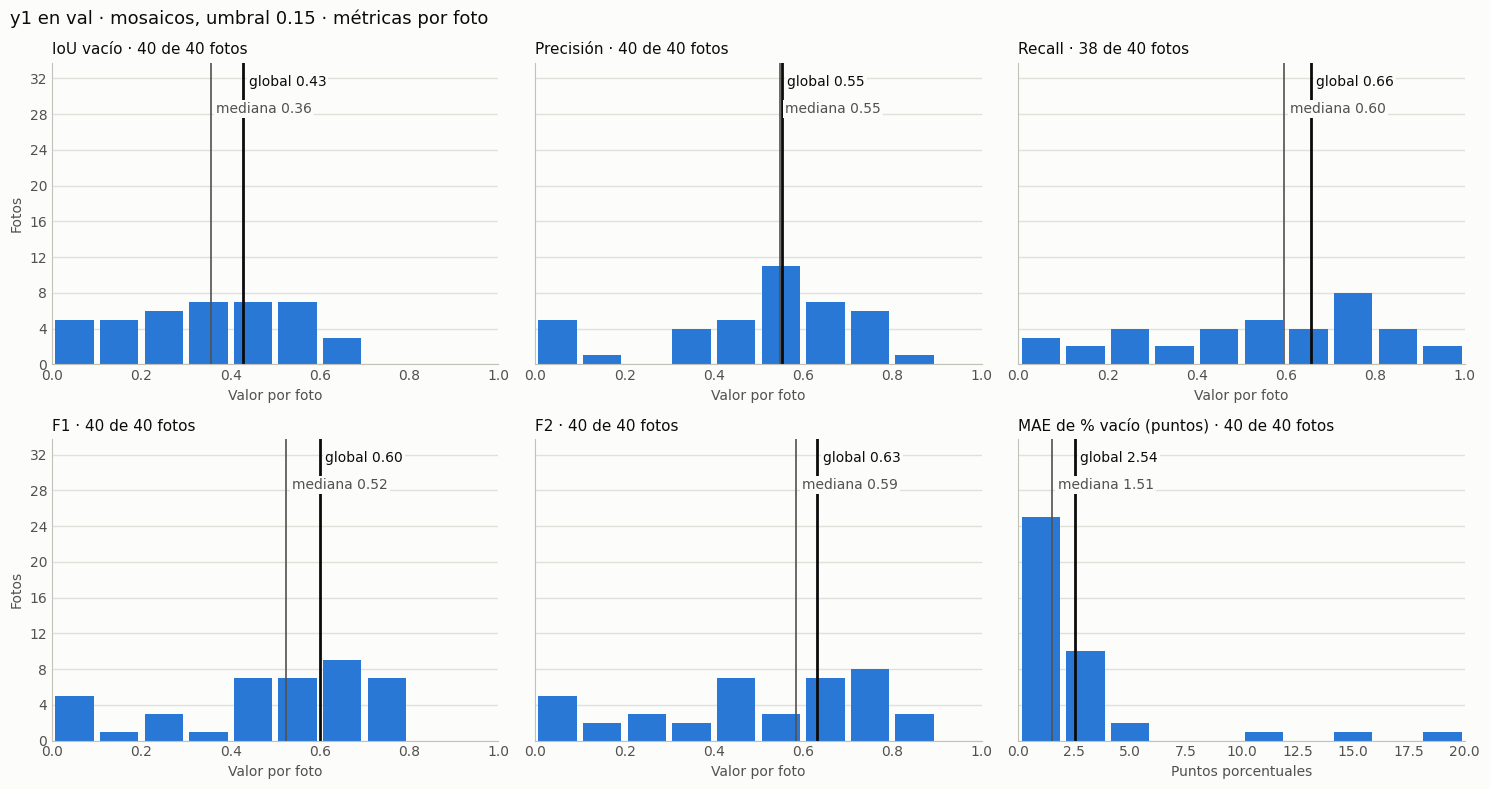

val
                metrica  global  fotos  mediana   p25   p75  minimo  maximo
              IoU vacío   0.428     40    0.356 0.235 0.478   0.000   0.627
              Precisión   0.553     40    0.547 0.411 0.658   0.000   0.814
                 Recall   0.656     38    0.596 0.320 0.752   0.000   0.962
                     F1   0.600     40    0.525 0.380 0.646   0.000   0.771
                     F2   0.632     40    0.585 0.315 0.709   0.000   0.845
MAE de % vacío (puntos)   2.539     40    1.510 0.488 2.953   0.087  19.032
MAE del modelo 2.54 | responder siempre 2.9 % (mediana de train) 2.57 | mejor constante posible, conociendo el conjunto 2.36


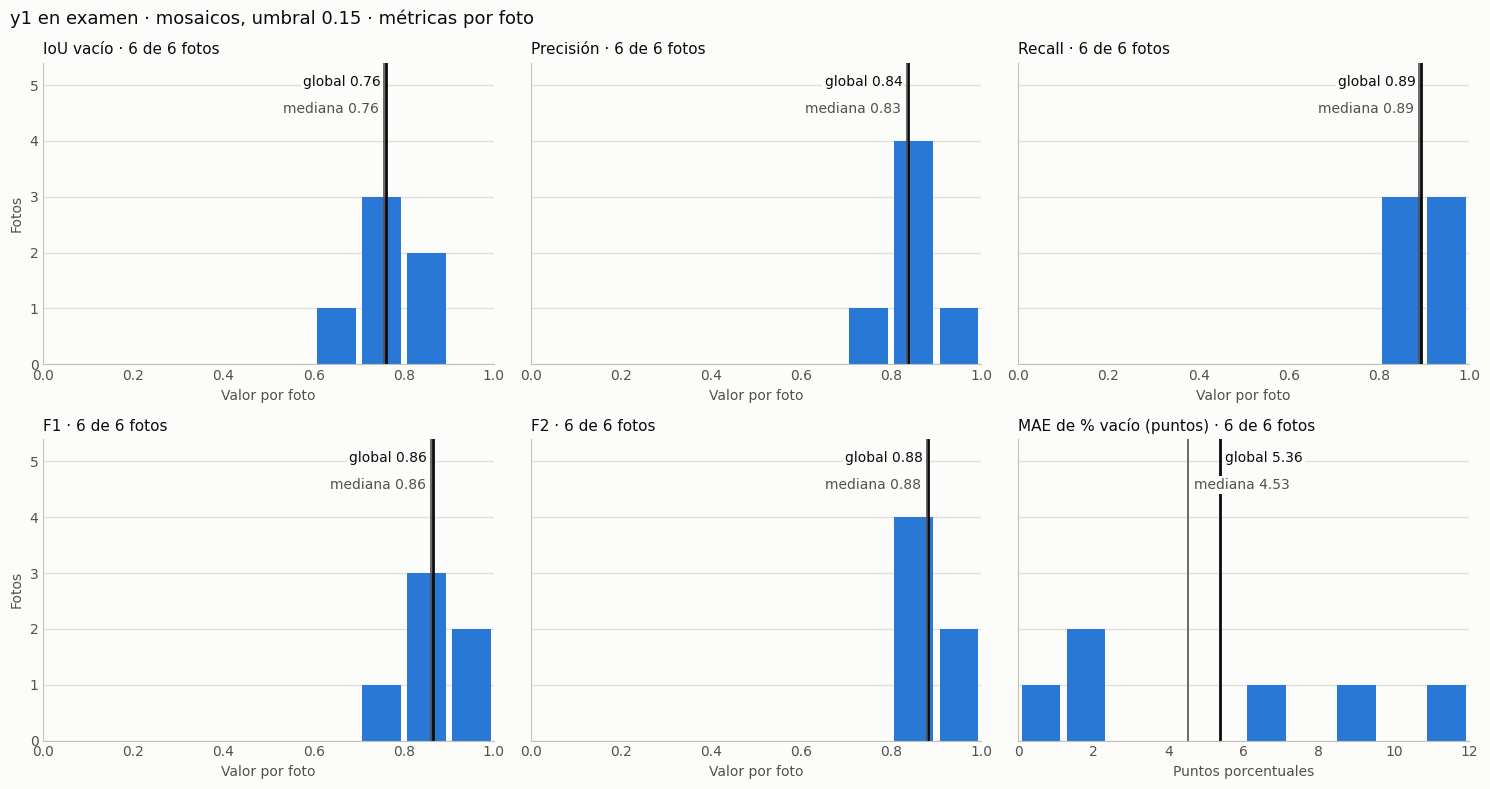

examen
                metrica  global  fotos  mediana   p25   p75  minimo  maximo
              IoU vacío   0.761      6    0.756 0.739 0.817   0.658   0.846
              Precisión   0.836      6    0.834 0.829 0.869   0.753   0.903
                 Recall   0.894      6    0.890 0.871 0.913   0.839   0.956
                     F1   0.864      6    0.861 0.850 0.899   0.794   0.917
                     F2   0.882      6    0.878 0.862 0.908   0.820   0.940
MAE de % vacío (puntos)   5.364      6    4.526 1.688 8.420   1.102  11.573
MAE del modelo 5.36 | responder siempre 2.9 % (mediana de train) 49.72 | mejor constante posible, conociendo el conjunto 13.19


In [ ]:
# [7.5] Análisis del último modelo: métricas por foto en una grilla
SUPERFICIE,TINTA,TINTA_2,REJILLA,EJE_COLOR,SERIE="#fcfcfb","#0b0b0b","#52514e","#e1e0d9","#c3c2b7","#2a78d6"
ETIQUETAS_METRICAS={"iou":"IoU vacío","precision":"Precisión","recall":"Recall","f1":"F1","f2":"F2","error_pct":"MAE de % vacío (puntos)"}
ESTILO_GRAFICOS={"figure.facecolor":SUPERFICIE,"axes.facecolor":SUPERFICIE,"savefig.facecolor":SUPERFICIE,"axes.edgecolor":EJE_COLOR,
                 "axes.labelcolor":TINTA_2,"text.color":TINTA,"xtick.color":TINTA_2,"ytick.color":TINTA_2,"axes.spines.top":False,"axes.spines.right":False}

def metricas_por_foto(regs: list) -> pd.DataFrame:
    """Una fila por foto. Sin denominador la métrica queda NaN: esa foto no puede medirla."""
    div=lambda a,b:a/b if b else float("nan")
    filas=[]
    for r in regs:
        tp,fp,fn=r["tp"],r["fp"],r["fn"]
        filas.append(dict(foto=r["foto"],tp=tp,fp=fp,fn=fn,iou=div(tp,tp+fp+fn),precision=div(tp,tp+fp),recall=div(tp,tp+fn),
                          f1=div(2*tp,2*tp+fp+fn),f2=div(5*tp,5*tp+4*fn+fp),error_pct=float("nan") if r["err_foto"] is None else float(r["err_foto"])))
    return pd.DataFrame(filas)

def valores_globales(regs: list, cfg) -> dict:
    """Los mismos valores de la tabla de [7.3]: suman los píxeles de todas las fotos antes de dividir."""
    m=resumir(regs,cfg)
    return dict(iou=m["iou_vacio"],precision=m["p_pixel"],recall=m["r_pixel"],f1=m["f1_pixel"],f2=m["f2_pixel"],error_pct=m["mae_foto"])

def tabla_metricas(df: pd.DataFrame, globales: dict) -> pd.DataFrame:
    filas=[]
    for k,etiqueta in ETIQUETAS_METRICAS.items():
        v=df[k].dropna()
        filas.append(dict(metrica=etiqueta,global_=globales[k],fotos=len(v),mediana=v.median(),p25=v.quantile(.25),p75=v.quantile(.75),minimo=v.min(),maximo=v.max()))
    return pd.DataFrame(filas).rename(columns={"global_":"global"})

def grilla_metricas(df: pd.DataFrame, globales: dict, titulo: str, ruta: Path) -> None:
    """Un panel por métrica: cuántas fotos caen en cada rango, con el valor global y la mediana marcados."""
    with plt.rc_context(ESTILO_GRAFICOS):
        fig,ejes=plt.subplots(2,3,figsize=(15,8),sharey=True)
        fig.suptitle(titulo,x=.01,ha="left",fontsize=13);maximo=1
        for ax,(k,etiqueta) in zip(ejes.ravel(),ETIQUETAS_METRICAS.items()):
            v=df[k].dropna().to_numpy()
            tope=max(1,math.ceil(float(v.max()))) if k=="error_pct" and len(v) else 1
            cuentas,bordes=np.histogram(v,bins=10,range=(0,tope));maximo=max(maximo,int(cuentas.max()))
            ax.bar((bordes[:-1]+bordes[1:])/2,cuentas,width=.86*(bordes[1]-bordes[0]),color=SERIE)
            ax.set_xlim(0,tope);ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
            ax.grid(axis="y",color=REJILLA,linewidth=1);ax.set_axisbelow(True);ax.tick_params(length=0)
            ax.set_title(f"{etiqueta} · {len(v)} de {len(df)} fotos",loc="left",fontsize=11)
            ax.set_xlabel("Puntos porcentuales" if k=="error_pct" else "Valor por foto")
            marcas=[("global",globales[k],TINTA,.96)]+([("mediana",float(np.median(v)),TINTA_2,.87)] if len(v) else [])
            for nombre,valor,color,altura in marcas:
                if valor is None or not math.isfinite(float(valor)): continue
                ax.axvline(valor,color=color,linewidth=2 if nombre=="global" else 1.2)
                derecha=valor>.72*tope
                ax.text(valor+(-.012 if derecha else .012)*tope,altura,f"{nombre} {valor:.2f}",transform=ax.get_xaxis_transform(),
                        ha="right" if derecha else "left",va="top",fontsize=10,color=color,bbox=dict(facecolor=SUPERFICIE,edgecolor="none",pad=1.5))
        for ax in ejes[:,0]: ax.set_ylabel("Fotos")
        ejes[0,0].set_ylim(0,1.35*maximo)  # el espacio superior deja las etiquetas sobre las barras
        fig.tight_layout();fig.savefig(ruta,dpi=110,bbox_inches="tight");plt.show();plt.close(fig)

def referencia_constante(fotos_train: list, fotos: list) -> dict:
    """Error de responder siempre el mismo % vacío. Si el modelo no le gana a la mediana de train, su MAE no dice mucho."""
    leer=lambda fs:np.array([x for x in (pct_vacio(cv2.imread(str(ruta_mascara(f)),0)) for f in fs) if x is not None],float)
    reales=leer(fotos);constante=float(np.median(leer(fotos_train)))
    return dict(constante=constante,mae=float(np.abs(reales-constante).mean()),mae_mejor_constante=float(np.abs(reales-np.median(reales)).mean()))

ANALISIS=[("val",VAL,EVAL_CANDIDATO)]+([("examen",EXAMEN,EVAL_EXAMEN)] if EVAL_EXAMEN else [])
METRICAS_FOTO={}
for _conjunto,_fotos,_ev in ANALISIS:
    _df=metricas_por_foto(_ev["regs"]);_glob=valores_globales(_ev["regs"],CFG);METRICAS_FOTO[_conjunto]=_df
    _tp,_fp,_fn=_df[["tp","fp","fn"]].sum()
    assert abs(_tp/max(1,_tp+_fp+_fn)-_glob["iou"])<1e-9 and abs(_df["error_pct"].mean()-_glob["error_pct"])<1e-9,"La grilla debe coincidir con [7.3]"
    _id=_ev["meta"]["id"][:8];_op=_ev["meta"]["operacion"]
    grilla_metricas(_df,_glob,f"{EXPERIMENTO} en {_conjunto} · {_op['modo']}, umbral {_op['umbral']} · métricas por foto",RUTAS["resultados"]/f"analisis_metricas_{_conjunto}_{_id}.png")
    _tabla=tabla_metricas(_df,_glob);guardar_csv(_tabla,RUTAS["resultados"]/f"analisis_resumen_{_conjunto}_{_id}.csv")
    guardar_csv(_df.sort_values("iou"),RUTAS["resultados"]/f"analisis_por_foto_{_conjunto}_{_id}.csv")
    print(_conjunto);print(_tabla.round(3).to_string(index=False))
    _ref=referencia_constante([f for f in FOTOS if f["split"]=="train" and not f["externa"] and not f.get("es_extrema")],_fotos)
    print(f"MAE del modelo {_glob['error_pct']:.2f} | responder siempre {_ref['constante']:.1f} % (mediana de train) {_ref['mae']:.2f} | mejor constante posible, conociendo el conjunto {_ref['mae_mejor_constante']:.2f}")


In [ ]:
# [7.6] Imágenes predichas y matriz de confusión del último modelo
FOTOS_POR_GRUPO=3       # peores, intermedias y mejores según IoU por foto
VER_TODAS_LAS_FOTOS=False
CLASES_MATRIZ=("Fondo","Ocupado","Vacío")
RGB_OCUPADO,RGB_VACIO=(59,130,246),(250,204,0)  # los mismos de pintar()
RGB_ACIERTO,RGB_FALSO,RGB_ESCAPADO=(27,175,122),(235,104,52),(74,58,167)
RAMPA_AZUL=matplotlib.colors.LinearSegmentedColormap.from_list("rampa_azul",["#cde2fb","#86b6ef","#3987e5","#1c5cab","#0d366b"])

def elegir_fotos(df: pd.DataFrame, n: int, todas: bool=False) -> list:
    """Devuelve (grupo, foto) ordenado por IoU. Las fotos sin IoU medible no se pueden ordenar y solo aparecen con `todas`."""
    orden=df.sort_values("iou",na_position="last")["foto"].tolist();medibles=df["iou"].notna().sum()
    if todas: return [("foto",f) for f in orden]
    medio=max(0,(medibles-n)//2)
    salida=[("peor",f) for f in orden[:n]]+[("intermedia",f) for f in orden[medio:medio+n]]+[("mejor",f) for f in orden[max(0,medibles-n):medibles][::-1]]
    vistas=set();return [(g,f) for g,f in salida if not (f in vistas or vistas.add(f))]

def predecir_conjunto(seg, fotos: list, elegidas: set, cfg) -> tuple:
    """Predice cada foto una vez: acumula la matriz real x predicho sin IGNORAR y conserva solo los mapas a mostrar."""
    matriz=np.zeros((3,3),np.int64);mapas={}
    for f in fotos:
        img=leer_imagen(f["ruta"],cfg);real=cv2.imread(str(ruta_mascara(f)),0);mapa=seg.mapa(img)
        if real is None or real.shape!=mapa.shape: raise ValueError(f"Máscara inválida: {f['nombre']}")
        v=real!=IGNORAR
        matriz+=np.bincount(3*real[v].astype(np.int64)+mapa[v],minlength=9).reshape(3,3)
        if f["nombre"] in elegidas: mapas[f["nombre"]]=mapa
    return matriz,mapas

def mapa_errores(img: np.ndarray, mapa: np.ndarray, real: np.ndarray) -> np.ndarray:
    """Foto en gris con los aciertos y errores de vacío pintados encima. Lo ignorado queda sin color."""
    gris=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY);salida=np.stack([gris]*3,-1).astype(np.float32)*.6+90
    pv,gv,_,_=pares_validos(mapa,real)
    for m,rgb in ((pv&gv,RGB_ACIERTO),(pv&~gv,RGB_FALSO),(~pv&gv,RGB_ESCAPADO)):
        salida[m]=.2*salida[m]+.8*np.array(rgb,np.float32)
    return np.clip(salida,0,255).astype(np.uint8)

def figura_predicciones(fotos: list, elegidas: list, mapas: dict, df: pd.DataFrame, titulo: str, ruta: Path, cfg) -> None:
    por_nombre={f["nombre"]:f for f in fotos};datos=df.set_index("foto")
    leyenda=[("Ocupado",RGB_OCUPADO),("Vacío",RGB_VACIO),("Vacío acertado",RGB_ACIERTO),("Falso positivo",RGB_FALSO),("Vacío no detectado",RGB_ESCAPADO)]
    with plt.rc_context(ESTILO_GRAFICOS):
        fig,ejes=plt.subplots(len(elegidas),4,figsize=(16,3.3*len(elegidas)),squeeze=False)
        for fila,(grupo,nombre) in zip(ejes,elegidas):
            f=por_nombre[nombre];img=leer_imagen(f["ruta"],cfg);real=cv2.imread(str(ruta_mascara(f)),0);mapa=mapas[nombre];d=datos.loc[nombre]
            paneles=((img[...,::-1],f"{grupo} · {nombre}"),(pintar(img,real)[...,::-1],"Real"),
                     (pintar(img,mapa)[...,::-1],f"Predicho · IoU {d['iou']:.2f} · P {d['precision']:.2f} · R {d['recall']:.2f}"),
                     (mapa_errores(img,mapa,real),f"Errores · error de % vacío {d['error_pct']:.1f}"))
            for ax,(imagen,texto) in zip(fila,paneles):
                ax.imshow(imagen);ax.set_title(texto,loc="left",fontsize=9);ax.axis("off")
        fig.suptitle(titulo,x=.01,ha="left",fontsize=13)
        fig.legend(handles=[matplotlib.patches.Patch(color=np.array(c)/255,label=t) for t,c in leyenda],loc="upper right",ncol=5,frameon=False,fontsize=10)
        fig.tight_layout(rect=(0,0,1,1-.5/(3.3*len(elegidas)+.5)));fig.savefig(ruta,dpi=75,bbox_inches="tight");plt.show();plt.close(fig)

def figura_confusion(matriz: np.ndarray, titulo: str, ruta: Path) -> None:
    """Dos lecturas de la misma matriz: por clase real (diagonal = recall) y por predicción (diagonal = precisión)."""
    with np.errstate(divide="ignore",invalid="ignore"):
        por_real=matriz/matriz.sum(1,keepdims=True);por_pred=matriz/matriz.sum(0,keepdims=True)
    fondo=RAMPA_AZUL.copy();fondo.set_bad(REJILLA)
    with plt.rc_context(ESTILO_GRAFICOS):
        fig,ejes=plt.subplots(1,2,figsize=(13,5.6))
        lecturas=((por_real,"De cada clase real, qué predijo (diagonal = recall)"),(por_pred,"De cada predicción, qué era (diagonal = precisión)"))
        for ax,(datos,subtitulo) in zip(ejes,lecturas):
            ax.pcolormesh(np.ma.masked_invalid(datos),cmap=fondo,vmin=0,vmax=1,edgecolors=SUPERFICIE,linewidth=2)
            ax.invert_yaxis();ax.set_aspect("equal");ax.tick_params(length=0)
            ax.set_xticks(np.arange(3)+.5,CLASES_MATRIZ);ax.set_yticks(np.arange(3)+.5,CLASES_MATRIZ)
            ax.set_xlabel("Predicho");ax.set_ylabel("Real");ax.set_title(subtitulo,loc="left",fontsize=11)
            ax.spines[:].set_visible(False)
            for i in range(3):
                for j in range(3):
                    v=datos[i,j];texto="sin datos" if not math.isfinite(v) else f"{100*v:.1f} %\n{matriz[i,j]/1e6:.2f} M px"
                    ax.text(j+.5,i+.5,texto,ha="center",va="center",fontsize=11,color="#ffffff" if math.isfinite(v) and v>=.45 else TINTA)
        fig.suptitle(titulo,x=.01,ha="left",fontsize=13)
        fig.tight_layout();fig.savefig(ruta,dpi=110,bbox_inches="tight");plt.show();plt.close(fig)

for _conjunto,_fotos,_ev in ANALISIS:
    _df=METRICAS_FOTO[_conjunto];_id=_ev["meta"]["id"][:8]
    _elegidas=elegir_fotos(_df,FOTOS_POR_GRUPO,VER_TODAS_LAS_FOTOS)
    _matriz,_mapas=predecir_conjunto(SEGMENTADOR_CANDIDATO,_fotos,{f for _,f in _elegidas},CFG)
    # La matriz sale de una predicción nueva; debe reproducir la tabla de [7.3] salvo diferencias numéricas mínimas.
    _m=_ev["metricas"]
    if _matriz[2,2]: assert abs(_matriz[2,2]/_matriz[2].sum()-_m["r_pixel"]["valor"])<1e-3 and abs(_matriz[2,2]/_matriz[:,2].sum()-_m["p_pixel"]["valor"])<1e-3,"La matriz debe coincidir con [7.3]"
    figura_confusion(_matriz,f"{EXPERIMENTO} en {_conjunto} · matriz de confusión por píxel, sin IGNORAR",RUTAS["resultados"]/f"analisis_confusion_{_conjunto}_{_id}.png")
    figura_predicciones(_fotos,_elegidas,_mapas,_df,f"{EXPERIMENTO} en {_conjunto} · fotos predichas",RUTAS["resultados"]/f"analisis_fotos_{_conjunto}_{_id}.png",CFG)
    _tabla=pd.DataFrame(_matriz,index=CLASES_MATRIZ,columns=CLASES_MATRIZ);guardar_csv(_tabla.reset_index(names="real"),RUTAS["resultados"]/f"analisis_confusion_{_conjunto}_{_id}.csv")
    print(_conjunto,"· píxeles, filas = real y columnas = predicho");print(_tabla.to_string())


Output hidden; open in https://colab.research.google.com to view.

# Validación revisada y curvas de precisión-recall

**Por qué existe:** en una revisión a ciegas de las 245 zonas más grandes donde `e1` o `d1` discrepaban de la etiqueta en val, menos de una décima parte del área de los "falsos positivos" resultó claramente no vacía, y un tercio del área de los "vacíos no detectados" tenía etiqueta errónea. Ejemplos: producto, piso o cartel marcados como vacío, y trapecios que cubren solo parte de un hueco. Por eso val castiga aciertos del modelo.

**Qué hace `[7.7]`:** predice val una vez y mide con tres versiones de la etiqueta:
- **Original:** la de `[7.3]` y la compuerta. No cambia.
- **Sin errores claros:** excluye las zonas que la revisión marcó como erróneas.
- **Revisada:** también excluye las dudosas, como refrigeradores con reflejos, fotos quemadas o franjas de repisa delante del producto.

Excluir solo quita castigos: ninguna zona se convierte en acierto. La tabla y la comparación pareada usan el mismo punto de operación de cada modelo, y `AP` resume toda la curva.

**Cómo leerlo:** si la curva completa se mueve hacia arriba y a la derecha, el modelo mejoró. Si solo se mueve el punto sobre la misma curva, cambió precisión por recall.

**Límites:**
- La revisión la hizo Claude mirando recortes, sin ver quién decía qué. No reemplaza a anotadores humanos independientes.
- Solo se revisaron las zonas de los modelos ya evaluados. Las zonas nuevas de un modelo posterior siguen contando como error hasta revisarlas.
- Val sigue siendo de las mismas visitas que train. Estas cifras no estiman el rendimiento en una tienda nueva.
- La compuerta `[9.1]` sigue usando la etiqueta original.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

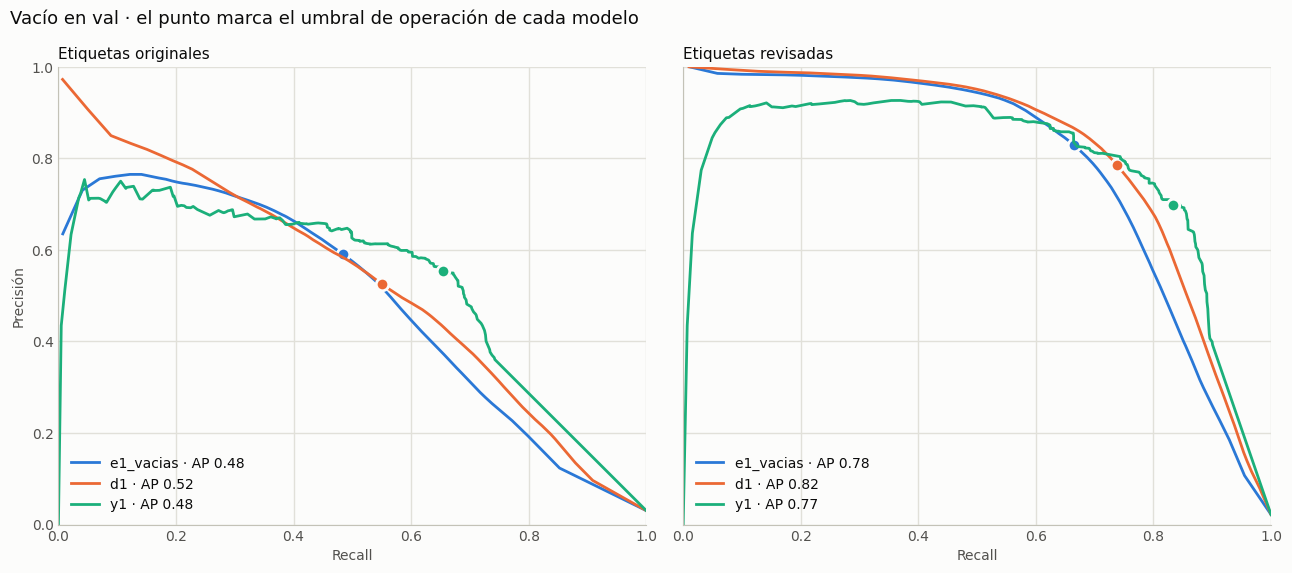

   modelo          etiquetas  umbral   iou  precision  recall    ap  p_region  r_region
e1_vacias           Original    0.50 0.362      0.591   0.483 0.479       NaN       NaN
e1_vacias Sin errores claros    0.50 0.471      0.744   0.561 0.660       NaN       NaN
e1_vacias           Revisada    0.50 0.585      0.829   0.665 0.781     0.595     0.535
       d1           Original    0.60 0.368      0.525   0.551 0.521       NaN       NaN
       d1 Sin errores claros    0.60 0.482      0.666   0.635 0.689       NaN       NaN
       d1           Revisada    0.60 0.614      0.786   0.737 0.815     0.486     0.620
       y1           Original    0.15 0.428      0.553   0.655 0.484       NaN       NaN
       y1 Sin errores claros    0.15 0.539      0.666   0.739 0.675       NaN       NaN
       y1           Revisada    0.15 0.612      0.699   0.832 0.768     0.496     0.709

Pareado en etiquetas revisadas: y1 frente a e1_vacias
            metrica  referencia  nuevo  ic95_bajo  ic95_alto  gan

In [ ]:
# [7.7] Validación revisada y curvas de precisión-recall de varios modelos
REFERENCIAS_REVISADO={"e1_vacias":(V6/"entrenamiento"/"e1_vacias"/"best.pt","mosaicos+tta",0.5),"d1":(SALIDA/"entrenamiento"/"d1"/"best.pt","mosaicos+tta",0.6)}
COLORES_MODELOS=("#2a78d6","#eb6834","#1baf7a")  # primeras tres series de la paleta validada; el color sigue al modelo
VERSIONES_ETIQUETA=(("original","Original"),("sin_errores","Sin errores claros"),("revisada","Revisada"))

def val_revisada(fotos,ruta,dudosas):
    """Copia de val con otra máscara. Solo excluye zonas revisadas; nunca agrega aciertos."""
    zonas=leer_revision(ruta,dudosas);carpeta=RUTAS["mascaras"]/("val_revisada" if dudosas else "val_sin_errores");salida=[]
    for f in fotos:
        c=dict(f,excluir=zonas.get(f["nombre"],[]),mascara=str(carpeta/f"{Path(f['nombre']).stem}.png"))
        escribir_imagen(c["mascara"],mascara_semantica(c));salida.append(c)
    return salida

def histograma_pr(p_vacio,gt):
    """Píxeles de vacío real y del resto por nivel de probabilidad: permite recalcular P y R en cualquier umbral."""
    v=gt!=IGNORAR;q=np.round(p_vacio*255).astype(np.uint8)
    return np.stack([np.bincount(q[v&(gt==VACIO)],minlength=256),np.bincount(q[v&(gt!=VACIO)],minlength=256)]).astype(np.int64)

def curva_pr(h):
    """Precisión y recall de umbral alto a bajo, y el área bajo la curva (AP)."""
    tp,fp=np.cumsum(h[0][::-1]),np.cumsum(h[1][::-1])
    with np.errstate(divide="ignore",invalid="ignore"): precision=np.where(tp+fp>0,tp/(tp+fp),np.nan)
    recall=tp/max(1,int(h[0].sum()))
    return precision,recall,float(np.sum(np.diff(recall,prepend=0)*np.nan_to_num(precision)))

def en_umbral(h,umbral):
    nivel=math.ceil(umbral*255);tp,fn,fp=int(h[0][nivel:].sum()),int(h[0][:nivel].sum()),int(h[1][nivel:].sum())
    return dict(iou=tp/max(1,tp+fp+fn),p=tp/max(1,tp+fp),r=tp/max(1,tp+fn))

def evaluar_revisado(nombre,seg,conjuntos,cfg):
    """Un solo recorrido: histogramas en las tres etiquetas y registros en la revisada. Se guarda para no repetirlo en cada corrida."""
    llave=huella_json(dict(pesos=getattr(seg.modelo,"stockeye_sha256",None),modo=seg.modo,umbral=seg.umbral,fotos={k:snapshot_datos(v) for k,v in conjuntos.items()}))[:12]
    ruta=RUTAS["resultados"]/f"revisado_{nombre}_{llave}.json"
    if ruta.exists(): return json.loads(ruta.read_text())
    hist={k:np.zeros((2,256),np.int64) for k in conjuntos};regs=[]
    for i,f in enumerate(conjuntos["original"]):
        img=leer_imagen(f["ruta"],cfg);p=seg.prob(img);mapa=mapa_desde_prob(p,seg.umbral)
        for k,fotos in conjuntos.items(): hist[k]+=histograma_pr(p[VACIO],cv2.imread(str(ruta_mascara(fotos[i])),0))
        regs.append(medir_foto(conjuntos["revisada"][i],mapa,img,cfg))
    datos=dict(nombre=nombre,modo=seg.modo,umbral=seg.umbral,regs=regs,hist={k:v.tolist() for k,v in hist.items()})
    guardar_json(datos,ruta);return datos

def figura_pr(datos,ruta):
    with plt.rc_context(ESTILO_GRAFICOS):
        fig,ejes=plt.subplots(1,2,figsize=(13,5.8),sharex=True,sharey=True)
        for ax,(clave,titulo) in zip(ejes,(("original","Etiquetas originales"),("revisada","Etiquetas revisadas"))):
            for d,color in zip(datos,COLORES_MODELOS):
                p,r,ap=curva_pr(np.array(d["hist"][clave]));k=255-math.ceil(d["umbral"]*255)
                ax.plot(r,p,color=color,linewidth=2,label=f"{d['nombre']} · AP {ap:.2f}")
                ax.plot(r[k],p[k],"o",color=color,markersize=9,markeredgecolor=SUPERFICIE,markeredgewidth=2)
            ax.set(xlim=(0,1),ylim=(0,1),xlabel="Recall");ax.grid(color=REJILLA,linewidth=1);ax.set_axisbelow(True);ax.tick_params(length=0)
            ax.set_title(titulo,loc="left",fontsize=11);ax.legend(frameon=False,loc="lower left",fontsize=10)
        ejes[0].set_ylabel("Precisión")
        fig.suptitle("Vacío en val · el punto marca el umbral de operación de cada modelo",x=.01,ha="left",fontsize=13)
        fig.tight_layout();fig.savefig(ruta,dpi=110,bbox_inches="tight");plt.show();plt.close(fig)

if not RUTAS["revision"].exists():
    print("Sin revision_etiquetas.json: se omite la validación revisada. Súbelo a",RUTAS["revision"])
else:
    CONJUNTOS_VAL=dict(original=VAL,sin_errores=val_revisada(VAL,RUTAS["revision"],False),revisada=val_revisada(VAL,RUTAS["revision"],True))
    RESULTADOS_REVISADO=[]
    for _nombre,(_ruta,_modo,_umbral) in REFERENCIAS_REVISADO.items():
        if _nombre==EXPERIMENTO or not Path(_ruta).exists(): continue
        _modelo=cargar_segformer(_ruta,CFG)
        RESULTADOS_REVISADO.append(evaluar_revisado(_nombre,SegmentadorSegFormer(_modelo,CFG,_modo,_umbral),CONJUNTOS_VAL,CFG))
        del _modelo
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    RESULTADOS_REVISADO.append(evaluar_revisado(EXPERIMENTO,SEGMENTADOR_CANDIDATO,CONJUNTOS_VAL,CFG))
    # La etiqueta original debe reproducir [7.3] salvo el redondeo a 256 niveles, que en YOLO puede mover una instancia completa.
    _c=en_umbral(np.array(RESULTADOS_REVISADO[-1]["hist"]["original"]),UMBRAL)
    assert abs(_c["iou"]-EVAL_CANDIDATO["metricas"]["iou_vacio"]["valor"])<0.01,"La etiqueta original debe coincidir con [7.3]"
    figura_pr(RESULTADOS_REVISADO[-3:],RUTAS["resultados"]/f"revisado_pr_{EXPERIMENTO}.png")
    _filas=[]
    for d in RESULTADOS_REVISADO:
        _r=resumir(d["regs"],CFG)
        for k,etiqueta in VERSIONES_ETIQUETA:
            h=np.array(d["hist"][k]);m=en_umbral(h,d["umbral"])
            _filas.append(dict(modelo=d["nombre"],etiquetas=etiqueta,umbral=d["umbral"],iou=m["iou"],precision=m["p"],recall=m["r"],ap=curva_pr(h)[2],
                               p_region=_r["p_region"] if k=="revisada" else None,r_region=_r["r_region"] if k=="revisada" else None))
    TABLA_REVISADO=pd.DataFrame(_filas);guardar_csv(TABLA_REVISADO,RUTAS["resultados"]/f"revisado_tabla_{EXPERIMENTO}.csv")
    print(TABLA_REVISADO.round(3).to_string(index=False))
    for d in RESULTADOS_REVISADO[:-1]:
        print("\nPareado en etiquetas revisadas:",EXPERIMENTO,"frente a",d["nombre"])
        print(comparar_pareado(d["regs"],RESULTADOS_REVISADO[-1]["regs"],CFG).round(4).to_string(index=False))


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 8 · Comparación con v5 en el mismo examen
- **Objetivo:** tener una línea base medida con las mismas reglas.
- **Entradas:** `modelos/vigente.pt`. Si no está, la parte se omite.
- **Decisiones:**
  - v5 entrega polígonos de vacío y de góndola, así que se convierte al mismo mapa de clases y pasa por `evaluar`.
  - **Se mide v5 con foto completa y su umbral 0,20, no con el ensamble de mosaicos + TTA.** Por eso este resultado puede quedar por debajo de lo mejor de v5, y sirve como referencia de lo que aporta el cambio de enfoque, no como veredicto final.
  - Las cifras del notebook de v5 (R píxel 0,71 · P píxel 0,60 · MAE repisa 1,90) se obtuvieron con otra forma de medir, sin `dev`, y no son directamente comparables.
- **Validación:** ambos modelos usan las mismas fotos y etiquetas. **Si `vigente.pt` se entrenó con un split antiguo, ya vio fotos de este val y sus cifras salen infladas**; la celda lo avisa cuando no hay `split_v3.json`.

**Texto corregido — documentación vigente del código actual.**

# Parte 8 · Comparación opcional con v5

Desactivada por defecto. Requiere `ultralytics` y pesos YOLO de v5. Verifica nombres de clases; no confunde pesos SegFormer con YOLO. Se compara en val con las mismas reglas, sin examinar automáticamente las fotos finales. Confirma que v5 no entrenó con val antes de interpretar las cifras.


In [ ]:
# [8.1] Comparación opcional con v5; no interviene en la promoción de SegFormer
class SegmentadorV5:
    def __init__(self,ruta,conf=0.20,imgsz=1280):
        from ultralytics import YOLO
        self.modelo,self.conf,self.imgsz=YOLO(str(ruta)),conf,imgsz
        nombres={int(k):str(v).lower().strip() for k,v in self.modelo.names.items()}
        self.ocupado=[k for k,v in nombres.items() if v in ("gondola","góndola","ocupado")]
        self.vacio=[k for k,v in nombres.items() if v in ("vacio","vacío","empty")]
        if len(self.ocupado)!=1 or len(self.vacio)!=1: raise ValueError(f"Confirma las clases de v5 antes de comparar: {nombres}")
    def mapa(self,img):
        h,w=img.shape[:2];m=np.zeros((h,w),np.uint8)
        r=self.modelo.predict(img,imgsz=self.imgsz,conf=self.conf,retina_masks=True,verbose=False)[0]
        if r.masks is None: return m
        for clase,valor in ((self.ocupado[0],OCUPADO),(self.vacio[0],VACIO)):
            for mascara,cl in zip(r.masks.data.cpu().numpy(),r.boxes.cls.cpu().numpy().astype(int)):
                if cl==clase: m[cv2.resize((mascara>0.5).astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)>0]=valor
        return m

COMPARAR_V5=os.environ.get("SV6_COMPARAR_V5","0")=="1"
SEG_V5=None
if COMPARAR_V5:
    if not RUTAS["pesos_v5"].exists(): raise FileNotFoundError(RUTAS["pesos_v5"])
    print("Comparación descriptiva: antes de interpretarla confirma que v5 no entrenó con estas fotos de val.")
    SEG_V5=SegmentadorV5(RUTAS["pesos_v5"])
    EVAL_V5=evaluar(SEG_V5,VAL,"v5_comparacion",CFG)
else:
    print("Comparación v5 desactivada; ultralytics solo se necesita si activas esta opción.")


Comparación v5 desactivada; ultralytics solo se necesita si activas esta opción.


In [ ]:
# [8.2] Comparación visual en validación, con IGNORAR excluido de IoU
if SEG_V5 is not None:
    muestra=random.Random(CFG.semilla).sample(VAL,min(6,len(VAL)))
    fig,ejes=plt.subplots(len(muestra),3,figsize=(15,3.6*len(muestra)),squeeze=False)
    for fila,f in zip(ejes,muestra):
        img=leer_imagen(f["ruta"],CFG);real=cv2.imread(str(ruta_mascara(f)),0)
        for ax,titulo,mapa in zip(fila,("Real","v5","v6 candidato"),(real,SEG_V5.mapa(img),SEGMENTADOR_CANDIDATO.mapa(img))):
            pv,gv,_,_=pares_validos(mapa,real)
            ax.imshow(pintar(img,mapa)[...,::-1]);ax.set_title(f"{titulo} · IoU vacío {iou(pv,gv):.2f}");ax.axis("off")
    fig.savefig(RUTAS["resultados"]/"comparacion_v5_v6.png",dpi=110,bbox_inches="tight");plt.show();plt.close(fig)


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 9 · Compuerta de promoción
- **Objetivo:** decidir sin intervención si un modelo reemplaza al vigente. El reentrenamiento automático (Iteración 3) la usará tal cual.
- **Salidas:** `modelos/segmentador_vigente.pt` y `modelos/versiones.json`.
- **Regla:** ninguna métrica de `val` ni de `examen_vacias` puede empeorar fuera de su intervalo. Promueve si además sube el recall en `examen_vacias`; sin ese examen, si mejora al menos la mitad de las métricas de `val`. Si no hay modelo vigente, el primero entra como referencia.
- **Límite conocido:** un val congelado no ve cambios de la tienda. Conviene que alguien etiquete unas pocas fotos nuevas cada cierto tiempo.
- **Pendiente:** selección de pseudo-etiquetas y disparo automático, que se construyen cuando este modelo esté validado.
- **Validación:** casos de prueba con decisión conocida.

**Texto corregido — documentación vigente del código actual.**

# Parte 9 · Promoción y modelo vigente

Con YOLO (`y1`), esta etapa solo informa qué diría la compuerta: no registra versión ni cambia el modelo vigente.

La compuerta rechaza métricas obligatorias ausentes, `NaN`, infinitos, muestras insuficientes e incumplimientos de precisión, cobertura, tiempo y memoria. El primer modelo también debe pasar estas comprobaciones.

Con un vigente comparable, exige cuatro mejoras mayores que la tolerancia configurada, ninguna regresión protegida y ningún aumento de góndolas rojas omitidas o alertas falsas. Es una regla práctica sobre valores puntuales; no se presenta como prueba estadística de superioridad. No recibe el examen final.

Cada bundle inmutable contiene pesos, arquitectura, configuración, modo, umbral e identidades verificables. El registro atómico determina cuál está vigente. `[9.2]` carga su configuración guardada, sin heredar la del experimento actual. Un candidato rechazado no sustituye al vigente.


In [ ]:
# [9.1] Compuerta cerrada ante datos inválidos y versiones inmutables
CLAVES_COMPUERTA={"iou_vacio":1,"p_pixel":1,"r_pixel":1,"iou_gondola":1,"gondolas_encontradas":1,
                   "mae_foto":-1,"mae_gondola":-1,"mae_repisa_condicionada":-1}
CLAVES_OBLIGATORIAS=tuple(CLAVES_COMPUERTA)+("falsas_por_foto","rojas_reales_gondola","escapadas_gondola","alertas_falsas_gondola","p95_s","vram_gb","ram_gb")

def validar_evaluacion(ev,cfg):
    meta=ev.get("meta",{});metricas=ev.get("metricas",{})
    if meta.get("examen_final"): return False,"El examen final no puede participar en la promoción"
    if meta.get("esquema")!=METRICAS_VERSION or meta.get("pipeline")!=PIPELINE_VERSION: return False,"Protocolo de métricas incompatible"
    if int(meta.get("n_fotos",0))<cfg.min_fotos_validacion: return False,"Validación insuficiente en número de fotos"
    if not meta.get("snapshot_validacion") or not meta.get("referencia_hash"): return False,"Falta identificar las fotos o la referencia de evaluación"
    for k in CLAVES_OBLIGATORIAS:
        v=metricas.get(k,{})
        try:
            valor=float(v["valor"]);ic=[float(x) for x in v["ic95"]]
            if not math.isfinite(valor) or len(ic)!=2 or not all(math.isfinite(x) for x in ic) or ic[0]>ic[1]: raise ValueError()
            if valor<0 or (k in ("iou_vacio","p_pixel","r_pixel","iou_gondola","gondolas_encontradas") and valor>1): raise ValueError()
            if k.startswith("mae_") and valor>100: raise ValueError()
        except (TypeError,ValueError,KeyError,OverflowError): return False,f"Métrica obligatoria ausente/no válida: {k}"
    valor=lambda k:float(metricas[k]["valor"])
    if valor("rojas_reales_gondola")>0:
        recall=metricas.get("recall_alertas_gondola",{}).get("valor")
        if recall is None or not math.isfinite(float(recall)) or not cfg.min_recall_alertas_promocion<=float(recall)<=1:
            return False,"Recall de alertas rojas inválido o bajo el mínimo técnico"
    for k,minimo in (("iou_vacio",cfg.min_iou_promocion),("p_pixel",cfg.min_precision),("r_pixel",cfg.min_recall_promocion),("gondolas_encontradas",cfg.min_cobertura_promocion)):
        if valor(k)<minimo: return False,f"{k}={valor(k):.3f} por debajo del mínimo técnico {minimo}"
    if valor("p95_s")>cfg.tiempo_max_s: return False,"El percentil 95 excede el presupuesto de tiempo"
    if cfg.max_vram_inferencia_gb is not None and valor("vram_gb")>cfg.max_vram_inferencia_gb: return False,"VRAM de inferencia excedida"
    if cfg.max_ram_gb is not None and valor("ram_gb")>cfg.max_ram_gb: return False,"RAM excedida"
    return True,"Evaluación válida"

def decidir_promocion(candidato,vigente,cfg):
    ok,motivo=validar_evaluacion(candidato,cfg)
    if not ok: return False,motivo
    if vigente is None: return True,"Primer modelo que cumple las comprobaciones y mínimos técnicos"
    ok,motivo=validar_evaluacion(vigente,cfg)
    if not ok: return False,"Reevalúa el vigente antes de comparar: "+motivo
    for k in ("esquema","pipeline","snapshot_validacion","referencia_hash"):
        if candidato["meta"][k]!=vigente["meta"][k]: return False,"Reevalúa el vigente con las mismas fotos y protocolo: "+k
    c,v=candidato["metricas"],vigente["metricas"]
    mejoran=[];empeoran=[]
    # Tolerancias prácticas explícitas, no una prueba de significación estadística.
    for k,signo in CLAVES_COMPUERTA.items():
        delta=signo*(float(c[k]["valor"])-float(v[k]["valor"]))
        tolerancia=cfg.tolerancia_mae_pp if k.startswith("mae_") else cfg.tolerancia_proporcion
        if delta>tolerancia: mejoran.append(k)
        if delta < -tolerancia: empeoran.append(k)
    for k in ("escapadas_gondola","alertas_falsas_gondola"):
        if c[k]["valor"]>v[k]["valor"]: empeoran.append(k)
    if empeoran: return False,"Empeoran métricas protegidas: "+", ".join(empeoran)
    if len(mejoran)<cfg.min_metricas_mejoran: return False,f"Mejoran {len(mejoran)} métricas; se requieren {cfg.min_metricas_mejoran}"
    return True,"Mejoran métricas sin deterioros protegidos: "+", ".join(mejoran)

def leer_versiones(carpeta):
    ruta=Path(carpeta)/"versiones.json"
    if not ruta.exists(): return []
    doc=json.loads(ruta.read_text())
    if not isinstance(doc,list) or any(r.get("esquema")!="stockeye-registro-2" for r in doc):
        raise ValueError("Registro incompatible; utiliza la carpeta corregido_v1/modelos")
    return doc

def exportar_bundle(ruta_pesos,cfg,modo,umbral,carpeta):
    if modo not in cfg.modos or not 0<float(umbral)<1: raise ValueError("Operación inválida")
    ruta_pesos=Path(ruta_pesos);carpeta=Path(carpeta)
    origen_sha=sha_archivo(ruta_pesos)
    identidad=dict(pipeline=PIPELINE_VERSION,pesos_origen_sha256=origen_sha,config=asdict(cfg),modo=modo,umbral=float(umbral))
    bundle_id=huella_json(identidad);destino=carpeta/"bundles"/bundle_id
    if destino.exists():
        comprobar_bundle(destino,bundle_id);return bundle_id,destino
    c=torch.load(ruta_pesos,map_location="cpu",weights_only=True)
    if not isinstance(c.get("modelo"),dict): raise ValueError("Checkpoint sin state_dict modelo")
    arquitectura=c.get("model_config")
    if arquitectura is None:
        # Importar un checkpoint antiguo exige obtener su configuración de arquitectura una sola vez.
        modelo=cargar_segformer(ruta_pesos,cfg,device="cpu");arquitectura=modelo.config.to_dict();del modelo
    destino.parent.mkdir(parents=True,exist_ok=True)
    temporal=Path(tempfile.mkdtemp(prefix=".bundle_",dir=destino.parent))
    try:
        torch.save(dict(modelo=c["modelo"]),temporal/"weights.pt")
        guardar_json(arquitectura,temporal/"model_config.json")
        manifest=dict(esquema="stockeye-bundle-1",bundle_id=bundle_id,identidad=identidad,
                      archivos={n:sha_archivo(temporal/n) for n in ("weights.pt","model_config.json")},
                      clases={"0":"fondo","1":"ocupado","2":"vacio","255":"ignorar"},
                      normalizacion=dict(media=[.485,.456,.406],desviacion=[.229,.224,.225],orden="RGB"))
        guardar_json(manifest,temporal/"manifest.json")
        temporal.rename(destino)
    finally:
        if temporal.exists(): shutil.rmtree(temporal)
    return bundle_id,destino

def comprobar_bundle(carpeta,bundle_id):
    carpeta=Path(carpeta);m=json.loads((carpeta/"manifest.json").read_text())
    if m.get("esquema")!="stockeye-bundle-1" or m.get("bundle_id")!=bundle_id or huella_json(m.get("identidad"))!=bundle_id:
        raise ValueError("Identidad del bundle inválida")
    if m["identidad"].get("pipeline")!=PIPELINE_VERSION: raise ValueError("Versión del pipeline incompatible")
    for nombre in ("weights.pt","model_config.json"):
        if sha_archivo(carpeta/nombre)!=m.get("archivos",{}).get(nombre): raise ValueError("Archivo de modelo alterado: "+nombre)
    return m

def registrar_version(evaluacion,cfg,modo,umbral,ruta_pesos,carpeta_modelos=None):
    meta=evaluacion.get("meta",{})
    if meta.get("pesos_sha256")!=sha_archivo(ruta_pesos): raise ValueError("La evaluación no corresponde a estos pesos")
    if json_canonico(meta.get("config_evaluacion"))!=json_canonico(asdict(cfg)): raise ValueError("La configuración no coincide con la evaluación")
    if meta.get("operacion")!={"modo":modo,"umbral":float(umbral)}: raise ValueError("Modo o umbral distintos de los evaluados")
    carpeta=Path(carpeta_modelos or RUTAS["modelos"]);carpeta.mkdir(parents=True,exist_ok=True)
    with bloqueo(carpeta/"versiones.lock"):
        reg=leer_versiones(carpeta);aprobados=[r for r in reg if r["promovido"]]
        vigente=aprobados[-1]["evaluacion"] if aprobados else None
        promover,motivo=decidir_promocion(evaluacion,vigente,cfg)
        identidad=huella_json(dict(pesos=sha_archivo(ruta_pesos),config=asdict(cfg),modo=modo,umbral=umbral,
                                  snapshot=evaluacion["meta"].get("snapshot_validacion"),referencia=evaluacion["meta"].get("referencia_hash")))
        if any(r["identidad_intento"]==identidad for r in reg):
            print("Esta combinación de pesos, operación, configuración y validación ya fue registrada");return False
        bundle_id=None
        if promover: bundle_id,_=exportar_bundle(ruta_pesos,cfg,modo,umbral,carpeta)
        version=f"v6c.{len(reg)+1}"
        reg.append(dict(esquema="stockeye-registro-2",version=version,fecha=datetime.now(timezone.utc).isoformat(),promovido=bool(promover),
                        motivo=motivo,identidad_intento=identidad,bundle_id=bundle_id,evaluacion=evaluacion))
        # Único punto de activación: el registro se reemplaza atómicamente DESPUÉS del bundle completo.
        guardar_json(reg,carpeta/"versiones.json")
    print(version,"promovido" if promover else "rechazado","|",motivo)
    return bool(promover)

if CFG.modelo_tipo=="yolo":
    # En esta etapa solo se informa: YOLO no registra versión ni cambia el modelo vigente.
    PROMOVIDO=False
    _aprobados=[r for r in leer_versiones(RUTAS["modelos"]) if r["promovido"]]
    print("Sin registrar. La compuerta diría:",decidir_promocion(EVAL_CANDIDATO,_aprobados[-1]["evaluacion"] if _aprobados else None,CFG))
else:
    PROMOVIDO=registrar_version(EVAL_CANDIDATO,CFG,MODO,UMBRAL,RUTA_CANDIDATO)


Sin registrar. La compuerta diría: (False, 'Empeoran métricas protegidas: p_pixel, iou_gondola, mae_foto, mae_gondola')


In [ ]:
# [9.2] Cargar una vez el modelo aprobado y SU configuración, incluso sin acceso a Hugging Face
@dataclass(frozen=True)
class ContextoInferencia:
    segmentador: SegmentadorSegFormer
    cfg: Config
    version: str
    bundle_id: str
    carpeta_bundle: Path
    promovido: bool=True

def cargar_vigente(carpeta_modelos,device=None):
    carpeta=Path(carpeta_modelos);reg=leer_versiones(carpeta)
    aprobados=[r for r in reg if r["promovido"]]
    if not aprobados: raise FileNotFoundError("Aún no hay un modelo promovido que cumpla la compuerta")
    r=aprobados[-1];bundle=carpeta/"bundles"/r["bundle_id"]
    manifest=comprobar_bundle(bundle,r["bundle_id"]);identidad=manifest["identidad"]
    cfg=config_desde_dict(identidad["config"])
    modelo=cargar_segformer(bundle/"weights.pt",cfg,device=device,model_config=json.loads((bundle/"model_config.json").read_text()))
    seg=SegmentadorSegFormer(modelo,cfg,identidad["modo"],identidad["umbral"])
    return ContextoInferencia(seg,cfg,r["version"],r["bundle_id"],bundle)

CONTEXTO_VIGENTE=None
if any(r["promovido"] for r in leer_versiones(RUTAS["modelos"])):
    CONTEXTO_VIGENTE=cargar_vigente(RUTAS["modelos"])
    print("Inferencia con",CONTEXTO_VIGENTE.version,"| bundle",CONTEXTO_VIGENTE.bundle_id[:12])
else:
    print("No hay modelo aprobado: se conservan las evaluaciones del candidato, sin usarlo como vigente.")


Inferencia con v6c.1 | bundle c4c14154ba67


**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 10 · Analizar una foto nueva
- **Objetivo:** el flujo de producción: entra una foto y sale un JSON, **sin ninguna etiqueta**. Es la base del script de inferencia que llamará el listener.
- **Salidas:** `inferencias/<foto>.json`, con el formato que recibirá la API.
- **Estados:**
  - `medida`: góndola completa en la foto.
  - `parcial`: toca el borde, el `%` no representa el mueble completo.
  - `sin_gondola`: no se encontró ninguna. **No equivale a 0 %.**
- **Validación:** corre con una foto de val, o con la que subas en Colab si `SUBIR_FOTO = True`.
- **Para probar fotos que el modelo nunca vio:** en la celda 10.2 pon `PROBAR_FOTOS = True`. No se usan para entrenar.

**Texto corregido — documentación vigente del código actual.**

# Parte 10 · Inferencia y artefactos

`analizar_foto(ruta, contexto)` requiere un contexto promovido. Usa la foto original y genera identificadores, fecha con zona horaria, versión del modelo, dimensiones, estados y resultados. `guardar_analisis` conserva bytes originales, máscara PNG, superposición y JSON en una carpeta por análisis. Los polígonos corresponden a la imagen original decodificada; la red puede redimensionar internamente y restaura el mapa a esas dimensiones.

`DEMOSTRAR_VIGENTE=True` prueba una foto conocida de val. `PROBAR_FOTOS=True` prueba imágenes nuevas por el mismo camino. Los fallos se muestran como errores, sin convertirlos en resultados válidos. No hay endpoints ni URLs simuladas.


In [ ]:
# [10.1] Foto original -> resultado con coordenadas originales y artefactos asociados
def fecha_utc(valor=None):
    fecha=datetime.now(timezone.utc) if valor is None else datetime.fromisoformat(str(valor).replace("Z","+00:00"))
    if fecha.tzinfo is None: raise ValueError("La fecha debe incluir zona horaria, por ejemplo 2026-10-31T12:00:00-03:00")
    return fecha.astimezone(timezone.utc).isoformat()

def analizar_foto(ruta,contexto,*,captura_id=None,capturada_en=None,sucursal_id=None,camara_id=None,rois=None,con_probabilidades=False):
    if not isinstance(contexto,ContextoInferencia) or not contexto.promovido:
        raise ValueError("La inferencia operativa requiere el contexto de un modelo promovido")
    cfg=contexto.cfg;seg=contexto.segmentador;ruta=Path(ruta)
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    sincronizar_cuda(seg.modelo);t0=time.perf_counter()
    img=leer_imagen(ruta,cfg);p=seg.prob(img);mapa=mapa_desde_prob(p,seg.umbral)
    gondolas=postprocesar_mapa(img,mapa,cfg,rois)
    sincronizar_cuda(seg.modelo);segundos=time.perf_counter()-t0;recursos=comprobar_recursos(cfg)
    if segundos>cfg.tiempo_max_s:
        raise TimeoutError(f"La inferencia tardó {segundos:.2f}s; presupuesto {cfg.tiempo_max_s}s. Ajusta el modo y vuelve a validarlo.")
    h,w=img.shape[:2]
    estado="sin_gondola" if not gondolas else "parcial" if any(g["estado"]=="parcial" for g in gondolas) else "medida"
    resultado=dict(esquema="stockeye-resultado-1",analisis_id=uuid.uuid4().hex,captura_id=str(captura_id or uuid.uuid4().hex),
                   foto=ruta.name,sha256_original=sha_archivo(ruta),fecha_analisis=fecha_utc(),
                   capturada_en=fecha_utc(capturada_en) if capturada_en is not None else None,
                   sucursal_id=sucursal_id,camara_id=camara_id,estado_proceso="completado",estado_medicion=estado,
                   version_modelo=contexto.version,bundle_id=contexto.bundle_id,pipeline=PIPELINE_VERSION,
                   operacion=dict(modo=seg.modo,umbral_vacio=seg.umbral),
                   dimensiones=dict(original=dict(ancho=w,alto=h),mapa=dict(ancho=w,alto=h)),
                   coordenadas="pixeles_de_imagen_original_decodificada_con_orientacion_exif",
                   segundos=round(segundos,4),alcance_tiempo="lectura_prediccion_geometria_sin_red_ni_guardado",recursos=recursos,
                   cantidad_gondolas_detectadas=len(gondolas),
                   unidad_gondola="roi_calibrada" if rois else "componente_semantico_sin_identidad_fisica",
                   cantidad_regiones_vacias=sum(g["cantidad_regiones_vacias"] for g in gondolas),gondolas=gondolas)
    return (resultado,mapa,p) if con_probabilidades else (resultado,mapa)

def guardar_analisis(ruta,resultado,mapa,carpeta):
    ruta=Path(ruta);carpeta=Path(carpeta);carpeta.mkdir(parents=True,exist_ok=True)
    if sha_archivo(ruta)!=resultado["sha256_original"]: raise ValueError("La foto cambió entre el análisis y el guardado")
    img=leer_imagen(ruta)
    if img.shape[:2]!=mapa.shape: raise ValueError("La máscara no corresponde a las dimensiones de la foto")
    destino=carpeta/resultado["analisis_id"]
    if destino.exists(): raise FileExistsError("Ese análisis ya existe; no se sobrescribe")
    temporal=Path(tempfile.mkdtemp(prefix=".analisis_",dir=carpeta))
    try:
        extension=ruta.suffix.lower() if ruta.suffix.lower() in (".jpg",".jpeg",".png",".webp",".bmp",".tif",".tiff") else ".img"
        original="original"+extension
        shutil.copyfile(ruta,temporal/original)
        escribir_imagen(temporal/"mascara.png",mapa.astype(np.uint8))
        escribir_imagen(temporal/"superpuesta.jpg",pintar(img,mapa))
        documento=dict(resultado)
        documento["archivos"]={"original":original,"mascara":"mascara.png","superpuesta":"superpuesta.jpg","resultado":"resultado.json"}
        documento["sha256_archivos"]={n:sha_archivo(temporal/n) for n in (original,"mascara.png","superpuesta.jpg")}
        guardar_json(documento,temporal/"resultado.json")
        temporal.rename(destino)
    finally:
        if temporal.exists(): shutil.rmtree(temporal)
    return destino

DEMOSTRAR_VIGENTE=os.environ.get("SV6_DEMOSTRAR","0")=="1"
if DEMOSTRAR_VIGENTE:
    if CONTEXTO_VIGENTE is None: raise RuntimeError("Primero debe existir un modelo promovido")
    ruta_demo=Path(VAL[0]["ruta"])
    print("Demostración con una foto de validación conocida; no es evidencia de generalización.")
    RESULTADO,MAPA=analizar_foto(ruta_demo,CONTEXTO_VIGENTE)
    print("Artefactos:",guardar_analisis(ruta_demo,RESULTADO,MAPA,RUTAS["resultados"]/"inferencias"))
    print(json.dumps(json_seguro(RESULTADO),ensure_ascii=False,indent=2))


In [ ]:
# [10.2] Probar imágenes sueltas con el MISMO camino de inferencia operativa
def probar_fotos(rutas,contexto,fotos_base,carpeta):
    conocidos={sha_archivo(f["ruta"]):f["split"] for f in fotos_base}
    pixeles={huella_pixeles(f["ruta"]):f["split"] for f in fotos_base}
    filas=[]
    for ruta in map(Path,rutas):
        try:
            conocido=conocidos.get(sha_archivo(ruta)) or pixeles.get(huella_pixeles(ruta))
            if conocido: print(ruta.name,"ya existe en",conocido,"; no cuenta como foto nunca vista")
            resultado,mapa=analizar_foto(ruta,contexto)
            destino=guardar_analisis(ruta,resultado,mapa,carpeta)
            filas.append(dict(foto=ruta.name,estado=resultado["estado_medicion"],gondolas=resultado["cantidad_gondolas_detectadas"],
                              conocida_en=conocido,analisis_id=resultado["analisis_id"],carpeta=str(destino),error=None))
        except (ValueError,OSError,RuntimeError,TimeoutError) as e:
            filas.append(dict(foto=ruta.name,estado="error",error=str(e)))
    return pd.DataFrame(filas)

PROBAR_FOTOS=os.environ.get("SV6_PROBAR","1")=="1"
if PROBAR_FOTOS:
    if CONTEXTO_VIGENTE is None: raise RuntimeError("No hay modelo promovido para probar fotos")
    if EN_COLAB:
        from google.colab import files
        rutas_prueba=[Path(n) for n in files.upload()]
    else:
        rutas_prueba=[p for p in Path(os.environ["SV6_CARPETA_PRUEBA"]).iterdir() if p.is_file()]
    print(probar_fotos(rutas_prueba,CONTEXTO_VIGENTE,FOTOS,RUTAS["resultados"]/"pruebas").to_string(index=False))


Saving 5.jpg to 5.jpg
 foto  estado  gondolas conocida_en                      analisis_id                                                                                             carpeta error
5.jpg parcial         1        None b2ca36f1fca94740a8f92de4e16117ce /content/drive/MyDrive/stockeye_v6/corregido_v1/resultados/pruebas/b2ca36f1fca94740a8f92de4e16117ce  None


In [ ]:
# #comprobar resultados  ctrl+k+u para descomentar

# # [10.2b] Comprobar una predicción y guardar sus resultados
# from google.colab import files
# from IPython.display import Image, display

# if CONTEXTO_VIGENTE is None:
#     raise RuntimeError("Ejecuta [9.2] para cargar el modelo aprobado.")

# subidos = files.upload()
# if len(subidos) != 1:
#     raise ValueError("Selecciona una sola imagen.")

# foto = Path(next(iter(subidos)))

# resultado, mapa = analizar_foto(foto, CONTEXTO_VIGENTE)

# carpeta = guardar_analisis(
#     foto,
#     resultado,
#     mapa,
#     RUTAS["resultados"] / "inferencias"
# )

# display(Image(filename=str(carpeta / "superpuesta.jpg"), width=900))

# display(pd.DataFrame(
#     resultado["gondolas"],
#     columns=[
#         "id_local",
#         "estado",
#         "pct_vacio_observado",
#         "semaforo",
#         "cantidad_regiones_vacias"
#     ]
# ))

# print("Estado:", resultado["estado_medicion"])
# print("Archivos guardados en:", carpeta)

**Texto anterior — registro histórico de v6.** Este bloque se conserva para comparar los cambios. Las instrucciones vigentes están en el bloque corregido que aparece inmediatamente debajo.

# Parte 11 · Subir fotos y reentrenar
- **Objetivo:** subir fotos nuevas, obtener su análisis y reentrenar sin que nadie dibuje bordes.
- **Entradas:** fotos subidas aquí o dejadas en `stockeye_v6/nuevas/entrada/`.
- **Salidas:** `nuevas/imagenes/`, `nuevas/mascaras/`, `nuevas/registro.csv`, un JSON por foto y, si gana, una nueva versión en `modelos/`.
- **Cómo usarlo:** la Parte 11 no hace nada hasta que actives los interruptores de la celda 11.3.
- **Decisiones:**
  - **Solo se etiquetan los píxeles donde el modelo está muy seguro; el resto se ignora al entrenar.** Las pseudo-etiquetas ya empeoraron el modelo una vez (F4), y un píxel dudoso mal etiquetado enseña un error.
  - **Las fotos nuevas solo van a train.** El examen no cambia, para que las versiones sigan siendo comparables.
  - **Se rechazan copias exactas** de fotos ya usadas: si una foto de val entrara a train, el examen dejaría de ser válido. Fotos parecidas de la misma serie no se detectan, así que evita subir tomas de las series de val.
  - **Afinado, no desde cero:** parte del modelo vigente con paso chico y pocas épocas.
  - **La compuerta decide:** si el modelo nuevo no gana en val, se conserva el anterior.
- **Las fotos de `vacias_extremas/` no pasan por aquí:** se etiquetan a mano. Una foto de examen subida aquí se rechaza, porque se compara también con el archivo original.
- **Límite importante:** el modelo se reentrena con lo que ya cree. **No aprende casos que hoy no ve, como góndolas muy vacías**, porque ahí sus predicciones son justamente las equivocadas. Esos casos necesitan etiquetas humanas.
- **Validación:** revisa la galería. Si una predicción está mal, agrega el nombre a `RECHAZAR` antes de reentrenar.

**Texto corregido — documentación vigente del código actual.**

# Parte 11 · Pseudoetiquetas y reentrenamiento controlado

Ingreso y reentrenamiento están desactivados por defecto. Cada foto se predice una vez y se conserva sin recomprimir. La confianza se calcula sobre la góndola predicha, evitando que un gran fondo seguro haga aceptar una mala góndola.

Revisa la galería y agrega nombres a `APROBAR` o `RECHAZAR`. Por defecto, `exigir_revision_pseudo=True` exige revisión visual para usar estas fotos; aprobar no las convierte automáticamente en etiquetas humanas independientes. Puedes corregir sus máscaras antes de aprobarlas.

Se distinguen fotos pendientes de fotos históricas usadas como replay. Un intento terminado consume sus pendientes, incluso si es rechazado; repetir la celda no vuelve a contar las mismas fotos como nuevas. Se afina desde el vigente con train/dev, se selecciona en dev y se valida en val. El examen no participa.

La detección de duplicados exactos no sustituye el control de escenas: no ingreses variantes de las series de dev/val/examen. Para aprender errores nuevos, agrega anotaciones humanas verificadas y conserva una evaluación independiente.


In [ ]:
# [11.1] Nuevas fotos: una sola predicción, originales intactos y pendientes explícitos
def pseudo_mascara(p,cfg):
    if p.ndim!=3 or p.shape[0]!=3 or not np.isfinite(p).all(): raise ValueError("Probabilidades inválidas para pseudoetiquetar")
    m=np.full(p.shape[1:],IGNORAR,np.uint8);seguro=p.max(0)>=cfg.conf_pseudo
    m[seguro]=p.argmax(0)[seguro]
    return m

COLUMNAS_NUEVAS=["nombre","original","sha256","sha256_pixeles","sha256_mascara","fecha","etiquetado_en_gondola",
                 "pct_vacio_pseudo","estado","motivo","pendiente","ultimo_intento","origen_bundle","revision_humana",
                 "analisis_id","archivo_imagen"]

def leer_registro(carpeta=None):
    ruta=Path(carpeta or RUTAS["nuevas"])/"registro.csv"
    if not ruta.exists(): return pd.DataFrame(columns=COLUMNAS_NUEVAS)
    reg=pd.read_csv(ruta,keep_default_na=False)
    if set(COLUMNAS_NUEVAS)-set(reg): raise ValueError("Registro de nuevas fotos incompatible")
    for k in ("pendiente","revision_humana"):
        reg[k]=reg[k].map(lambda x:str(x).lower() in ("true","1"))
    return reg

def ingresar_fotos(rutas,contexto,fotos_base,carpeta=None):
    carpeta=Path(carpeta or RUTAS["nuevas"]);cfg=contexto.cfg
    for n in ("imagenes","mascaras","analisis"): (carpeta/n).mkdir(parents=True,exist_ok=True)
    filas=[]
    with bloqueo(carpeta/"registro.lock"):
        reg=leer_registro(carpeta)
        usadas={sha_archivo(f["ruta"]) for f in fotos_base}|set(reg["sha256"])
        pixeles={huella_pixeles(f["ruta"]) for f in fotos_base}|set(reg["sha256_pixeles"])
        origenes_md5={f["md5_origen"] for f in fotos_base if "md5_origen" in f}
        for ruta in map(Path,rutas):
            huella=sha_archivo(ruta);pixel=huella_pixeles(ruta)
            if huella in usadas or pixel in pixeles or hashlib.md5(ruta.read_bytes()).hexdigest() in origenes_md5:
                print(ruta.name,": foto conocida, excluida del aprendizaje nuevo");continue
            resultado,mapa,p=analizar_foto(ruta,contexto,con_probabilidades=True)
            destino_analisis=guardar_analisis(ruta,resultado,mapa,carpeta/"analisis")
            m=pseudo_mascara(p,cfg);previsible=(mapa==OCUPADO)|(mapa==VACIO)
            cobertura=float(np.count_nonzero((m!=IGNORAR)&previsible)/np.count_nonzero(previsible)) if previsible.any() else 0.
            segura=(m==OCUPADO)|(m==VACIO)
            tiene_gondola=np.count_nonzero(segura)>=cfg.area_min_gondola*m.size
            motivo="sin_gondola_segura" if not tiene_gondola else "poca_confianza_en_gondola" if cobertura<cfg.min_etiquetado else ""
            nombre="nueva_"+huella[:20];archivo=nombre+ruta.suffix.lower()
            # La imagen que generó las probabilidades es exactamente la misma que se guarda y se reentrena.
            shutil.copyfile(ruta,carpeta/"imagenes"/archivo)
            mascara=carpeta/"mascaras"/(nombre+".png");escribir_imagen(mascara,m)
            filas.append(dict(nombre=nombre,original=ruta.name,sha256=huella,sha256_pixeles=pixel,sha256_mascara=sha_archivo(mascara),fecha=fecha_utc(),
                              etiquetado_en_gondola=cobertura,pct_vacio_pseudo=pct_vacio(m),estado="descartada" if motivo else "aceptada",
                              motivo=motivo,pendiente=not bool(motivo),ultimo_intento="",origen_bundle=contexto.bundle_id,
                              revision_humana=False,analisis_id=resultado["analisis_id"],archivo_imagen=archivo))
            usadas.add(huella);pixeles.add(pixel)
        if filas:
            reg=pd.concat([reg,pd.DataFrame(filas)],ignore_index=True) if len(reg) else pd.DataFrame(filas)
            guardar_csv(reg,carpeta/"registro.csv")
    return pd.DataFrame(filas,columns=COLUMNAS_NUEVAS)

def revisar_nuevas(rechazar=(),aprobar=(),carpeta=None):
    """Aprobar confirma una revisión visual; las máscaras se pueden corregir antes de aprobar."""
    carpeta=Path(carpeta or RUTAS["nuevas"])
    if set(rechazar)&set(aprobar): raise ValueError("Una foto no puede aprobarse y rechazarse a la vez")
    with bloqueo(carpeta/"registro.lock"):
        reg=leer_registro(carpeta)
        desconocidas=(set(rechazar)|set(aprobar))-set(reg["nombre"])
        if desconocidas: raise ValueError(f"Fotos desconocidas: {desconocidas}")
        for i,f in reg.iterrows():
            if f["nombre"] in rechazar:
                reg.loc[i,["estado","motivo","pendiente","revision_humana"]]=["rechazada","revision_humana",False,True]
                continue
            if f["estado"]!="aceptada" and f["nombre"] not in aprobar: continue
            ruta=carpeta/"mascaras"/(f["nombre"]+".png");m=cv2.imread(str(ruta),0)
            img=leer_imagen(carpeta/"imagenes"/f["archivo_imagen"])
            if m is None or m.shape!=img.shape[:2] or not set(np.unique(m))<={FONDO,OCUPADO,VACIO,IGNORAR}:
                raise ValueError("Máscara nueva inválida: "+f["nombre"])
            if not np.any((m==OCUPADO)|(m==VACIO)): raise ValueError("Máscara sin evidencia de góndola")
            sha=sha_archivo(ruta)
            cambio=sha!=f["sha256_mascara"]
            if cambio:
                reg.loc[i,["sha256_mascara","pendiente","revision_humana"]]=[sha,True,False]
            if f["nombre"] in aprobar:
                nuevo=bool(f["pendiente"]) or cambio or not bool(f["revision_humana"]) or f["estado"]!="aceptada"
                reg.loc[i,["estado","motivo","revision_humana","pendiente"]]=["aceptada","",True,nuevo]
        if len(reg): guardar_csv(reg,carpeta/"registro.csv")
    return reg

def galeria_nuevas(tabla,carpeta=None):
    if tabla.empty: return
    carpeta=Path(carpeta or RUTAS["nuevas"])
    # El JSON y la máscara de la primera predicción se reutilizan: no se vuelve a inferir para la galería.
    for inicio in range(0,len(tabla),6):
        parte=tabla.iloc[inicio:inicio+6];fig,ejes=plt.subplots(len(parte),2,figsize=(11,3.3*len(parte)),squeeze=False)
        for (a,b),(_,f) in zip(ejes,parte.iterrows()):
            img=leer_imagen(carpeta/"imagenes"/f["archivo_imagen"])
            pred=cv2.imread(str(carpeta/"analisis"/f["analisis_id"]/"superpuesta.jpg"))
            m=cv2.imread(str(carpeta/"mascaras"/(f["nombre"]+".png")),0)
            a.imshow(pred[...,::-1]);a.set_title(f["original"],fontsize=8);a.axis("off")
            b.imshow(pintar(img,m)[...,::-1]);b.set_title(f["nombre"]+" · "+f["estado"],fontsize=8);b.axis("off")
        plt.show();plt.close(fig)


In [ ]:
# [11.2] Pendientes consumidos por intento; replay histórico no cuenta como datos nuevos
def fotos_nuevas(cfg,carpeta=None):
    carpeta=Path(carpeta or RUTAS["nuevas"]);reg=leer_registro(carpeta)
    aceptadas=reg[reg["estado"]=="aceptada"]
    if cfg.exigir_revision_pseudo: aceptadas=aceptadas[aceptadas["revision_humana"]]
    salida=[]
    for _,f in aceptadas.iterrows():
        imagen=carpeta/"imagenes"/f["archivo_imagen"];mascara=carpeta/"mascaras"/(f["nombre"]+".png")
        if sha_archivo(imagen)!=f["sha256"] or sha_archivo(mascara)!=f["sha256_mascara"]:
            raise ValueError("Foto o máscara alterada: actualiza la revisión antes de reentrenar")
        destino=RUTAS["mascaras"]/(f["nombre"]+".png");destino.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(mascara,destino)
        salida.append(dict(nombre=imagen.name,ruta=imagen,split="train",externa=False,repetir=cfg.repetir_nuevas,
                           pendiente=bool(f["pendiente"]),nombre_registro=f["nombre"]))
    return salida

def consumir_pendientes(nombres,intento,carpeta=None):
    carpeta=Path(carpeta or RUTAS["nuevas"])
    with bloqueo(carpeta/"registro.lock"):
        reg=leer_registro(carpeta);indices=reg["nombre"].isin(nombres)
        reg.loc[indices,["pendiente","ultimo_intento"]]=[False,intento]
        guardar_csv(reg,carpeta/"registro.csv")

def reentrenar(fotos_base,pesos,val,contexto):
    cfg=contexto.cfg
    if not contexto.promovido: raise ValueError("Se requiere un modelo promovido como punto de partida")
    if not val or any(f["split"]!="val" for f in val): raise ValueError("La compuerta solo recibe la validación reservada, nunca examen")
    nuevas=fotos_nuevas(cfg);pendientes=[f for f in nuevas if f["pendiente"]]
    if len(pendientes)<cfg.min_fotos_reentreno:
        print("Pendientes elegibles:",len(pendientes),"| mínimo:",cfg.min_fotos_reentreno,"| replay:",len(nuevas)-len(pendientes));return False
    cfg_r=replace(cfg,epocas=cfg.epocas_reentreno,lr=cfg.lr_reentreno,lr_cabezal_mult=1.0,eval_cada=cfg.eval_cada_reentreno,max_vram_entrenamiento_gb=CFG.max_vram_entrenamiento_gb)
    conjunto=[f for f in fotos_base if f["split"] in ("train","dev")]+nuevas
    intento=huella_json(dict(padre=contexto.bundle_id,config=asdict(cfg_r),snapshot=snapshot_datos(conjunto,pesos)))
    carpeta=RUTAS["reentrenos"]/intento;carpeta.mkdir(parents=True,exist_ok=True)
    with bloqueo(RUTAS["reentrenos"]/"entrenamiento.lock"):
        terminado=carpeta/"terminado.json"
        if terminado.exists():
            consumir_pendientes([f["nombre_registro"] for f in pendientes],intento)
            print("Este intento ya se completó: no se repite");return False
        guardar_json(dict(intento=intento,padre=contexto.bundle_id,pendientes=[f["nombre_registro"] for f in pendientes],
                          snapshot=snapshot_datos(conjunto,pesos),inicio=fecha_utc()),carpeta/"intento.json")
        entrenar(conjunto,pesos,cfg_r,carpeta,contexto.carpeta_bundle/"weights.pt")
        modelo=cargar_segformer(carpeta/"best.pt",cfg_r)
        modo,umbral,tabla=elegir_operacion(modelo,conjunto,cfg_r)
        guardar_csv(tabla,carpeta/"operacion.csv")
        candidato=SegmentadorSegFormer(modelo,cfg_r,modo,umbral)
        ev=evaluar(candidato,val,"reentreno_"+intento[:8],cfg_r)
        promovido=registrar_version(ev,cfg_r,modo,umbral,carpeta/"best.pt")
        guardar_json(dict(intento=intento,fin=fecha_utc(),promovido=promovido,evaluacion_id=ev["meta"]["id"]),terminado)
        # También se consumen si la compuerta rechaza: no vuelven a disparar la misma autoevaluación.
        consumir_pendientes([f["nombre_registro"] for f in pendientes],intento)
    return promovido


In [ ]:
# [11.3] Acciones explícitas; no existe entrenamiento automático al analizar una foto
SUBIR_NUEVAS=os.environ.get("SV6_SUBIR","0")=="1"
REENTRENAR=os.environ.get("SV6_REENTRENAR","0")=="1"
RECHAZAR=()
APROBAR=()   # nombres de fotos revisadas; no son etiquetas humanas independientes por el solo hecho de aprobarlas

if SUBIR_NUEVAS or REENTRENAR:
    if CONTEXTO_VIGENTE is None: raise RuntimeError("No hay modelo aprobado: no se inicia el ciclo de pseudoetiquetado")
if SUBIR_NUEVAS:
    entrada=RUTAS["nuevas"]/"entrada";entrada.mkdir(parents=True,exist_ok=True)
    rutas=sorted(p for p in entrada.iterdir() if p.is_file())
    if EN_COLAB:
        from google.colab import files
        rutas += [Path(n) for n in files.upload()]
    TABLA_NUEVAS=ingresar_fotos(rutas,CONTEXTO_VIGENTE,FOTOS)
    print(TABLA_NUEVAS.to_string(index=False));galeria_nuevas(TABLA_NUEVAS)
if RECHAZAR or APROBAR: revisar_nuevas(RECHAZAR,APROBAR)
if REENTRENAR:
    if reentrenar(FOTOS,PESOS_CLASE,VAL,CONTEXTO_VIGENTE):
        CONTEXTO_VIGENTE=cargar_vigente(RUTAS["modelos"])
        print("Se cargó la versión recién promovida:",CONTEXTO_VIGENTE.version)
    else:
        print("Se conserva el mismo contexto vigente")
print("Fotos por estado:",leer_registro()["estado"].value_counts().to_dict())


Fotos por estado: {}


# Parte 12 · Exportar inferencia

Activa `EXPORTAR_MODULO=True` para exportar código y, si existe, el bundle vigente. El módulo no entrena ni carga pesos al importarlo. Carga `cargar_vigente()` una vez y reutiliza el contexto para cada imagen. Este paso no crea una API.


In [ ]:
# [12.1] Exportar un módulo puro de inferencia; no agrega una API
OBJETOS_INFERENCIA=[Config,json_seguro,json_canonico,huella_json,sha_archivo,guardar_json,validar_config,config_desde_dict,leer_imagen,escribir_imagen,dispositivo_de,sincronizar_cuda,recursos_actuales,comprobar_recursos,rellenar,a_tensor,probabilidad,Segmentador,mapa_desde_prob,ventanas,SegmentadorSegFormer,cargar_segformer,cuadrilatero,homografia,pct_rectificado,cortar_repisas,semaforo,franja_continua,semaforo_prudente,gondolas_desde_mapa,repisas_de,postprocesar_mapa,leer_versiones,comprobar_bundle,ContextoInferencia,cargar_vigente,fecha_utc,analizar_foto,guardar_analisis,pintar]
IMPORTS_INFERENCIA='"""Inferencia StockEye v6. Importar este módulo no entrena ni carga pesos.\n\nEl modelo y su configuración se cargan una vez mediante cargar_vigente().\nNo incluye servidor HTTP, endpoints ni listener.\n"""\nimport contextlib, hashlib, json, math, os, shutil, tempfile, time, uuid\nfrom dataclasses import asdict, dataclass, fields\nfrom datetime import datetime, timezone\nfrom pathlib import Path\nfrom typing import Protocol\nimport cv2\nimport numpy as np\nimport psutil\nimport torch\nimport torch.nn.functional as F\nfrom transformers import SegformerConfig, SegformerForSemanticSegmentation\n\nPIPELINE_VERSION="stockeye-v6-corregido-1"\nFONDO,OCUPADO,VACIO,IGNORAR=0,1,2,255\nMEDIA=np.array([.485,.456,.406],np.float32)\nDESV=np.array([.229,.224,.225],np.float32)\n'

def fuente_inferencia(objeto):
    try: return inspect.getsource(objeto).rstrip()
    except (OSError,TypeError):
        # En IPython/Colab inspect puede recuperar funciones pero no clases. Se usa la celda ejecutada almacenada en caché.
        import ast, linecache
        for entrada in reversed(list(linecache.cache.values())):
            if len(entrada)<3: continue
            lineas=entrada[2];texto="".join(lineas)
            try: arbol=ast.parse(texto)
            except (SyntaxError,TypeError): continue
            for nodo in arbol.body:
                if isinstance(nodo,(ast.ClassDef,ast.FunctionDef)) and nodo.name==objeto.__name__:
                    inicio=min([nodo.lineno]+[d.lineno for d in nodo.decorator_list])-1
                    return "".join(lineas[inicio:nodo.end_lineno]).rstrip()
        raise RuntimeError("No se pudo exportar "+objeto.__name__+". Ejecuta primero las celdas donde se define.")

def exportar_inferencia(carpeta_modelos,destino):
    """Copia solo el bundle vigente. Importar el .py no ejecuta entrenamiento."""
    destino=Path(destino);destino.mkdir(parents=True,exist_ok=True)
    codigo=IMPORTS_INFERENCIA+"\n\n"+"\n\n".join(fuente_inferencia(o) for o in OBJETOS_INFERENCIA)+"\n"
    compile(codigo,"stockeye_inferencia.py","exec")
    (destino/"stockeye_inferencia.py").write_text(codigo,encoding="utf-8")
    (destino/"requirements-inferencia.txt").write_text("numpy>=1.26,<3\nopencv-python-headless>=4.10,<6\npsutil>=5.9,<8\ntorch>=2.6,<3\ntransformers==4.57.6\nsafetensors>=0.4,<1\n",encoding="utf-8")
    from importlib.metadata import version
    guardar_json({n:version(n) for n in ("numpy","torch","transformers","psutil","safetensors")},destino/"versiones_entorno.json")
    reg=[r for r in leer_versiones(carpeta_modelos) if r["promovido"]]
    if reg:
        actual=reg[-1];bid=actual["bundle_id"];origen=Path(carpeta_modelos)/"bundles"/bid
        modelos=destino/"modelos";salida=modelos/"bundles"/bid;salida.parent.mkdir(parents=True,exist_ok=True)
        if not salida.exists(): shutil.copytree(origen,salida)
        comprobar_bundle(salida,bid);guardar_json([actual],modelos/"versiones.json")
        print("Exportado con modelo",actual["version"],"en",destino)
    else:
        print("Exportado solo el código: aún no hay un modelo aprobado para empaquetar")
    return destino

EXPORTAR_MODULO=os.environ.get("SV6_EXPORTAR","0")=="1"
if EXPORTAR_MODULO:
    exportar_inferencia(RUTAS["modelos"],SALIDA/"exportacion"/(CONTEXTO_VIGENTE.bundle_id[:12] if CONTEXTO_VIGENTE else "solo_codigo"))
